In [1]:
# @@ENV@@ — Keras backend, visible GPU and global seed
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

import kagglehub
import keras
import keras_cv

print("GPUs:", gpus)

2026-11-25 15:29:10.314429: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795616950.420445  955929 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795616950.450450  955929 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### **Setup**

In [2]:
# @@CFG@@ — the knobs the post-hoc needs; split and sampling live in the frozen frames
class CFG:
    seed = 49
    image_size = (256, 256)
    batch_size = 64
    num_classes = 1
    xai_balance = "equal"   # half per class: the sample of the study
    xai_n = None            # None = the largest this split allows (140 here); a number is exploratory

keras.utils.set_random_seed(CFG.seed)

In [3]:
# @@LIBS@@ - Common libraries used across the post-hoc pipeline.
import glob, gc, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

In [4]:
# @@PATHS@@ — dataset, variant and row identity are declared HERE; every path derives from them
import sys

BASE_PATH = os.environ.get("DUM_BASE", os.environ.get("ISIC24_BASE", "/mnt/disk1/home/cgiovannoni/mod-attendance"))
sys.path.insert(0, os.path.join(BASE_PATH, "src")) if os.path.join(BASE_PATH, "src") not in sys.path else None

from isic24 import paths as pth
from isic24 import xai_subset as xs

pth.DATASET, pth.VARIANT = "isic24", "enhanced"   # BRSET/Symile: change these two, nothing else
xs.ID_COL = "isic_id"                             # row identity column of this dataset

DATA_DIR = str(pth.data_dir())                    # images (hdf5) live at dataset level
DATA_PATH = str(pth.data_path())                  # metadata of this variant
ART_PATH = str(pth.art_path())
FEATURE_SPACE_PATH = os.path.join(ART_PATH, "feature_space")
RUNS_PATH = os.path.join(ART_PATH, "runs")
SUMMARIES_PATH = os.path.join(ART_PATH, "summaries")

TRAIN_META = os.path.join(DATA_PATH, "enhanced_train_metadata_clean.parquet")
TEST_META = os.path.join(DATA_PATH, "enhanced_test_metadata_clean.parquet")
TRAIN_HDF5 = os.path.join(DATA_DIR, "train-image.hdf5")
TEST_HDF5 = os.path.join(DATA_DIR, "test-image.hdf5")

print(f"dataset={pth.DATASET}/{pth.VARIANT} | id={xs.ID_COL}\n  data {DATA_PATH}\n  art  {ART_PATH}")

dataset=isic24/enhanced | id=isic_id
  data /mnt/disk1/home/cgiovannoni/mod-attendance/data/isic24/enhanced
  art  /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced


In [5]:
# @@FRAMES@@ — load the frames the training froze; this notebook never rebuilds the split
import json as _json
import pandas as pd

validation_df = pd.read_parquet(os.path.join(ART_PATH, "evaluation_frame.parquet"))
training_df = pd.read_parquet(os.path.join(ART_PATH, "training_frame.parquet"))

_snap = _json.load(open(os.path.join(ART_PATH, "validation_snapshot.json")))
_live = [str(v) for v in xs.row_ids(validation_df)]
_frozen = [str(v) for v in _snap["row_ids"]]
if _live != _frozen:
    _lost, _new = set(_frozen) - set(_live), set(_live) - set(_frozen)
    raise RuntimeError(
        f"[FRAMES] the evaluation frame ({len(_live)} rows) is not the frozen validation "
        f"({len(_frozen)} rows): "
        + ("the same rows in a DIFFERENT ORDER." if not (_lost or _new)
           else f"{len(_lost)} missing, {len(_new)} new.")
        + " Every val_index in the XAI artifacts is a position into the frozen frame.")

print(f"[FRAMES] evaluation {validation_df.shape}, {int(validation_df.target.sum())} positive, "
      f"prevalence {validation_df.target.mean():.4f} | training {training_df.shape}")

[FRAMES] evaluation (791, 81), 70 positive, prevalence 0.0885 | training (4305, 81)


In [6]:
# @@CUSTOM_LAYERS@@ — register the shared Keras layers, so load_model needs no custom_objects
import sys, os
_src = os.path.join(BASE_PATH, "src")
if _src not in sys.path:
    sys.path.insert(0, _src)

from isic24.mod_attendance import (
    ConstantScale, ScalarMultiply, LearnableAlpha, FusionWithGamma, GateEntropyLoss)

In [7]:
# @@PARAMETERS@@ — canonical study dirs, budgets and the run selection of the loops below
CANONICAL = {
    "vanilla":             os.path.join(RUNS_PATH, "vanilla", "20260814-102807"),
    "fixed_scaling":       os.path.join(RUNS_PATH, "fixed_scaling", "20260812-001020"),
    "learnable_scaling":   os.path.join(RUNS_PATH, "learnable_scaling", "20260812-063607"),
    "loss_regularization": os.path.join(RUNS_PATH, "loss_regularization", "20260812-180911"),
    "controlled_fusion":   os.path.join(RUNS_PATH, "controlled_fusion", "20260812-052145"),
    "adaptive_gating":     os.path.join(RUNS_PATH, "adaptive_gating", "20260812-060120"),
}

TRAINING_SEEDS = [8, 47, 53, 71, 90, 101]
EXPECTED_SETTINGS = {
    "vanilla": 1, "fixed_scaling": 9, "learnable_scaling": 5,
    "loss_regularization": 5, "controlled_fusion": 1, "adaptive_gating": 5,
}
N_CANONICAL_RUNS = len(TRAINING_SEEDS) * sum(EXPECTED_SETTINGS.values())
_runs = {i: sorted(glob.glob(os.path.join(d, "*", "*", "config.json")))
         for i, d in CANONICAL.items()}
_configs = {c: json.load(open(c)) for cs in _runs.values() for c in cs}
_spaces = {c: cfg.get("feature_space_file") for c, cfg in _configs.items()}
_space_fps = {c: cfg.get("feature_space_fingerprint") for c, cfg in _configs.items()}
for _impl, _cs in _runs.items():
    _cfgs = pd.DataFrame([_configs[c] for c in _cs])
    assert len(_cfgs) == len(TRAINING_SEEDS) * EXPECTED_SETTINGS[_impl], (
        f"{_impl}: incomplete training grid; finish the selected training sweep first"
    )
    assert _cfgs.run_id.is_unique and _cfgs.best_val_auc.notna().all(), (
        f"{_impl}: duplicate or unfinished runs"
    )
    assert _cfgs.setting_tag.nunique() == EXPECTED_SETTINGS[_impl], _impl
    assert not _cfgs.duplicated(["setting_tag", "seed"]).any(), _impl
    assert _cfgs.groupby("setting_tag").seed.apply(
        lambda values: set(values) == set(TRAINING_SEEDS)
    ).all(), f"{_impl}: seed grid mismatch"
    if _impl == "adaptive_gating":
        _weights = _cfgs.groupby("setting_tag").entropy_weight
        assert _weights.nunique().eq(1).all(), "Mixed entropy weights within a setting"
        assert set(_weights.first()) == {0.0, 1e-4, 1e-3, 1e-2, 1e-1}, "Entropy grid mismatch"
        assert _weights.first().loc["base"] == 1e-4, "Wrong reference entropy weight"
    print(f"{_impl}: {len(_cs)} completed runs, {EXPECTED_SETTINGS[_impl]} settings")

assert sum(map(len, _runs.values())) == N_CANONICAL_RUNS, (
    f"Expected {N_CANONICAL_RUNS} canonical runs"
)
assert None not in _spaces.values() and len(set(_spaces.values())) == 1, (
    "Canonical runs must declare one shared FeatureSpace file"
)
assert len(set(_space_fps.values()) - {None}) <= 1, (
    "Canonical runs declare conflicting FeatureSpace fingerprints"
)

cf_study_dir = CANONICAL["controlled_fusion"]   # gamma sweep writes here
ag_study_dir = CANONICAL["adaptive_gating"]     # gate diagnostics write here

FAITH_BUDGETS = (0.05, 0.10, 0.20, 0.40, 0.60)   # q points the model is re-scored at (GPU)
Q_MAX_REPORT = [0.20, 0.60]                      # integration cutoffs, re-read from saved curves

FAITH_ONLY_IMPL = None    # e.g. ["vanilla", "adaptive_gating"]; None = every canonical family
FAITH_MAX_RUNS  = None    # e.g. 5 for a smoke test
FAITH_OVERWRITE = False   # True = recompute and overwrite the curves a run already holds
FAITH_DRY_RUN   = False   # True = list what would run, load no models

cf_combined = pd.read_csv(os.path.join(cf_study_dir, "combined_summary.csv"))
ag_combined = pd.read_csv(os.path.join(ag_study_dir, "combined_summary.csv"))
for _summary in (cf_combined, ag_combined):
    _summary.columns = _summary.columns.str.strip()
    for _column in _summary.select_dtypes(include=["object", "string"]):
        _summary[_column] = _summary[_column].str.strip()
print(f"canonical {len(CANONICAL)} families | cf_combined {cf_combined.shape} | ag_combined {ag_combined.shape}")

vanilla: 6 completed runs, 1 settings
fixed_scaling: 54 completed runs, 9 settings
learnable_scaling: 30 completed runs, 5 settings
loss_regularization: 30 completed runs, 5 settings
controlled_fusion: 6 completed runs, 1 settings
adaptive_gating: 30 completed runs, 5 settings
canonical 6 families | cf_combined (6, 20) | ag_combined (30, 19)


In [8]:
# @@HDF5@@ — the image store the evaluation frame reads from
import h5py

training_validation_hdf5 = h5py.File(TRAIN_HDF5, 'r')

In [9]:
# @@FEATURE_SPACE@@ — the space the checkpoints were trained with; the feature spec comes from it
from isic24.xai_driver import feature_space_fingerprint, assert_run_feature_space

FEATURE_SPACE_DIR = os.path.join(FEATURE_SPACE_PATH, "20260810-192622")

feature_space = keras.saving.load_model(os.path.join(FEATURE_SPACE_DIR, "feature_space.keras"))
assert isinstance(feature_space, keras.utils.FeatureSpace), (
    f"{FEATURE_SPACE_DIR} deserializes to {type(feature_space).__name__}, not a FeatureSpace")

feature_order = list(feature_space.features)   # raw feature order; encoded columns use their own order
FEAT_COLS = feature_order

# The identity the runs record: which file, and which adapt state. Both read off the space.
FEATURE_SPACE_FILE = os.path.relpath(
    os.path.join(FEATURE_SPACE_DIR, "feature_space.keras"), ART_PATH)
ENCODED_DIM, FEATURE_SPACE_FP = feature_space_fingerprint(feature_space)
for _config_path, _config in _configs.items():
    assert_run_feature_space(_config, _config_path, FEATURE_SPACE_FILE, FEATURE_SPACE_FP)
print(f"FeatureSpace checks: {sum(fp is not None for fp in _space_fps.values())} fingerprint, "
      f"{sum(fp is None for fp in _space_fps.values())} file-only legacy runs")

_missing = [c for c in FEAT_COLS if c not in validation_df.columns]
assert not _missing, f"the frozen frames do not carry {len(_missing)} model features: {_missing}"
print(f"FeatureSpace {FEATURE_SPACE_FILE} | {len(FEAT_COLS)} features -> {ENCODED_DIM} encoded dims"
      f" | adapt fp {FEATURE_SPACE_FP[:16]}")

I0000 00:00:1795616958.106526  955929 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22800 MB memory:  -> device: 0, name: Quadro RTX 6000, pci bus id: 0000:17:00.0, compute capability: 7.5


FeatureSpace checks: 24 fingerprint, 132 file-only legacy runs
FeatureSpace feature_space/20260810-192622/feature_space.keras | 39 features -> 130 encoded dims | adapt fp 97d6d0991803e547


In [10]:
# @@DATASET_BUILDERS@@ — decoder and dataset builder; the post-hoc never shuffles nor augments
from tqdm import tqdm

def build_decoder(with_labels=True, target_size=CFG.image_size):
    def decode_image(inp):
        image = tf.io.decode_jpeg(inp["images"])
        image = tf.image.resize(image, size=target_size, method="area")
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.reshape(image, [*target_size, 3])
        return {"images": image, "features": inp["features"]}

    def decode_with_labels(inp, label):
        label = tf.reshape(tf.cast(label, tf.float32), [CFG.num_classes])
        return decode_image(inp), label

    return decode_with_labels if with_labels else decode_image


def build_dataset(row_ids, hdf5, features, labels=None, batch_size=None, cache=True):
    images = [hdf5[row_id][()] for row_id in tqdm(row_ids, desc="Loading images")]
    inputs = {"images": images, "features": features}
    slices = (inputs, labels) if labels is not None else inputs

    ds = tf.data.Dataset.from_tensor_slices(slices)
    ds = ds.map(build_decoder(labels is not None), num_parallel_calls=tf.data.AUTOTUNE,
                deterministic=True)
    if cache:
        ds = ds.cache()
    if batch_size is not None:
        ds = ds.batch(batch_size)
    return ds


def _to_feature_dict(df):
    feat_dict = {}
    for col in df.columns:
        series = df[col]
        feat_dict[col] = (series.to_numpy() if pd.api.types.is_numeric_dtype(series.dtype)
                          else series.astype(str).to_numpy())
    return feat_dict

In [11]:
# @@BUILD_DATASETS@@ — the evaluation set, decoded once and encoded in frame order
validation_ds = build_dataset(
    xs.row_ids(validation_df), training_validation_hdf5,
    _to_feature_dict(validation_df[FEAT_COLS]), validation_df.target.to_numpy(),
    batch_size=CFG.batch_size,
).map(lambda x, y: ({"images": x["images"], "features": feature_space(x["features"])}, y),
      num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).prefetch(tf.data.AUTOTUNE)

_labels = np.concatenate([np.asarray(y).reshape(-1) for _, y in validation_ds])
assert np.array_equal(_labels, validation_df.target.to_numpy()), (
    f"the dataset yields {len(_labels)} rows against the frame's {len(validation_df)}, or the same "
    f"rows in another order: every val_index is a position into the frame")
print(f"[EVAL] {len(_labels)} rows in frame order, {len(FEAT_COLS)} features -> {ENCODED_DIM} encoded dims")

Loading images:   1%|          | 9/791 [00:00<00:29, 26.17it/s]

Loading images: 100%|██████████| 791/791 [00:17<00:00, 45.51it/s]


[EVAL] 791 rows in frame order, 39 features -> 130 encoded dims


In [12]:
# @@ENCODED_NAMES@@ — names of the encoded columns in FeatureSpace order
from keras.layers import StringLookup, Discretization, Normalization

encoded_feature_names = []
feature_dim_sizes = {}

for name in sorted(feature_space.features):
    preproc = feature_space.preprocessors[name]

    # 1) Categorical features: StringLookup → one-hot of size vocabulary_size
    if isinstance(preproc, StringLookup):
        vocab = preproc.get_vocabulary()
        # each token gets its own encoded dim
        for token in vocab:
            encoded_feature_names.append(f"{name}__{token}")
        d = len(vocab)

    # 2) Discretized float (age_approx): Discretization → one-hot over bins
    elif isinstance(preproc, Discretization):
        boundaries = preproc.get_config().get("bin_boundaries", [])
        n_bins = len(boundaries) + 1
        for b in range(n_bins):
            encoded_feature_names.append(f"{name}_bin_{b}")
        d = n_bins

    # 3) Normalized numeric or raw float: 1 dim
    elif isinstance(preproc, Normalization):
        encoded_feature_names.append(name)
        d = 1

    else:
        # "float" (already normalized) or any other scalar
        encoded_feature_names.append(name)
        d = 1

    feature_dim_sizes[name] = d

# sanity check
print("per-feature dim sizes:", feature_dim_sizes)
print("len(encoded_feature_names):", len(encoded_feature_names))
print("feature_space encoded dim:", feature_space.get_encoded_features().shape[-1])

assert len(encoded_feature_names) == feature_space.get_encoded_features().shape[-1]

per-feature dim sizes: {'3d_lesion_orientation': 1, '3d_position_distance': 1, 'age_approx': 32, 'anatom_site_general': 7, 'attribution': 8, 'border_complexity': 1, 'clin_size_long_diam_mm': 1, 'color_consistency': 1, 'color_contrast_index': 1, 'color_shape_composite_index': 1, 'combined_anatomical_site': 22, 'comprehensive_lesion_index': 1, 'hue_color_std_interaction': 1, 'hue_contrast': 1, 'lesion_color_difference': 1, 'lesion_severity_index': 1, 'lesion_shape_index': 1, 'lesion_size_ratio': 1, 'lesion_visibility_score': 1, 'log_lesion_area': 1, 'luminance_contrast': 1, 'mean_hue_difference': 1, 'normalized_lesion_size': 1, 'overall_color_difference': 1, 'perimeter_to_area_ratio': 1, 'sex': 4, 'shape_complexity_index': 1, 'size_age_interaction': 1, 'std_dev_contrast': 1, 'symmetry_border_consistency': 1, 'symmetry_perimeter_interaction': 1, 'tbp_lv_areaMM2': 1, 'tbp_lv_area_perim_ratio': 1, 'tbp_lv_color_std_mean': 1, 'tbp_lv_deltaLBnorm': 1, 'tbp_lv_location': 22, 'tbp_lv_minorAxisM

In [13]:
# @@SETUP_XAI@@ — bind the session context, then adopt the XAI sample once for every engine
from isic24 import xai_faithfulness as xf
from isic24.xai_faithfulness import (
    explanation_faithfulness, stratified_table, pool_by_family, discover_curve_files,
    verify_reintegration, _bootstrap_ci, _load_shap_values,
)
from isic24.xai_driver import run_posthoc_xai
from isic24.xai_engines import _finalize_plot

xf.configure(
    xf.XaiContext(
        feat_cols=FEAT_COLS, training_df=training_df, validation_df=validation_df,
        validation_ds=validation_ds, feature_space=feature_space,
        to_feature_dict=_to_feature_dict, encoded_feature_names=encoded_feature_names,
        feature_space_file=FEATURE_SPACE_FILE, feature_space_fingerprint=FEATURE_SPACE_FP,
    ),
    FAITH_BUDGETS=tuple(FAITH_BUDGETS),
)

# The comparison set behind every table and figure, declared once in isic24.xai_subset.
CENTRAL_SETTINGS = xs.CENTRAL_SETTINGS

# One sample per session, on DISTINCT lesions, shared by SHAP, Grad-CAM, LORE and faithfulness.
xai_subset_idx, xai_subset_info = xs.adopt(
    validation_df, n=CFG.xai_n, balance=CFG.xai_balance, seed=0, snapshot_dir=ART_PATH)
XAI_SUBSET_FP = xai_subset_info["fingerprint"]

[sample] 140 DISTINCT lesions (balance='equal', seed=0)
         per class: {0: 70, 1: 70}   prevalence 0.500
         unique available: {0: 721, 1: 70}
         check: 140/140 distinct ids OK
         fingerprint: unique-equal-s0-n140-4e93cb16fae6032a
         active on: faithfulness, lore, shap
         snapshot: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/subset.unique-equal.n140.seed0.json
         restore the historical prefix: xs.adopt(validation_df, balance=None)


In [14]:
# @@DIAG_HELPERS@@ — AUC over a dataset

def eval_auc(model, ds):
    m = keras.metrics.AUC()
    for x, y in ds:
        m.update_state(y, model(x, training=False))
    return float(m.result().numpy())

In [15]:
# @@STOP@@ — the setup ends here, everything below explains checkpoints
raise StopIteration("setup complete — the cells below run one at a time")

StopIteration: setup complete — the cells below run one at a time

In [ ]:
# @@CF_XAI_GAMMA@@ — produce resumable frozen-gamma explanations and summaries on the adopted samples
from isic24.cf_xai import run_cf_gamma_xai

CF_XAI_PILOT = False
cf_xai_summary = run_cf_gamma_xai(
    ART_PATH, CANONICAL["controlled_fusion"], pilot=CF_XAI_PILOT)
display(cf_xai_summary)


[CF XAI] FULL GRID: 54 settings; /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/interventions/controlled_fusion/20260812-052145


I0000 00:00:1795617533.297786  955929 cuda_dnn.cc:529] Loaded cuDNN version 90300


[CF XAI] seed_8/dplus0p000: shap
[CF XAI] seed_8/dplus0p000: gradcam
[CF XAI] seed_8/dplus0p000: permutation


I0000 00:00:1795617699.476803  956395 service.cc:148] XLA service 0x7d5524029b70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795617699.476834  956395 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
E0000 00:00:1795617701.103578  956395 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795617701.306981  956395 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795617701.507492  956395 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795617701.923586  956395 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accur

[CF XAI] seed_8/dplus0p000: gradient_faithfulness
[CF XAI] seed_8/dplus0p000: signed
[CF XAI] seed_8/dminus0p125: shap
[CF XAI] seed_8/dminus0p125: gradcam
[CF XAI] seed_8/dminus0p125: permutation
[CF XAI] seed_8/dminus0p125: gradient_faithfulness
[CF XAI] seed_8/dminus0p125: signed
[CF XAI] seed_8/dplus0p125: shap
[CF XAI] seed_8/dplus0p125: gradcam
[CF XAI] seed_8/dplus0p125: permutation
[CF XAI] seed_8/dplus0p125: gradient_faithfulness
[CF XAI] seed_8/dplus0p125: signed
[CF XAI] seed_8/dminus0p250: shap
[CF XAI] seed_8/dminus0p250: gradcam
[CF XAI] seed_8/dminus0p250: permutation
[CF XAI] seed_8/dminus0p250: gradient_faithfulness
[CF XAI] seed_8/dminus0p250: signed
[CF XAI] seed_8/dplus0p250: shap
[CF XAI] seed_8/dplus0p250: gradcam
[CF XAI] seed_8/dplus0p250: permutation
[CF XAI] seed_8/dplus0p250: gradient_faithfulness
[CF XAI] seed_8/dplus0p250: signed
[CF XAI] seed_8/dminus0p375: shap
[CF XAI] seed_8/dminus0p375: gradcam
[CF XAI] seed_8/dminus0p375: permutation
[CF XAI] seed_8/d

## Production — the artifacts every section below reads

These cells load checkpoints and write into the run directories. They run **first** and one at
a time, in the order they appear here: the registry, the three engine passes, the faithfulness
loop, the logit decomposition, the family diagnostics. Each resumes per run and per sample
fingerprint, so an interrupted cell is re-launched as it is. `MASTER_TABLE` runs twice —
first because `SUBSET 1/3`, `2/3` and `3/3` read the registry it writes, then again after
`FAITH_LOOP` to merge the faithfulness columns into it.

In [ ]:
# @@MASTER_TABLE@@ — one row per canonical run, from the per-run summaries -> <artifacts>/summaries/
os.makedirs(SUMMARIES_PATH, exist_ok=True)
master = xs.build_registry(CANONICAL, n_expected=N_CANONICAL_RUNS)
master["run_dir"] = master.run_dir.map(lambda p: xs.run_dir_abs(p, ART_PATH))

_rows_csv = os.path.join(SUMMARIES_PATH, "master_results_rows.csv")
xs.stamp_aggregate(_rows_csv, master.run_id)

_faith_csv = os.path.join(RUNS_PATH, "_faithfulness", "combined_faithfulness.csv")
_fcols = ["tab_ranking", "faithfulness_gain", "faithfulness_tabular_del_gain",
          "faithfulness_image_del_gain"]
if os.path.exists(_faith_csv):
    _f = pd.read_csv(_faith_csv)
    _f["run_dir"] = _f.run_dir.map(lambda p: xs.run_dir_abs(p, ART_PATH))
    master = master.merge(_f[["run_dir"] + [c for c in _fcols if c in _f.columns]]
                          .drop_duplicates("run_dir"), on="run_dir", how="left")
    _n_faith = int(master.faithfulness_gain.notna().sum())
    assert _n_faith, f"{_faith_csv} matches no canonical run: it is another population's"
    print(f"[REGISTRY] faithfulness merged on {_n_faith}/{len(master)} runs")
else:
    print(f"[REGISTRY] no combined_faithfulness.csv: the registry carries no faithfulness "
          f"column yet — run FAITH_LOOP, then this cell again")

_metrics = [c for c in ["best_val_auc", "brier", "ece", "modality_balance", "faithfulness_gain",
            "faithfulness_tabular_del_gain", "faithfulness_image_del_gain"]
            if c in master.columns]
summary = master.groupby(["impl_name", "setting_tag"], dropna=False)[_metrics].agg(
    ["mean", "std", "count"])
master.to_csv(_rows_csv, index=False)
summary.to_csv(os.path.join(SUMMARIES_PATH, "master_results_summary.csv"))
print(f"[REGISTRY] {len(master)} runs, {master.impl_name.nunique()} families, "
      f"{master.setting_tag.nunique()} settings -> {SUMMARIES_PATH}")
display(summary)

[REGISTRY] faithfulness merged on 156/156 runs
[REGISTRY] 156 runs, 6 families, 25 settings -> /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/summaries


best_val_auc                     brier  \
                                        mean       std count      mean   
impl_name           setting_tag                                          
adaptive_gating     base            0.948887  0.008588     6  0.045685   
                    ent0e+00        0.946797  0.009877     6  0.047334   
                    ent1e-01        0.944234  0.006895     6  0.043847   
                    ent1e-02        0.948734  0.007243     6  0.044526   
                    ent1e-03        0.946592  0.011693     6  0.046565   
controlled_fusion   base            0.944343  0.006366     6  0.044632   
fixed_scaling       a0p000          0.909839  0.010292     6  0.055596   
                    a0p125          0.931907  0.008432     6  0.048710   
                    a0p250          0.936167  0.014005     6  0.047387   
                    a0p375          0.939170  0.008147     6  0.046743   
                    a0p500          0.942453  0.008042     6  0.046948   
                    a0p625          0.941132  0.008319     6  0.048432   
                    a0p750          0.945575  0.006010     6  0.045056   
                    a0p875          0.949815  0.005665     6  0.046467   
                    a1p000          0.954871  0.001763     6  0.051567   
learnable_scaling   init_a0p100     0.931844  0.010053     6  0.048548   
                    init_a0p300     0.936918  0.014133     6  0.047868   
                    init_a0p500     0.940443  0.009857     6  0.047659   
                    init_a0p700     0.945889  0.004285     6  0.045377   
                    init_a0p900     0.949049  0.003079     6  0.042863   
loss_regularization lam0e+00        0.942715  0.005194     6  0.047426   
                    lam1e-02        0.942395  0.009309     6  0.045513   
                    lam1e-03        0.943243  0.011656     6  0.042801   
                    lam1e-04        0.941959  0.008083     6  0.045446   
                    lam1e-05        0.943075  0.008315     6  0.045446   
vanilla             baseline        0.941388  0.008728     6  0.045417   

                                                      ece                  \
                                      std count      mean       std count   
impl_name           setting_tag                                             
adaptive_gating     base         0.004933     6  0.042823  0.016666     6   
                    ent0e+00     0.005835     6  0.050034  0.026092     6   
                    ent1e-01     0.003496     6  0.037438  0.014648     6   
                    ent1e-02     0.002614     6  0.034442  0.009795     6   
                    ent1e-03     0.002391     6  0.042991  0.016792     6   
controlled_fusion   base         0.003049     6  0.028137  0.004948     6   
fixed_scaling       a0p000       0.007173     6  0.046304  0.011083     6   
                    a0p125       0.003362     6  0.037967  0.004239     6   
                    a0p250       0.003299     6  0.040190  0.008464     6   
                    a0p375       0.002057     6  0.038197  0.009749     6   
                    a0p500       0.003358     6  0.035242  0.003598     6   
                    a0p625       0.003520     6  0.043741  0.023584     6   
                    a0p750       0.004157     6  0.044977  0.016643     6   
                    a0p875       0.004162     6  0.058396  0.030550     6   
                    a1p000       0.001379     6  0.075070  0.004776     6   
learnable_scaling   init_a0p100  0.002772     6  0.037755  0.003925     6   
                    init_a0p300  0.003160     6  0.034176  0.005508     6   
                    init_a0p500  0.004287     6  0.037658  0.009493     6   
                    init_a0p700  0.001384     6  0.046102  0.019791     6   
                    init_a0p900  0.004592     6  0.043880  0.036152     6   
loss_regularization lam0e+00     0.003102     6  0.032355  0.008094     6   
                    lam1e-02     0.00

In [ ]:
# @@SUBSET@@ 1/3 — Grad-CAM and SHAP on the adopted sample, resumable per run (GPU)

from isic24 import xai_driver as xd
import gc, keras, time, os, numpy as np, pandas as pd

JOBS_TO_RUN = ["gradcam", "shap"]                          # LORE has its own cell, @@SUBSET@@ 3/3
ONLY_IMPL   = None                                 # e.g. ["vanilla"]; None = every family
ONLY_SEEDS  = None                                 # e.g. [47]; None = every seed
PER_FAMILY  = None                                 # e.g. 1; None = every run
DRY_RUN     = False

# Guard: with no adopted sample the engines would write into the canonical folders.
assert xd.shap_subdir() == "shap_tab" and xd.gradcam_subdir() == "gradcam_img", (
    "no sample adopted in this kernel: run the @SETUP_XAI@ cell, which calls `xs.adopt(...)`.\n"
    "  Without it SHAP and Grad-CAM would overwrite the canonical prefix artifacts.")

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
# Seeds are numbers in the master: coerce, so ["47"] does not silently select nothing.
if ONLY_SEEDS is not None: ONLY_SEEDS = [int(_s) for _s in ONLY_SEEDS]
if ONLY_IMPL:  _m = _m[_m.impl_name.isin([str(_x) for _x in ONLY_IMPL])]
if ONLY_SEEDS: _m = _m[_m.seed.astype(int).isin(ONLY_SEEDS)]
if PER_FAMILY: _m = _m.groupby("impl_name", sort=False).head(int(PER_FAMILY))
# Guard: an empty selection is not a successful pass, it is a pass that never started.
_all = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if not len(_m):
    raise ValueError(
        f"\n  The filters select no run.\n"
        f"    ONLY_IMPL  = {ONLY_IMPL}      allowed: {sorted(_all.impl_name.unique())}\n"
        f"    ONLY_SEEDS = {ONLY_SEEDS}      allowed: {sorted(_all.seed.unique())}\n"
        f"    PER_FAMILY = {PER_FAMILY}\n"
        f"  (ONLY_IMPL takes a FAMILY name, not an engine: engines are chosen with "
        f"JOBS_TO_RUN.)")
_m = _m.reset_index(drop=True)
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}
print(f"selected {len(_m)} runs: {sorted(_m.impl_name.unique())} | seeds {sorted(_m.seed.unique())}")

# The plan, printed before the GPU is taken.
print(f"XAI sample: {XAI_SUBSET_FP}")
print(f"  Grad-CAM and SHAP on {len(xai_subset_idx)} lesions\n")
_exp, _plan, _tot = np.asarray(xai_subset_idx), {}, 0.0
for _j in JOBS_TO_RUN:
    _cfg = xs.JOBS[_j]
    _todo, _done, _redo = xs.resume_verified(_RD, _cfg["kind"], XAI_SUBSET_FP, _exp,
                                             task=_cfg["task"])
    _work = _todo + _redo               # `_redo` = stamped, but with a different sample
    _sec = _cfg["sec_per_sample"]
    _h = (len(_work) * len(_exp) * _sec / 3600) if _sec else None
    _tot += _h or 0
    _plan[_j] = (_work, set(_redo), _cfg)
    print(f"  {_j:8s} -> xai/{_cfg['kind']:12s} done {len(_done):3d} | to do {len(_todo):3d}"
          + (f" | TO REDO {len(_redo):3d} (other sample)" if _redo else "")
          + (f" | ~{_h:.1f} h ({len(_exp)*_sec/60:.1f} min/run)" if _h else " | cost NOT MEASURED"))
print(f"\n  TOTAL ESTIMATE: ~{_tot:.1f} h" + ("  (+ Grad-CAM, not measured)"
      if any(xs.JOBS[j]["sec_per_sample"] is None for j in JOBS_TO_RUN) else ""))
print("  Interrupt at any time: re-running resumes where it stopped.")

if DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set DRY_RUN=False to run. ***")
else:
    _t0, _orphans = time.time(), []
    for _j in JOBS_TO_RUN:
        _todo, _redo_set, _cfg = _plan[_j]
        if not _todo:
            continue
        print(f"\n===== {_j.upper()} — {len(_todo)} runs =====", flush=True)
        for _k, _rid in enumerate(_todo):
            _rd, _row = _RD[_rid], _m[_m.run_id == _rid].iloc[0]
            _t1 = time.time()
            try:
                # allow_clobber only for runs to redo; elsewhere the write guard stays armed.
                _o = xd.run_posthoc_xai(_rd, engines=_cfg["engines"],
                                        best_epoch=int(_row.best_epoch),
                                        best_val_auc=float(_row.best_val_auc),
                                        overwrite=True, verbose=False,
                                        allow_clobber=(_rid in _redo_set))
                # run_posthoc_xai does NOT raise on engine failure: it returns "failed: ...",
                # so a failed run must never be stamped as done.
                _bad = {k: v for k, v in (_o or {}).items() if str(v) != "ok"}
                if _bad or not _o:
                    print(f"  [FAIL] {_rid}: {_bad or 'no engine ran'}", flush=True)
                    continue
                xs.mark_done(_rd, _cfg["kind"], XAI_SUBSET_FP, task=_cfg["task"],
                             payload={"run_id": _rid, "impl_name": _row.impl_name,
                                      "setting_tag": _row.setting_tag, "n": int(len(_exp)),
                                      "result": str(_o)})
                print(f"  [{_k+1}/{len(_todo)}]{' REDONE' if _rid in _redo_set else ''} "
                      f"{_rid}: {_o}  "
                      f"({(time.time()-_t1)/60:.1f} min | {(time.time()-_t0)/60:.0f} tot)",
                      flush=True)
            except RuntimeError as _e:
                if "WRITE GUARD" in str(_e):
                    # Artifacts from an attempt killed before stamping: report, never clobber.
                    _orphans.append((_j, _rid, os.path.join(_rd, "xai", _cfg["kind"])))
                    print(f"  [ORPHANS] {_rid}: unstamped {_j} artifacts", flush=True)
                else:
                    print(f"  [FAIL] {_rid}: {type(_e).__name__}: {_e}", flush=True)
            except Exception as _e:
                print(f"  [FAIL] {_rid}: {type(_e).__name__}: {_e}", flush=True)
            finally:
                keras.backend.clear_session(); gc.collect()

    print(f"\n===== closing ({(time.time()-_t0)/60:.0f} min) =====")
    for _j in JOBS_TO_RUN:
        _cfg = xs.JOBS[_j]
        _todo, _done, _redo = xs.resume_verified(_RD, _cfg["kind"], XAI_SUBSET_FP, _exp,
                                                 task=_cfg["task"])
        print(f"  {_j:8s} ok {len(_done)}/{len(_m)} on the right sample"
              + (f" — {len(_todo)+len(_redo)} left, re-run this cell"
                 if (_todo or _redo) else "  [complete]"))
    if _orphans:
        print(f"\n[WARN] {len(_orphans)} runs have ORPHAN artifacts, written by an attempt "
              f"killed before stamping. The write guard refuses to overwrite them.\n"
              f"  To redo them, delete the folder and re-run:")
        for _j, _rid, _p in _orphans[:10]:
            print(f"    rm -rf {_p}    # {_j} {_rid}")


selected 156 runs: ['adaptive_gating', 'controlled_fusion', 'fixed_scaling', 'learnable_scaling', 'loss_regularization', 'vanilla'] | seeds [np.int64(8), np.int64(47), np.int64(53), np.int64(71), np.int64(90), np.int64(101)]
XAI sample: unique-equal-s0-n140-4e93cb16fae6032a
  Grad-CAM and SHAP on 140 lesions

  gradcam  -> xai/gradcam_img  done 132 | to do  24 | cost NOT MEASURED
  shap     -> xai/shap_tab     done 132 | to do  24 | ~1.1 h (2.8 min/run)

  TOTAL ESTIMATE: ~1.1 h  (+ Grad-CAM, not measured)
  Interrupt at any time: re-running resumes where it stopped.

===== GRADCAM — 24 runs =====


I0000 00:00:1793373586.070206 3026593 cuda_dnn.cc:529] Loaded cuDNN version 90300


  [1/24] 20260812-060120/seed_101__ent0e+00__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 0 tot)
  [2/24] 20260812-060120/seed_101__ent1e-01__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 1 tot)
  [3/24] 20260812-060120/seed_101__ent1e-02__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 1 tot)
  [4/24] 20260812-060120/seed_101__ent1e-03__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 1 tot)
  [5/24] 20260812-060120/seed_47__ent0e+00__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 1 tot)
  [6/24] 20260812-060120/seed_47__ent1e-01__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 2 tot)
  [7/24] 20260812-060120/seed_47__ent1e-02__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.3 min | 2 tot)
  [8/24] 20260812-060120/seed_47__ent1e-03__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.2 min | 2 tot)
  [9/24] 20260812-060120/seed_53__ent0e+00__e20: {'MultiModalGradCAMCallback': 'ok'}  (0.2 min | 2 tot)
  [10/24] 20260812-060120/seed_53__ent1e-01__e20: {'MultiMod

[subset] 156 runs selected | already done 155 | to do 1
[subset] 4 modes x 140 samples -> estimate 4 min (0.1 h)  [3.5 min/run]
        (resume active: the 155 already done with fingerprint unique-equal-s0-n140-4e93cb16fae6032a are skipped)


I0000 00:00:1793609918.988299  175848 service.cc:148] XLA service 0x7a3f50068d90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793609918.988327  175848 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
I0000 00:00:1793609919.742744  175848 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1793609921.660691  175848 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793609921.968622  175848 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793609922.935604  175848 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793609923.230591  1

[146/156] 20260812-060120/seed_71__ent1e-03__e20: ok  (2 min total)

[subset] done 156/156 in 2 min


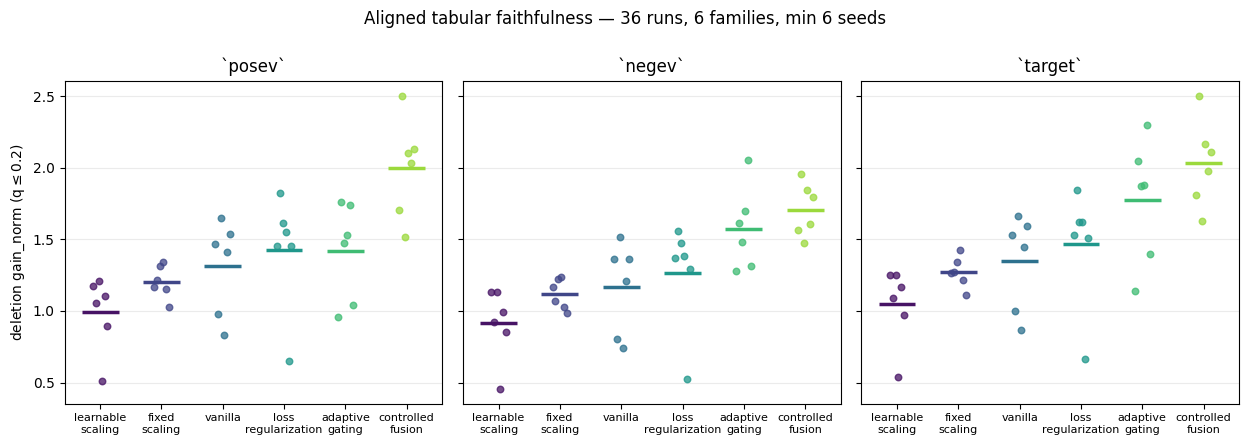

[report] 5 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/runs/_faithfulness
    faithfulness_aligned_signed_n140.csv
    faithfulness_by_family_n140.png
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv


In [ ]:
# @@SUBSET@@ 2/3 — aligned signed tabular faithfulness on the distinct-lesion sample (GPU)
from isic24 import xai_driver as xd
import gc, keras, time, os, pandas as pd

STRAT_ONLY_IMPL  = None         # None = every family
STRAT_ONLY_SEEDS = None         # e.g. [47]; None = every seed
STRAT_PER_FAMILY = None         # e.g. 1 for one run per family; None = every run
STRAT_DRY_RUN    = False        # False to run

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if STRAT_ONLY_IMPL:  _m = _m[_m.impl_name.isin(STRAT_ONLY_IMPL)]
if STRAT_ONLY_SEEDS: _m = _m[_m.seed.isin(STRAT_ONLY_SEEDS)]
if STRAT_PER_FAMILY: _m = _m.groupby("impl_name", sort=False).head(int(STRAT_PER_FAMILY))
_m = _m.reset_index(drop=True)

# run_id -> run_dir, re-anchored on ART_PATH: the master carries the paths of another machine.
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}

# 1.5 s/sample, measured with the four signed modes; changing SIGNED_MODES changes it.
SEC_PER_SAMPLE = 1.5
_todo, _done = xs.resume_report(_RD, "shap_tab", XAI_SUBSET_FP)
_est = len(_todo) * len(xai_subset_idx) * SEC_PER_SAMPLE
print(f"[subset] {len(_m)} runs selected | already done {len(_done)} | to do {len(_todo)}")
print(f"[subset] {len(xf.SIGNED_MODES)} modes x {len(xai_subset_idx)} samples "
      f"-> estimate {_est/60:.0f} min ({_est/3600:.1f} h)  [{_est/60/max(len(_todo),1):.1f} min/run]")
if _done:
    print(f"        (resume active: the {len(_done)} already done with fingerprint {XAI_SUBSET_FP} are skipped)")
if STRAT_DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set STRAT_DRY_RUN=False to run. ***")
else:
    _t0 = time.time()
    for _i, _r in _m.iterrows():
        _rd = _RD[_r.run_id]
        if xs.is_done(_rd, "shap_tab", XAI_SUBSET_FP):
            continue
        try:
            _model, _ = xd.load_run_model(_rd)
            # Returns (results, phi): unpack it, or mark_done is never reached.
            _o, _ = xf.aligned_signed_faithfulness(
                _model, _rd, int(_r.best_epoch), subset_idx=xai_subset_idx,
                verbose=False, q_maxes=tuple(Q_MAX_REPORT), resume=True)
            # The stamp is written only here, once the run is complete: that makes it resumable.
            xs.mark_done(_rd, "shap_tab", XAI_SUBSET_FP,
                         {"run_id": _r.run_id, "impl_name": _r.impl_name,
                          "setting_tag": _r.setting_tag, "n": len(xai_subset_idx),
                          "gains": {k: v for k, v in _o.items() if isinstance(v, float)}})
            print(f"[{_i+1}/{len(_m)}] {_r.run_id}: ok  ({(time.time()-_t0)/60:.0f} min total)", flush=True)
        except Exception as _e:
            print(f"[FAIL] {_r.run_id}: {type(_e).__name__}: {_e}", flush=True)
        finally:
            keras.backend.clear_session(); gc.collect()
    _todo, _done = xs.resume_report(_RD, "shap_tab", XAI_SUBSET_FP)
    print(f"\n[subset] done {len(_done)}/{len(_m)} in {(time.time()-_t0)/60:.0f} min"
          + (f" — {len(_todo)} left, re-run this cell to resume" if _todo else ""))

    # Cross-family report, no GPU. `central` is not optional: a family mean over all 45
    # fixed_scaling rows, endpoints included, means nothing.
    if not _todo:
        xs.report(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                  ART_PATH, kinds=("shap_tab",), central=CENTRAL_SETTINGS,
                  encoded_feature_names=encoded_feature_names)


[subset-lore] sample: 48 lesions, 24 pos / 24 neg  (balanced)
[subset-lore] sample fingerprint: lore-s0-n48-74cdab2fd5c0a603
[subset-lore] configuration: {'implementation': 'fixed-image-tabular-sa-v2', 'lore_sa_version': '1.1.3', 'seed_policy': 'base-plus-sample-position', 'rng_seed': 0, 'neigh_type': 'genetic', 'num_instances': 1000, 'mutpb': 0.5, 'init_mutpb': 0.3, 'threshold': 0.5, 'gen_kwargs': {}, 'fingerprint': 'lorecfg-64e024bb549eacaa'}
[subset-lore] 156 runs | seeded done 22 | accepted legacy 132 | to do 2
[subset-lore] families covered: 6/6 | LORE on /CPU:0

[warn] 6 selected runs have the tabular branch zeroed: a valid unimodal control, not a family representative.


,impl_name,setting_tag,run_id
6,fixed_scaling,a0p000,20260812-001020/seed_101__a0p000__e20
15,fixed_scaling,a0p000,20260812-001020/seed_47__a0p000__e20
24,fixed_scaling,a0p000,20260812-001020/seed_53__a0p000__e20
33,fixed_scaling,a0p000,20260812-001020/seed_71__a0p000__e20
42,fixed_scaling,a0p000,20260812-001020/seed_8__a0p000__e20
51,fixed_scaling,a0p000,20260812-001020/seed_90__a0p000__e20


I0000 00:00:1793575247.458178 4117116 service.cc:148] XLA service 0x78712c015d10 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793575247.458236 4117116 service.cc:156]   StreamExecutor device (0): Host, Default Version
I0000 00:00:1793575249.434687 4117116 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



[smoke] LORE reproducible on 20260812-060120/seed_90__ent1e-02__e20: 2 samples, every required column present, 0.5 min/sample
[smoke] projected 25 min/run -> 0.8 h for the 2 runs left


,impl_name,setting_tag,seed,run_id
0,vanilla,baseline,101,20260814-102807/seed_101__baseline__e20
1,vanilla,baseline,47,20260814-102807/seed_47__baseline__e20
2,vanilla,baseline,53,20260814-102807/seed_53__baseline__e20
3,vanilla,baseline,71,20260814-102807/seed_71__baseline__e20
4,vanilla,baseline,8,20260814-102807/seed_8__baseline__e20
...,...,...,...,...
151,adaptive_gating,base,90,20260812-060120/seed_90__base__e20
152,adaptive_gating,ent0e+00,90,20260812-060120/seed_90__ent0e+00__e20
153,adaptive_gating,ent1e-01,90,20260812-060120/seed_90__ent1e-01__e20
154,adaptive_gating,ent1e-02,90,20260812-060120/seed_90__ent1e-02__e20


[155/156] 20260812-060120/seed_90__ent1e-02__e20: {'LoreSACallback': 'ok'}  (22 min total)


2026-11-02 00:44:33,386 tensorflow   WARNING  5 out of the last 5 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7871e071ede0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


2026-11-02 00:44:37,730 tensorflow   WARNING  6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7871e071ede0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


[156/156] 20260812-060120/seed_90__ent1e-03__e20: {'LoreSACallback': 'ok'}  (43 min total)

[subset-lore] done 156/156 in 43 min (24 seeded, 132 accepted legacy)
  [ablations] lore: 12 unimodal endpoint runs excluded from the aggregate


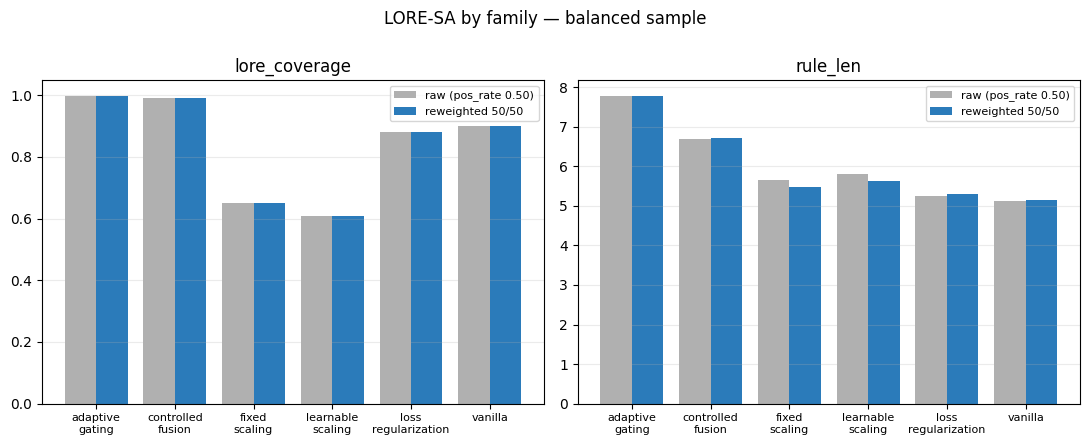

[report] 5 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/runs/_faithfulness
    lore_sa_quality_n48.csv
    lore_sa_quality_n48.png
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv


In [ ]:
# @@SUBSET@@ 3/3 — LORE on a balanced adopted sample (CPU)
from isic24 import xai_driver as xd
import gc, glob, keras, os, shutil, tempfile, time

STRAT_LORE_ONLY_IMPL  = None        # None = every family
STRAT_LORE_ONLY_SEEDS = None        # None = every seed
STRAT_LORE_ONLY_TAG   = None        # None = every setting
STRAT_LORE_PER_FAMILY = None        # None = every run
STRAT_LORE_PILOT      = False       # one central run per family (test before the full pass)
STRAT_LORE_DRY_RUN    = False
STRAT_LORE_N          = 48
LORE_SMOKE_N          = 2           # samples explained twice in scratch before the long pass
LORE_ON_CPU           = True        # the hot loop is the dense head and the tree, both CPU

xd.LORE_SA_DEVICE = "/CPU:0" if LORE_ON_CPU else None

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if STRAT_LORE_ONLY_IMPL:  _m = _m[_m.impl_name.isin(STRAT_LORE_ONLY_IMPL)]
if STRAT_LORE_ONLY_SEEDS: _m = _m[_m.seed.isin(STRAT_LORE_ONLY_SEEDS)]
if STRAT_LORE_ONLY_TAG:   _m = _m[_m.setting_tag.isin(STRAT_LORE_ONLY_TAG)]
if STRAT_LORE_PILOT:
    _m = _m[[_tag == CENTRAL_SETTINGS.get(_impl)
             for _impl, _tag in zip(_m.impl_name, _m.setting_tag)]]
    _m = _m.groupby("impl_name", sort=False).head(1)
    if _m.impl_name.nunique() != 6:
        raise RuntimeError("The LORE pilot must contain one central run from every family.")
elif STRAT_LORE_PER_FAMILY:
    _m = _m.groupby("impl_name", sort=False).head(int(STRAT_LORE_PER_FAMILY))
_m = _m.reset_index(drop=True)
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}

_lore_idx = xs.lore_subset(validation_df.target.values, xai_subset_idx, STRAT_LORE_N)
_lore_y = validation_df.target.values[_lore_idx]
xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)
_lore_sample_fp = xs.subset_fingerprint(
    xs.row_ids(validation_df), _lore_idx, seed=0, n=len(_lore_idx), kind="lore")
_lore_config = xd.lore_sa_config()
_lore_fp = f"{_lore_sample_fp}.{_lore_config['fingerprint']}"


def _lore_resume_state():
    todo, seeded, redo = xs.resume_verified(_RD, "lore_sa", _lore_fp, _lore_idx)
    if redo:
        raise RuntimeError(f"Seeded LORE stamps on another sample: {redo}")
    legacy = [rid for rid in todo if xs.is_done(_RD[rid], "lore_sa", XAI_SUBSET_FP)]
    invalid = [rid for rid in legacy
               if xs.sample_matches(_RD[rid], "lore_sa", _lore_idx) is not True]
    if invalid:
        raise RuntimeError(f"Legacy LORE stamps with unverifiable sample identity: {invalid}")
    return [rid for rid in todo if rid not in legacy], seeded, legacy


_todo, _done_seeded, _done_legacy = _lore_resume_state()
print(f"[subset-lore] sample: {len(_lore_idx)} lesions, "
      f"{int(_lore_y.sum())} pos / {int((1-_lore_y).sum())} neg  (balanced)")
print(f"[subset-lore] sample fingerprint: {_lore_sample_fp}")
print(f"[subset-lore] configuration: {_lore_config}")
print(f"[subset-lore] {len(_m)} runs | seeded done {len(_done_seeded)} | "
      f"accepted legacy {len(_done_legacy)} | to do {len(_todo)}")
print(f"[subset-lore] families covered: {_m.impl_name.nunique()}/6 | "
      f"LORE on {xd.LORE_SA_DEVICE or 'the default device = GPU'}")

_deg = _m[(_m.impl_name == "fixed_scaling") & (_m.setting_tag == "a0p000")]
if len(_deg):
    print(f"\n[warn] {len(_deg)} selected runs have the tabular branch zeroed: "
          "a valid unimodal control, not a family representative.")
    display(_deg[["impl_name", "setting_tag", "run_id"]])

# Exercise the real engine twice; only timing columns may differ.
if _todo and not STRAT_LORE_DRY_RUN:
    _sm_row = _m[_m.run_id == _todo[0]].iloc[0]
    xd.LORE_SA_KWARGS.update(max_explain_samples=int(LORE_SMOKE_N),
                             subset_idx=_lore_idx[:int(LORE_SMOKE_N)])
    _sm_frames, _t = [], time.time()
    for _rep in range(2):
        _sm_dir = tempfile.mkdtemp(prefix=f"lore_smoke_{_rep}_")
        try:
            _o = xd.run_posthoc_xai(
                _RD[_todo[0]], engines=("lore",), best_epoch=int(_sm_row.best_epoch),
                best_val_auc=float(_sm_row.best_val_auc), overwrite=True,
                verbose=False, xai_dir=_sm_dir)
            _bad = {k: v for k, v in (_o or {}).items() if str(v) != "ok"}
            assert _o and not _bad, (
                f"[smoke] LORE failed on {_todo[0]} repetition {_rep}: "
                f"{_bad or 'no engine ran'}")
            _csv = glob.glob(os.path.join(
                _sm_dir, "lore_sa", "*", "lore_sa_persample_*.csv"))
            assert _csv, f"[smoke] LORE reported ok but wrote no CSV under {_sm_dir}"
            _sm_frames.append(pd.read_csv(_csv[0]))
        finally:
            shutil.rmtree(_sm_dir, ignore_errors=True)
    xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)

    _need = {"i", "rng_seed", "true_label", "rule_len", "neigh_n_classes",
             "neigh_pos_rate", "neigh_unique_frac", "fid_cv_bacc"}
    for _sm in _sm_frames:
        assert _need <= set(_sm.columns) and len(_sm) == int(LORE_SMOKE_N), (
            f"[smoke] the per-sample CSV is not what @LORE_SECTION@ aggregates: "
            f"{len(_sm)} rows, missing {sorted(_need - set(_sm.columns))}")
    _timing = ["seconds", "min_per_sample"]
    pd.testing.assert_frame_equal(
        _sm_frames[0].drop(columns=_timing, errors="ignore"),
        _sm_frames[1].drop(columns=_timing, errors="ignore"),
        check_dtype=False, check_exact=True)
    _sec = (time.time() - _t) / (2 * int(LORE_SMOKE_N))
    print(f"\n[smoke] LORE reproducible on {_sm_row.run_id}: {LORE_SMOKE_N} samples, "
          f"every required column present, {_sec/60:.1f} min/sample")
    print(f"[smoke] projected {len(_lore_idx)*_sec/60:.0f} min/run -> "
          f"{len(_todo)*len(_lore_idx)*_sec/3600:.1f} h for the {len(_todo)} runs left")

display(_m[["impl_name", "setting_tag", "seed", "run_id"]])

if STRAT_LORE_DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set STRAT_LORE_DRY_RUN=False to run. ***")
else:
    xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)
    _t0 = time.time()
    try:
        for _i, _r in _m.iterrows():
            if _r.run_id not in _todo:
                continue
            _rd = _RD[_r.run_id]
            try:
                _o = xd.run_posthoc_xai(
                    _rd, engines=("lore",), best_epoch=int(_r.best_epoch),
                    best_val_auc=float(_r.best_val_auc), overwrite=True, verbose=False)
                _bad = {_k: _v for _k, _v in (_o or {}).items() if str(_v) != "ok"}
                if _bad or not _o:
                    print(f"[FAIL] {_r.run_id}: {_bad or 'no engine ran'}", flush=True)
                    continue
                xs.mark_done(
                    _rd, "lore_sa", _lore_fp,
                    {"run_id": _r.run_id, "impl_name": _r.impl_name,
                     "setting_tag": _r.setting_tag, "n": int(len(_lore_idx)),
                     "n_pos": int(_lore_y.sum()),
                     "sample_fingerprint": _lore_sample_fp,
                     "parent_sample_fingerprint": XAI_SUBSET_FP,
                     "lore_config": _lore_config, "result": str(_o)})
                print(f"[{_i+1}/{len(_m)}] {_r.run_id}: {_o}  "
                      f"({(time.time()-_t0)/60:.0f} min total)", flush=True)
            except Exception as _e:
                print(f"[FAIL] {_r.run_id}: {type(_e).__name__}: {_e}", flush=True)
            finally:
                keras.backend.clear_session(); gc.collect()
    finally:
        xd.LORE_SA_KWARGS.pop("subset_idx", None)

    _todo, _done_seeded, _done_legacy = _lore_resume_state()
    _done = _done_seeded + _done_legacy
    print(f"\n[subset-lore] done {len(_done)}/{len(_m)} in {(time.time()-_t0)/60:.0f} min "
          f"({len(_done_seeded)} seeded, {len(_done_legacy)} accepted legacy)"
          + (f" — {len(_todo)} left, re-run to resume" if _todo else ""))
    if not _todo:
        xs.report(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                  ART_PATH, kinds=("lore_sa",), central=CENTRAL_SETTINGS,
                  encoded_feature_names=encoded_feature_names,
                  lore_idx={len(_lore_idx): _lore_idx})

In [ ]:
# @@FAITH_LOOP@@ — deletion/insertion on the adopted sample, both tabular attributors (GPU)
from isic24 import xai_driver as xd

FAITH_OUT_DIR = os.path.join(RUNS_PATH, "_faithfulness")
os.makedirs(FAITH_OUT_DIR, exist_ok=True)

_plan = []
for _impl, _study in CANONICAL.items():
    if FAITH_ONLY_IMPL and _impl not in FAITH_ONLY_IMPL:
        continue
    for _sp in sorted(glob.glob(os.path.join(_study, "*", "*", "single_run_summary.csv"))):
        _row, _rd = pd.read_csv(_sp).iloc[0], os.path.dirname(_sp)
        # Every run is refused HERE if it was trained against another space, before the GPU
        # is taken: the same check `load_run_model` makes one checkpoint at a time.
        xd.assert_run_feature_space(json.load(open(os.path.join(_rd, "config.json"))),
                                    _rd, FEATURE_SPACE_FILE, FEATURE_SPACE_FP)
        _js = {"aligned": os.path.join(_rd, "xai", "faithfulness", "faithfulness.json"),
               "gradient": os.path.join(_rd, "xai", "faith_gradient", "faithfulness.json")}
        _plan.append({"impl_name": _impl, "setting_tag": _row.setting_tag, "seed": int(_row.seed),
                      "run_id": _row.run_id,
                      "best_epoch": int(_row.best_epoch), "best_val_auc": float(_row.best_val_auc),
                      "run_dir": _rd, "js": _js,
                      "todo": [k for k, f in _js.items() if FAITH_OVERWRITE or not os.path.exists(f)
                               or (k == "gradient" and xs.branch_off(_impl, _row.setting_tag) != "tabular"
                                   and json.load(open(f)).get("encoded_feature_names") != encoded_feature_names)]})

faith_plan = pd.DataFrame(_plan).head(FAITH_MAX_RUNS or len(_plan))
print(f"[FAITH] {len(faith_plan)} canonical runs | {int((faith_plan.todo.map(len) > 0).sum())} with work left "
      f"| sample {XAI_SUBSET_FP} (n={len(xai_subset_idx)}), the same rows for every run")
print(f"[FAITH] aligned={sum('aligned' in todo for todo in faith_plan.todo)} | "
      f"gradient={sum('gradient' in todo for todo in faith_plan.todo)} | "
      f"reuse={sum(not todo for todo in faith_plan.todo)} | "
      f"overwrite={FAITH_OVERWRITE} | dry_run={FAITH_DRY_RUN}")
if FAITH_DRY_RUN:
    display(faith_plan.drop(columns=["js"]))
    raise SystemExit("FAITH_DRY_RUN=True: no models loaded.")

# The gradient ranking is READ from disk, never recomputed: without SHAP on the adopted sample
# there is nothing to rank with, and finding out one model at a time costs a night.
_no_shap = [r.run_dir for r in faith_plan.itertuples()
            if "gradient" in r.todo and not glob.glob(
                os.path.join(r.run_dir, "xai", "shap_tab", "epoch_*", "*.npz"))]
assert not _no_shap, (f"{len(_no_shap)} runs carry no SHAP on this sample: run SUBSET 1/3 "
                      f"with the SHAP engine first — e.g. {_no_shap[0]}")


def _grad_cols(d):   # the gradient contrast, prefixed so both attributors sit in one row
    return {f"grad_{k}": v for k, v in d.items() if k.startswith("faithfulness_") or k == "tab_ranking"}


faith_rows = []
for _r in faith_plan.itertuples():
    _t0 = time.time()
    if _r.todo:
        keras.backend.clear_session()
        model, _ = xd.load_run_model(_r.run_dir)
    if "aligned" in _r.todo:
        _raw, _im, _ = xf._build_faith_subset()
        _phi, _ = xf.aligned_tab_attributions(model, _raw, _im, background="baseline")
        res = explanation_faithfulness(model, _r.run_dir, _r.best_epoch,
                                       methods=("tabular", "image", "joint"),
                                       tab_imp_override=np.abs(_phi),
                                       save=True, verbose=False, allow_clobber=FAITH_OVERWRITE)
    else:
        res = {k: v for k, v in json.load(open(_r.js["aligned"])).items()
               if k not in ("curves", "q_grid")}
    if "gradient" in _r.todo:
        res.update(_grad_cols(explanation_faithfulness(
            model, _r.run_dir, _r.best_epoch, methods=("tabular", "joint"),
            out_dir=os.path.dirname(_r.js["gradient"]), save=True, verbose=False,
            allow_clobber=FAITH_OVERWRITE)))
    else:
        res.update(_grad_cols(json.load(open(_r.js["gradient"]))))
    if _r.todo:
        res["faith_seconds"] = round(time.time() - _t0, 2)
        keras.backend.clear_session(); gc.collect()
    faith_rows.append({**{c: getattr(_r, c) for c in
                          ("run_id", "impl_name", "setting_tag", "seed", "best_val_auc", "run_dir")},
                       **{k: v for k, v in res.items() if not isinstance(v, (list, dict))}})
    print(f"  {'+'.join(_r.todo) or 'reuse':>17} {_r.impl_name:>18}/{_r.setting_tag:<14} "
          f"seed {_r.seed:<4} del={res['faithfulness_gain']:+.4f} ({res.get('faith_seconds', '-')}s)")

faith_df = pd.DataFrame(faith_rows)
_out_csv = os.path.join(FAITH_OUT_DIR, "combined_faithfulness.csv")
if os.path.exists(_out_csv):          # a partial pass must not truncate the registry
    _prev = pd.read_csv(_out_csv)
    faith_df = pd.concat([_prev[~_prev.run_dir.isin(faith_df.run_dir)], faith_df], ignore_index=True)
xs.stamp_aggregate(_out_csv, faith_df.run_id, attributors=("aligned", "gradient"))
faith_df.to_csv(_out_csv, index=False)
print(f"[FAITH] {faith_df.shape} -> {_out_csv}")
display(faith_df.head(20))

[FAITH] 156 canonical runs | 24 with work left | sample unique-equal-s0-n140-4e93cb16fae6032a (n=140), the same rows for every run
[FAITH] aligned=24 | gradient=24 | reuse=132 | overwrite=False | dry_run=False
              reuse            vanilla/baseline       seed 101  del=+0.7164 (-s)
              reuse            vanilla/baseline       seed 47   del=+0.4403 (-s)
              reuse            vanilla/baseline       seed 53   del=+0.8776 (-s)
              reuse            vanilla/baseline       seed 71   del=+0.2770 (-s)
              reuse            vanilla/baseline       seed 8    del=+0.7640 (-s)
              reuse            vanilla/baseline       seed 90   del=+0.6890 (-s)
              reuse      fixed_scaling/a0p000         seed 101  del=+0.3576 (-s)
              reuse      fixed_scaling/a0p125         seed 101  del=+0.6368 (-s)
              reuse      fixed_scaling/a0p250         seed 101  del=+0.7323 (-s)
              reuse      fixed_scaling/a0p375         seed 10

I0000 00:00:1793577992.428986 4117113 service.cc:148] XLA service 0x787140ddd7d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793577992.429015 4117113 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
I0000 00:00:1793577993.075959 4117113 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1793577993.860126 4117113 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793577994.055763 4117113 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793577994.439141 4117113 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793577994.632875 41

   aligned+gradient    adaptive_gating/ent0e+00       seed 101  del=+0.7133 (264.6s)
   aligned+gradient    adaptive_gating/ent1e-01       seed 101  del=+0.7559 (249.53s)
   aligned+gradient    adaptive_gating/ent1e-02       seed 101  del=+0.6859 (248.84s)
   aligned+gradient    adaptive_gating/ent1e-03       seed 101  del=+0.6706 (247.65s)
              reuse    adaptive_gating/base           seed 47   del=+0.6047 (-s)
   aligned+gradient    adaptive_gating/ent0e+00       seed 47   del=+0.6013 (248.46s)
   aligned+gradient    adaptive_gating/ent1e-01       seed 47   del=+0.5686 (248.61s)
   aligned+gradient    adaptive_gating/ent1e-02       seed 47   del=+1.1235 (249.47s)
   aligned+gradient    adaptive_gating/ent1e-03       seed 47   del=+0.6154 (248.27s)
              reuse    adaptive_gating/base           seed 53   del=+0.8241 (-s)
   aligned+gradient    adaptive_gating/ent0e+00       seed 53   del=+1.1110 (248.66s)
   aligned+gradient    adaptive_gating/ent1e-01       seed 53   d

,run_id,impl_name,setting_tag,seed,best_val_auc,run_dir,n_faith_samples,blur_sigma,tab_ranking,deletion_auc_tabular_exp,...,grad_tab_ranking,grad_faithfulness_tabular_del_gain,grad_faithfulness_tabular_ins_gain,grad_faithfulness_joint_del_gain,grad_faithfulness_joint_ins_gain,grad_faithfulness_primary_method,grad_faithfulness_gain,grad_faithfulness_gain_ci_lo,grad_faithfulness_gain_ci_hi,faith_seconds
0,20260814-102807/seed_101__baseline__e20,vanilla,baseline,101,0.948197,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.543564,...,shap_gradient,0.277545,0.298717,0.644993,1.080713,joint,0.644993,0.504968,0.793509,NaN
1,20260814-102807/seed_47__baseline__e20,vanilla,baseline,47,0.931543,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.316296,...,shap_gradient,0.146731,0.144762,0.341904,0.365391,joint,0.341904,0.237551,0.457510,NaN
2,20260814-102807/seed_53__baseline__e20,vanilla,baseline,53,0.953111,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.588891,...,shap_gradient,0.230465,0.222917,0.737883,0.879470,joint,0.737883,0.571239,0.926948,NaN
3,20260814-102807/seed_71__baseline__e20,vanilla,baseline,71,0.935051,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.178075,...,shap_gradient,0.061796,0.071815,0.222066,0.315047,joint,0.222066,0.136808,0.313648,NaN
4,20260814-102807/seed_8__baseline__e20,vanilla,baseline,8,0.934862,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.478321,...,shap_gradient,0.201333,0.188610,0.653552,0.828835,joint,0.653552,0.483841,0.836500,NaN
5,20260814-102807/seed_90__baseline__e20,vanilla,baseline,90,0.945562,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.543238,...,shap_gradient,0.195492,0.200022,0.526100,0.953906,joint,0.526100,0.362621,0.701717,NaN
6,20260812-001020/seed_101__a0p000__e20,fixed_scaling,a0p000,101,0.925738,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.000000,...,shap_gradient,0.000000,0.000000,0.360912,0.633353,joint,0.360912,0.265595,0.465137,NaN
7,20260812-001020/seed_101__a0p125__e20,fixed_scaling,a0p125,101,0.945968,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.177694,...,shap_gradient,0.088134,0.096571,0.601059,0.655820,joint,0.601059,0.463451,0.753151,NaN
8,20260812-001020/seed_101__a0p250__e20,fixed_scaling,a0p250,101,0.947870,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.248458,...,shap_gradient,0.109985,0.126114,0.688837,0.858083,joint,0.688837,0.535053,0.855785,NaN
9,20260812-001020/seed_101__a0p375__e20,fixed_scaling,a0p375,101,0.944145,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,140,8.0,override,0.373174,...,shap_gradient,0.193242,0.209379,0.584960,1.088548,joint,0.584960,0.435157,0.746234,NaN


In [ ]:
# @@LOGIT_DECOMP@@ — exact logit decomposition: z = bias + image term + tabular term, no residual
# Loads one checkpoint per run and does a single forward pass over the adopted sample; the guard raises if the split does not reconstruct the prediction.

from isic24 import xai_logit as xlog

LOGIT_ALL_RUNS  = False         # False = the six central settings | True = every canonical run
LOGIT_OVERWRITE = False         # True = re-decompose the runs that already hold a per-sample table

_lmaster = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
_central = None if LOGIT_ALL_RUNS else CENTRAL_SETTINGS
_by_run, _by_family, _per_sample = xlog.decompose_study(
    _lmaster, ART_PATH, subset_idx=xai_subset_idx, central=_central, overwrite=LOGIT_OVERWRITE)

print("\n=== image share of the logit, by family ===")
print(_by_family.to_string(index=False))

# Three ways to ask "how much does the model use the image", side by side.
_m = _lmaster if _central is None else _lmaster[
    [bool(_central.get(i) == s) for i, s in zip(_lmaster.impl_name, _lmaster.setting_tag)]]
_cmp = (_by_run.groupby("impl_name")["mean_image_abs_share_descriptive"].mean().rename("logit_share")
        .to_frame()
        .join(_m.groupby("impl_name")[["img_drop_auc", "tab_drop_auc", "base_auc"]].mean()))
_cmp["ablation_share"] = _cmp.img_drop_auc / (_cmp.img_drop_auc + _cmp.tab_drop_auc)
print("\n=== three measures of reliance ===")
print(_cmp[["logit_share", "ablation_share", "img_drop_auc", "tab_drop_auc"]].round(3).to_string())
print(f"Spearman(logit_share, ablation_share) over {len(_cmp)} families: "
      f"{_cmp.logit_share.corr(_cmp.ablation_share, method='spearman'):+.3f}")

# Aggregating over both classes hides the asymmetry the strata already show.
print("\n=== per class: image share and target-aligned contribution ===")
print(_by_run.groupby("impl_name")[xlog.CLASS_COLS].mean().round(3).to_string())

# Consistency with the June vanilla decomposition (128 samples, same baselines).
_june = os.path.join(ART_PATH, "diagnostics", "vanilla_logit_contributions",
                     "20260604-210304", "vanilla_logit_contributions_by_seed.csv")
if os.path.exists(_june):
    _j = pd.read_csv(_june)["mean_image_abs_share_descriptive"].mean()
    _v = _by_run.loc[_by_run.impl_name == "vanilla", "mean_image_abs_share_descriptive"].mean()
    print(f"\n[check] vanilla image share — June n=128: {_j:.3f} | this sample n={len(xai_subset_idx)}: {_v:.3f}")

  [ablations] logit decomposition: 12 unimodal endpoint runs excluded from the aggregate
[1/36]              vanilla   baseline share 0.534  delta 1.2e-07
[2/36]              vanilla   baseline share 0.690  delta 1.2e-07
[3/36]              vanilla   baseline share 0.476  delta 1.2e-07
[4/36]              vanilla   baseline share 0.659  delta 1.2e-07
[5/36]              vanilla   baseline share 0.610  delta 1.5e-07
[6/36]              vanilla   baseline share 0.621  delta 1.2e-07
[7/36]        fixed_scaling     a0p500 share 0.675  delta 1.2e-07
[8/36]        fixed_scaling     a0p500 share 0.751  delta 1.2e-07
[9/36]        fixed_scaling     a0p500 share 0.490  delta 1.2e-07
[10/36]        fixed_scaling     a0p500 share 0.708  delta 1.2e-07
[11/36]        fixed_scaling     a0p500 share 0.672  delta 1.2e-07
[12/36]        fixed_scaling     a0p500 share 0.694  delta 1.2e-07
[13/36]    learnable_scaling init_a0p500 share 0.501  delta 1.2e-07
[14/36]    learnable_scaling init_a0p500 share 0

In [ ]:
# @@GAMMA_ATTENDANCE@@ — attendance against the fusion bias, re-derived from the saved decomposition
_g_by_run, _g_by_family = xlog.gamma_curve(_per_sample, ART_PATH, master=_lmaster)

_neutral = _g_by_run[_g_by_run.delta == 0.0].set_index("run_id")["mean_image_abs_share_descriptive"]
_diff = (_by_run.set_index("run_id")["mean_image_abs_share_descriptive"] - _neutral).abs().max()
print(f"[check] delta=0 reproduces the measured decomposition: max |diff| = {_diff:.2e}")

print("\n=== image share of the logit against the fusion bias ===")
print(_g_by_family.pivot(index="impl_name", columns="gamma_tab",
                         values="mean_image_abs_share_descriptive__mean").round(3).to_string())

print("\n=== sample AUC against the fusion bias (adopted XAI sample, NOT the validation set) ===")
print(_g_by_family.pivot(index="impl_name", columns="gamma_tab",
                         values="sample_auc__mean").round(4).to_string())

_peak = _g_by_run.loc[_g_by_run.groupby(["impl_name", "seed"])["sample_auc"].idxmax()]
print("\n=== where each run's sample AUC peaks, by family ===")
print(_peak.groupby("impl_name")["delta"].agg(["mean", "std", "count"]).round(3).to_string())


[check] delta=0 reproduces the measured decomposition: max |diff| = 1.07e-08

=== image share of the logit against the fusion bias ===
gamma_tab            0.500  0.625  0.750  0.875  1.000  1.125  1.250  1.375  1.500
impl_name                                                                         
adaptive_gating      0.899  0.871  0.842  0.810  0.776  0.738  0.696  0.649  0.595
controlled_fusion    0.737  0.694  0.652  0.612  0.570  0.528  0.484  0.437  0.386
fixed_scaling        0.818  0.781  0.744  0.705  0.665  0.622  0.576  0.525  0.468
learnable_scaling    0.801  0.765  0.729  0.693  0.656  0.616  0.574  0.526  0.473
loss_regularization  0.765  0.723  0.682  0.642  0.601  0.558  0.514  0.466  0.414
vanilla              0.763  0.721  0.680  0.640  0.598  0.556  0.511  0.464  0.411

=== sample AUC against the fusion bias (adopted XAI sample, NOT the validation set) ===
gamma_tab             0.500   0.625   0.750   0.875   1.000   1.125   1.250   1.375   1.500
impl_name           

### Family diagnostics — gate weights, ablation, calibration, gamma sweep

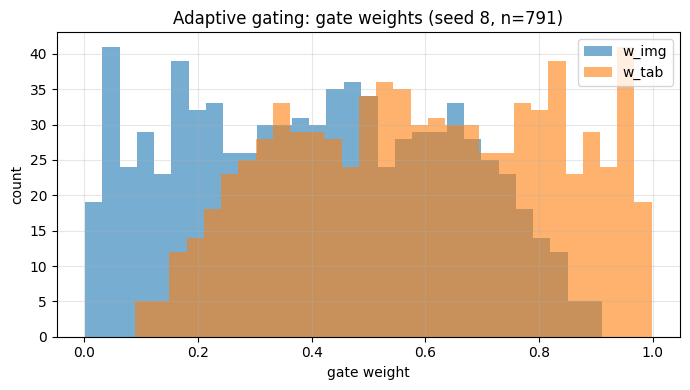

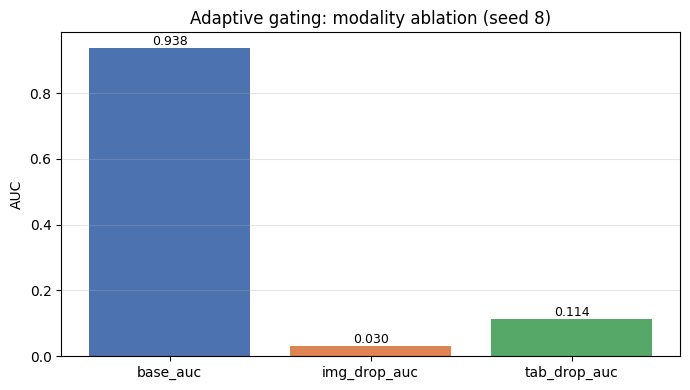

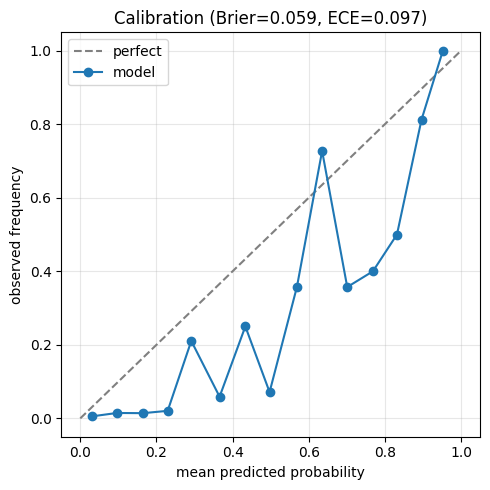

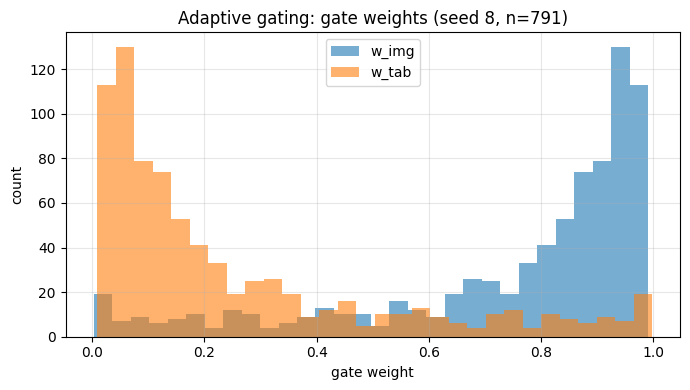

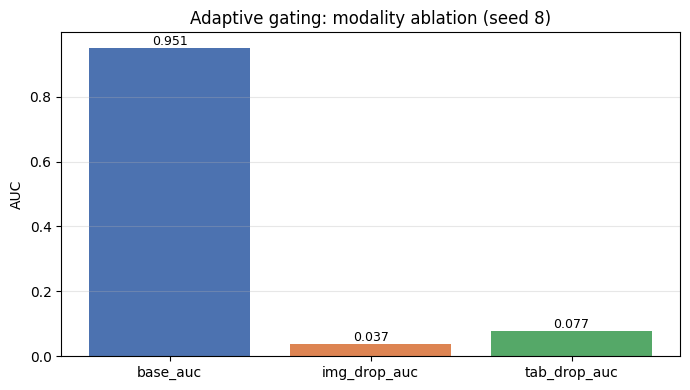

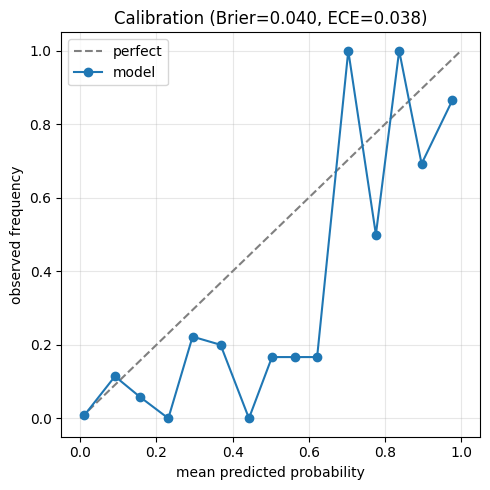

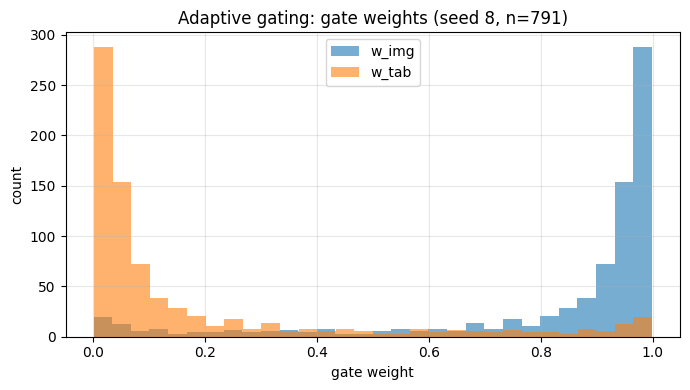

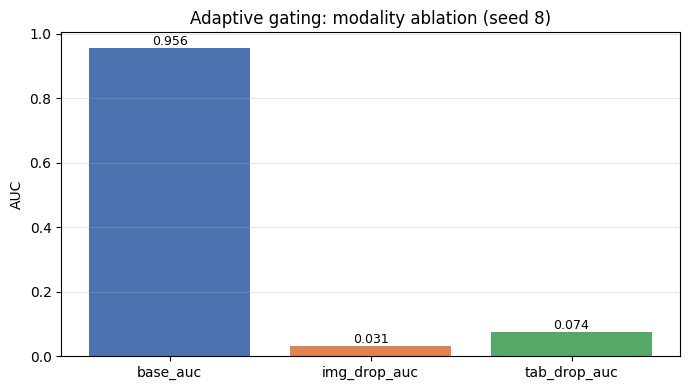

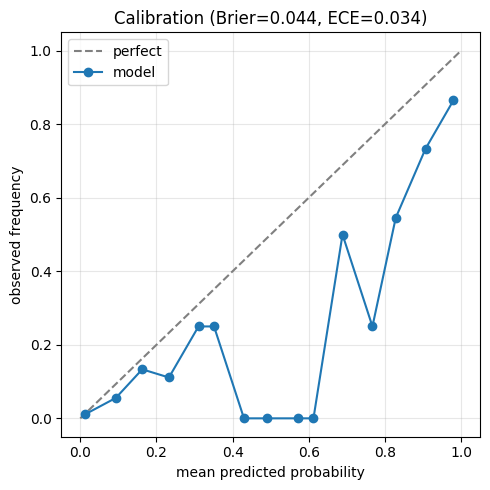

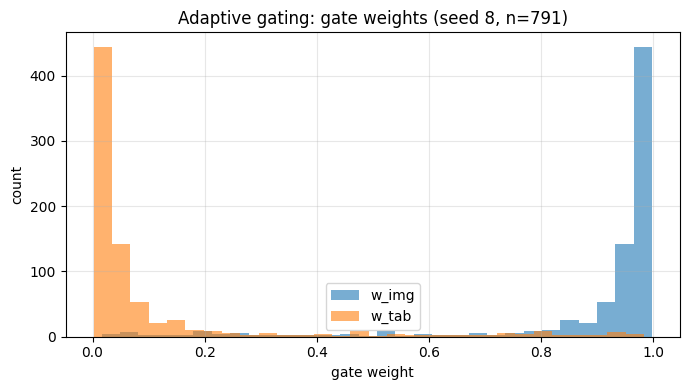

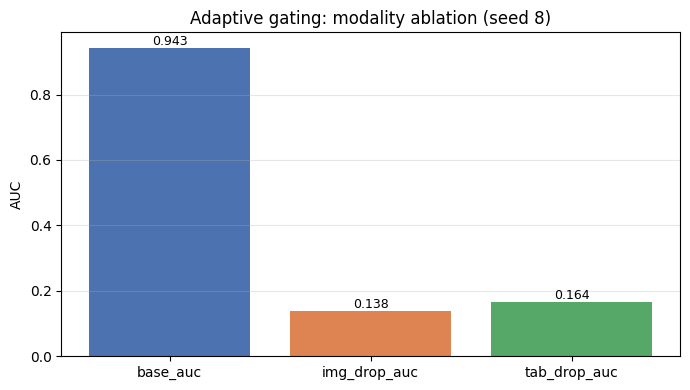

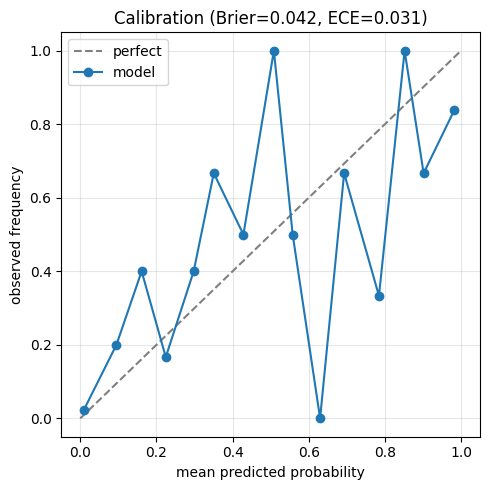

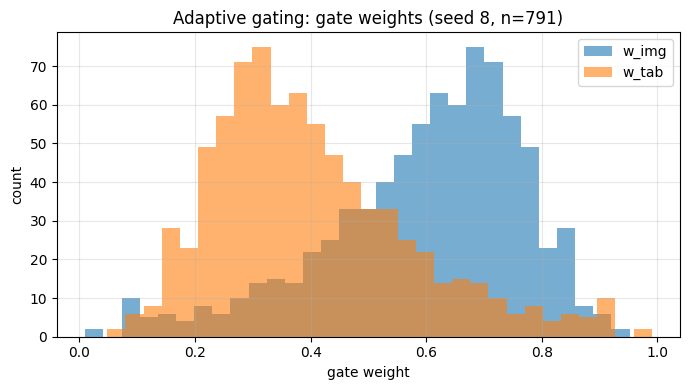

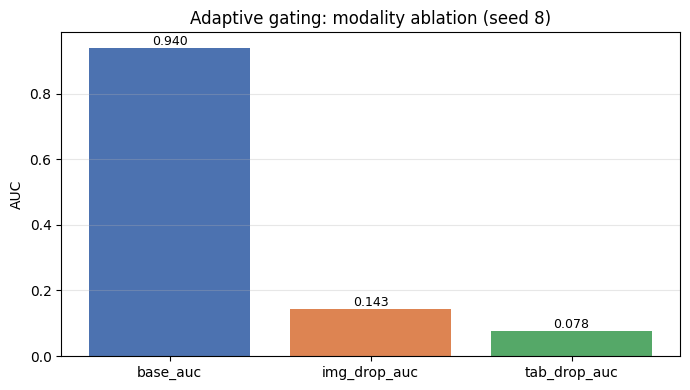

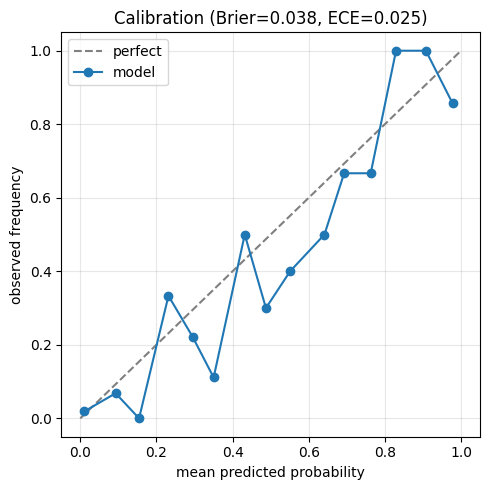

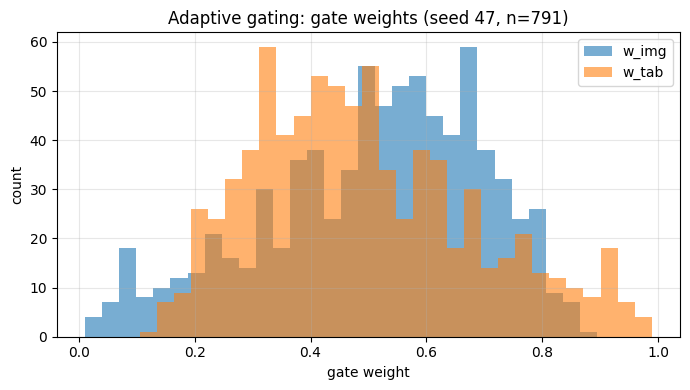

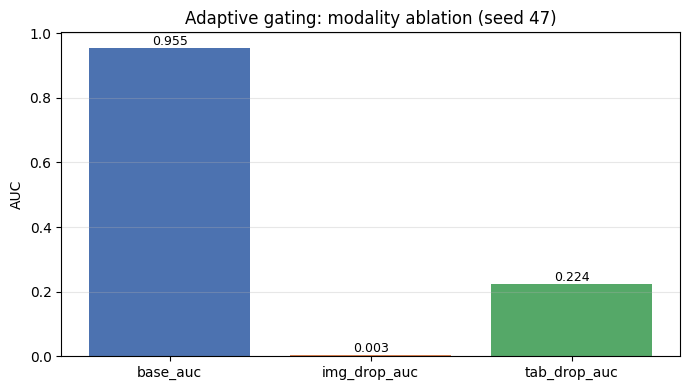

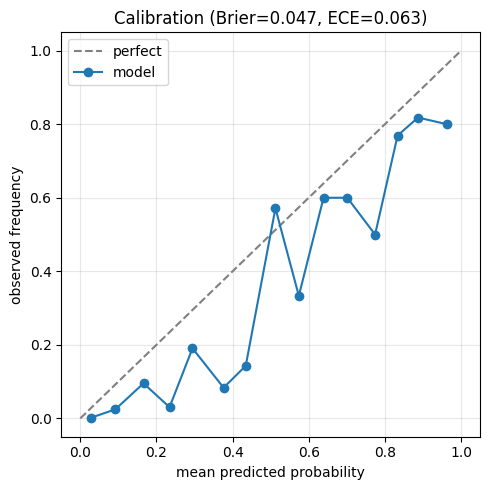

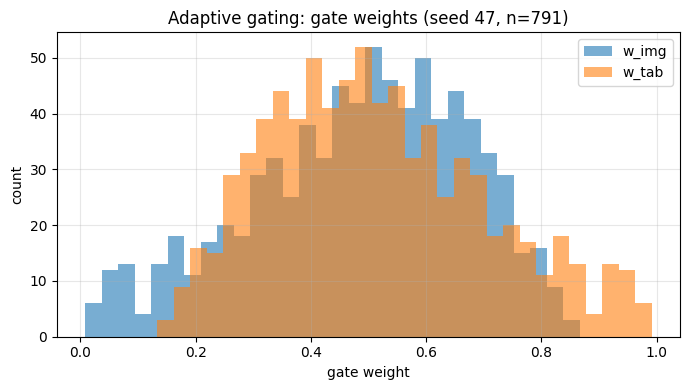

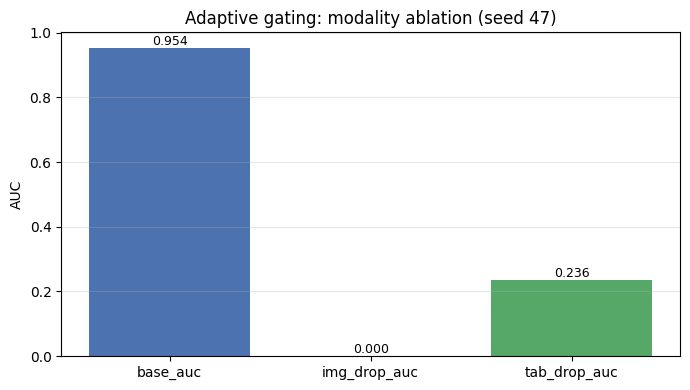

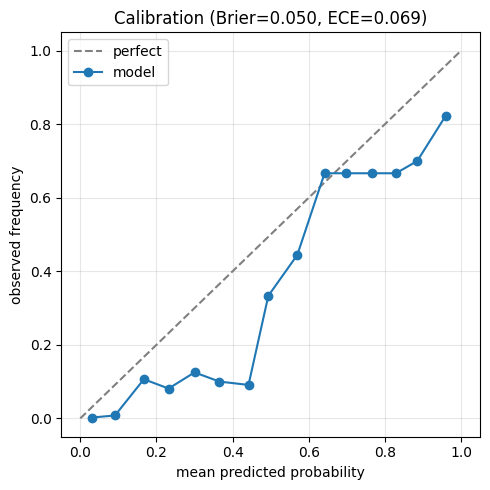

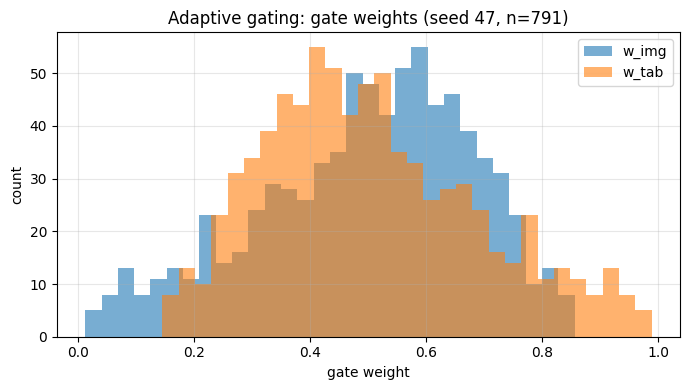

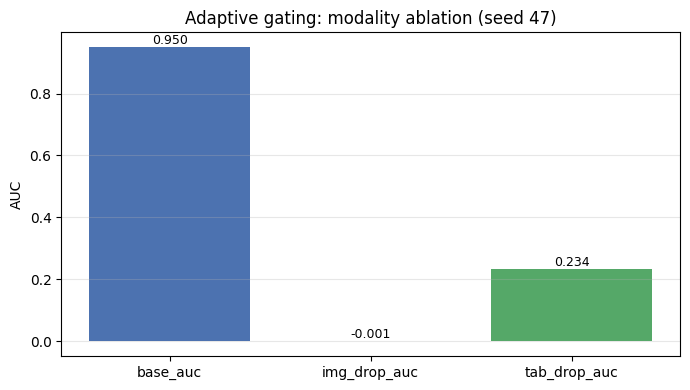

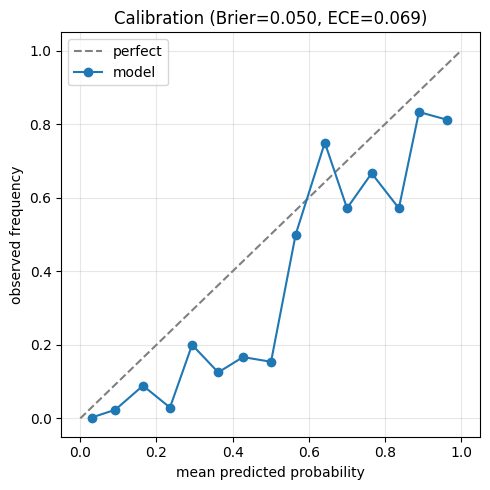

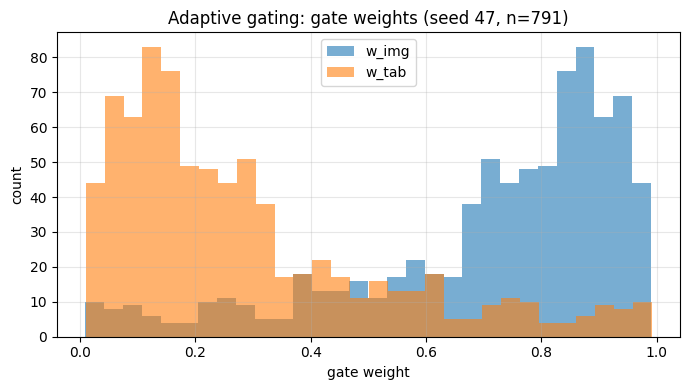

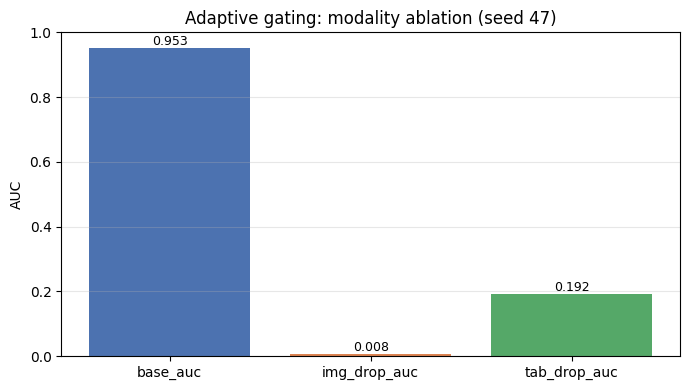

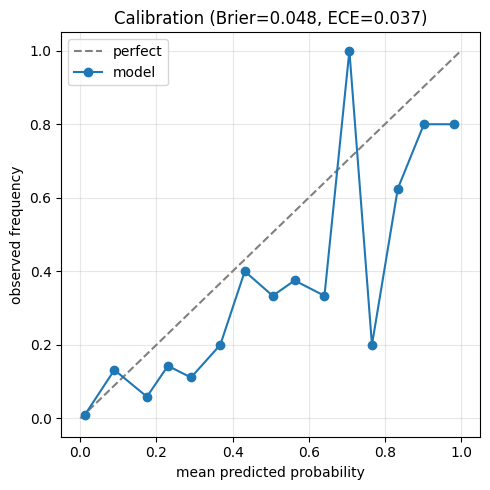

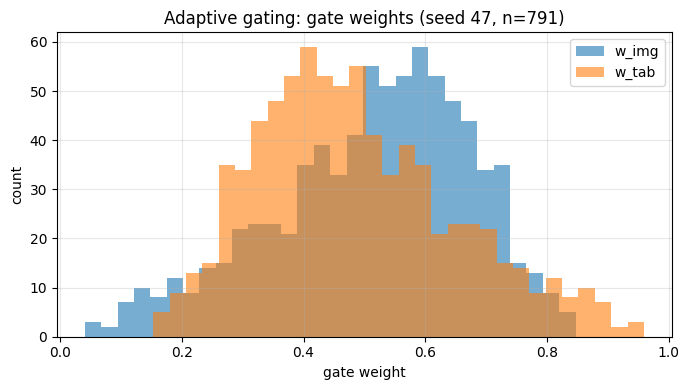

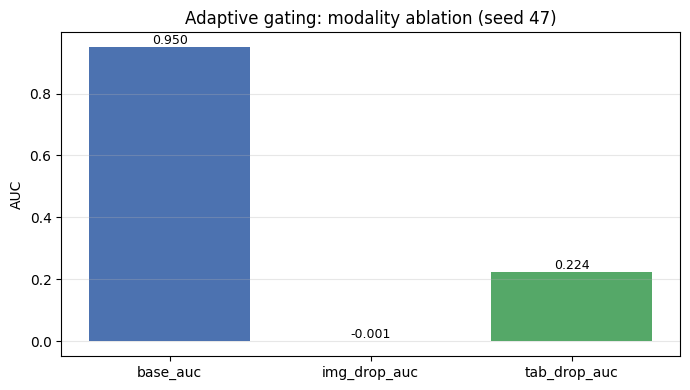

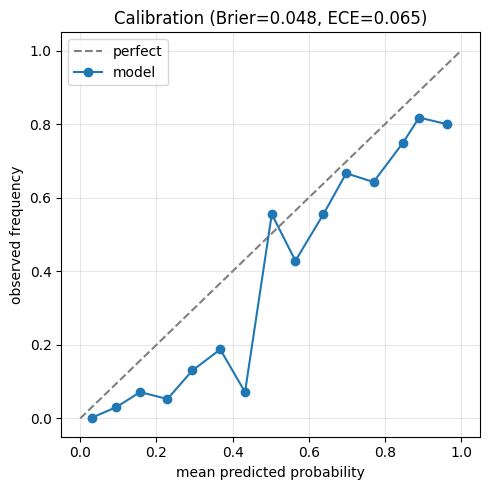

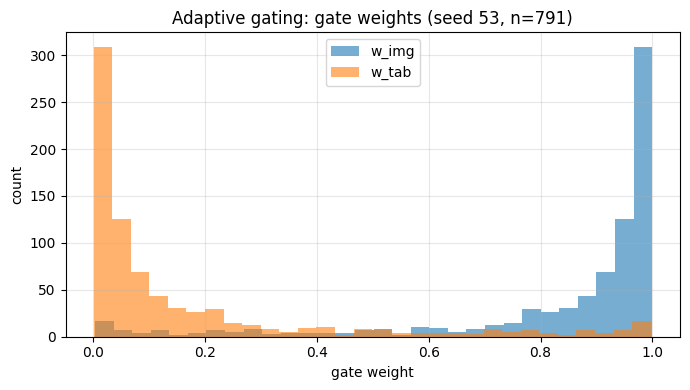

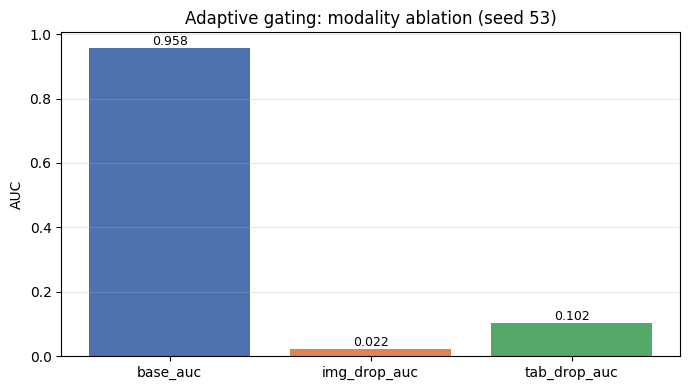

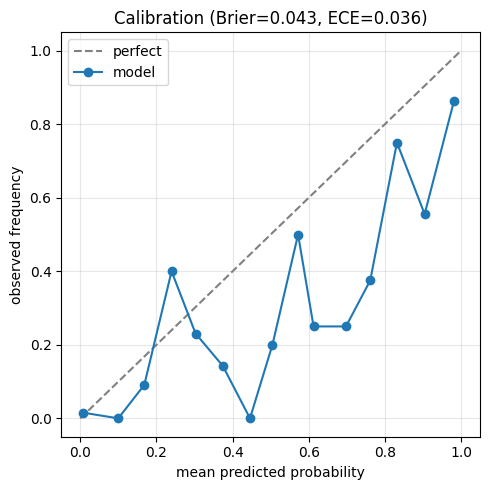

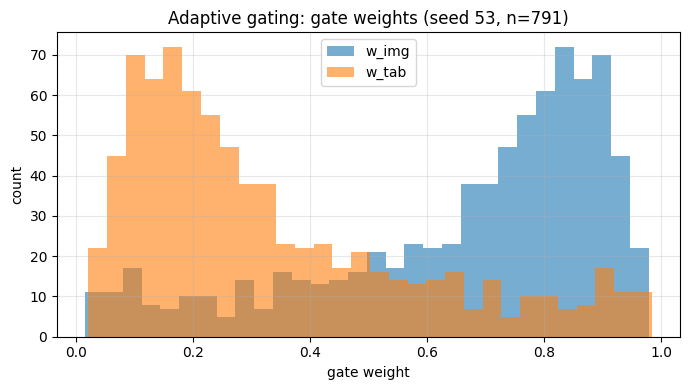

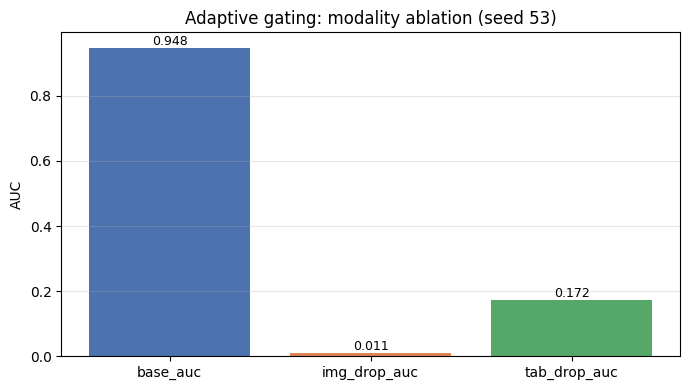

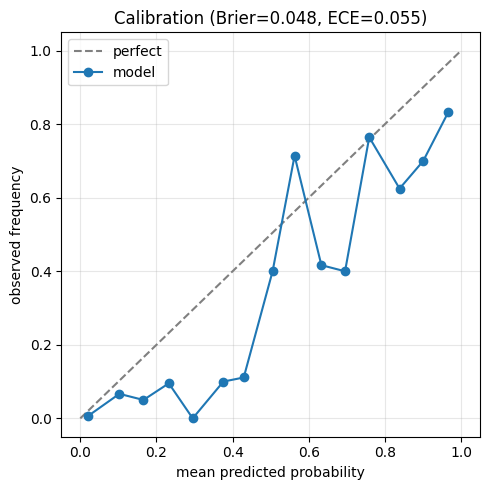

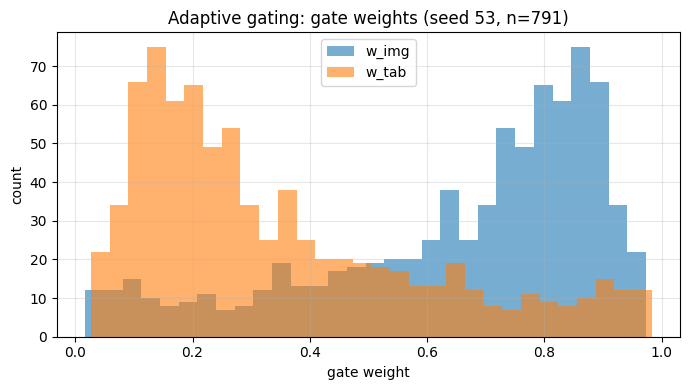

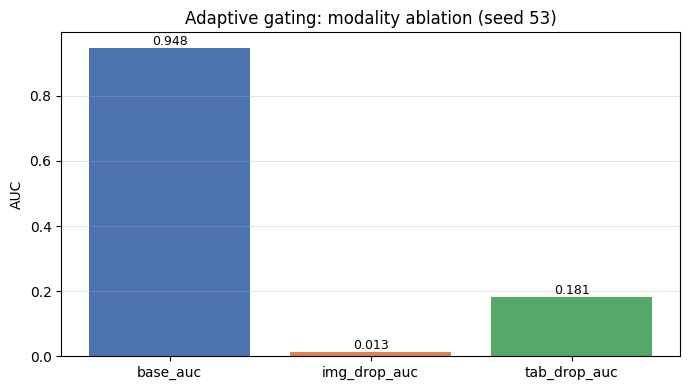

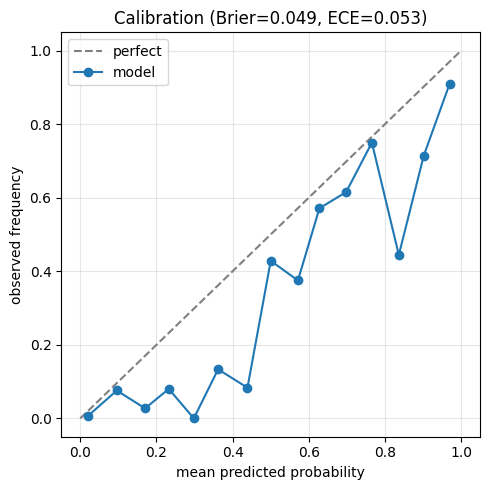

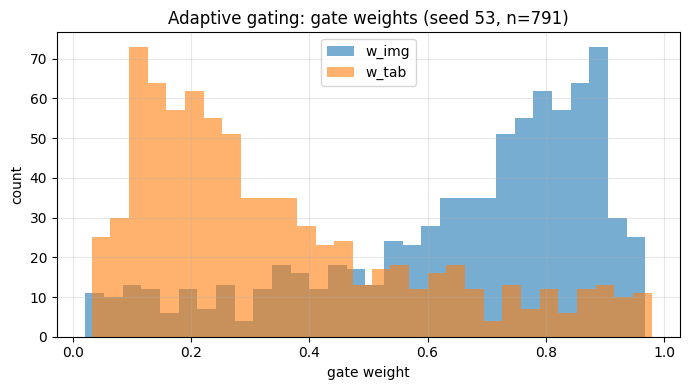

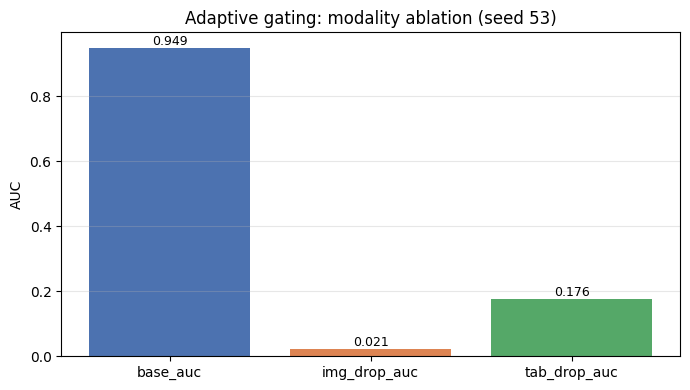

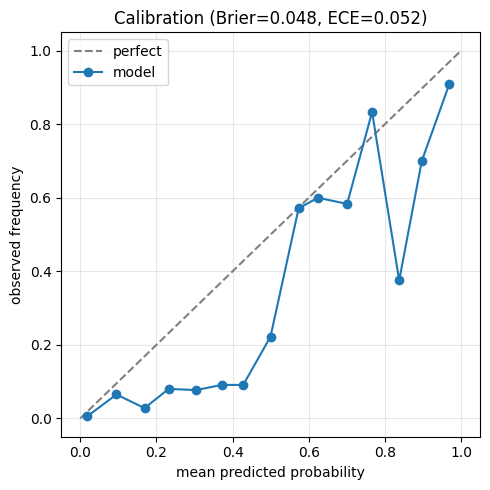

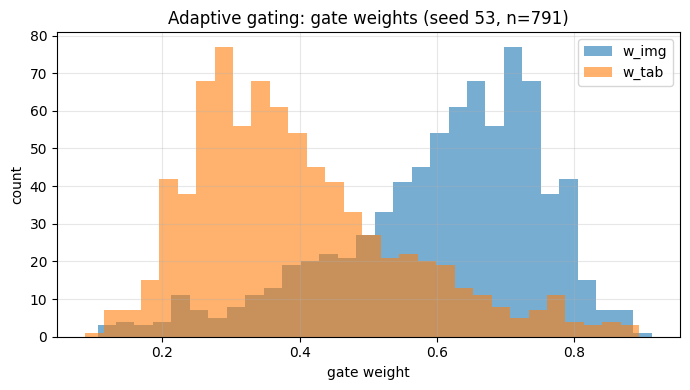

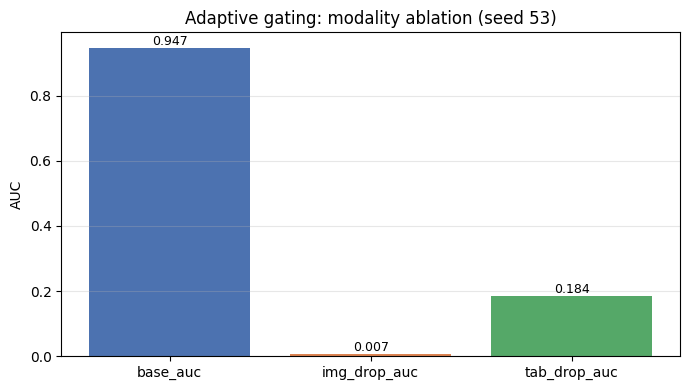

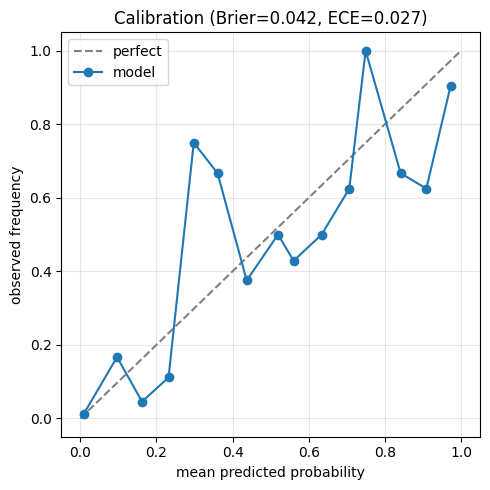

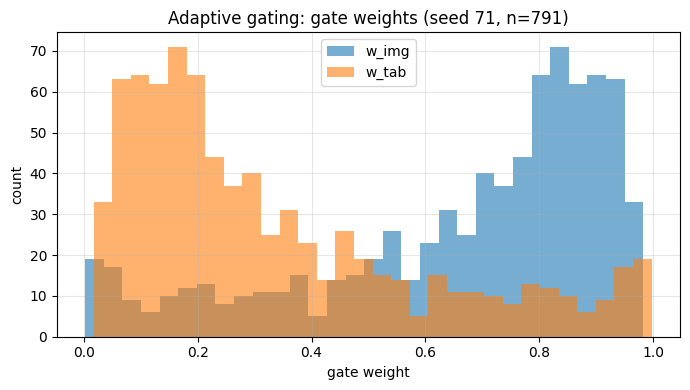

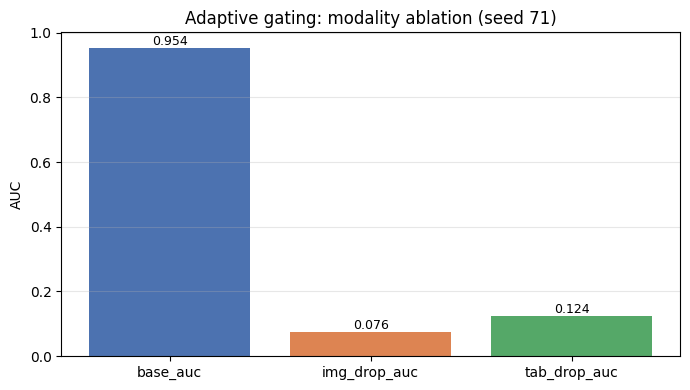

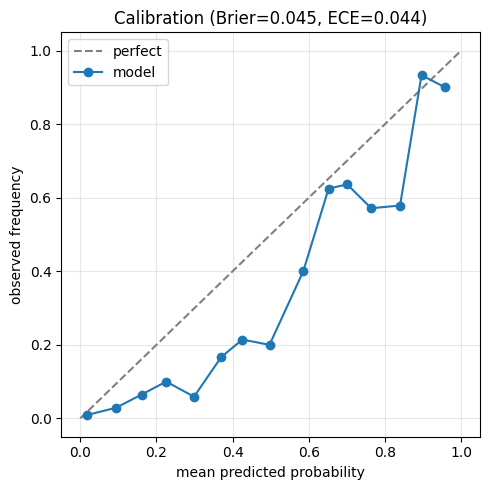

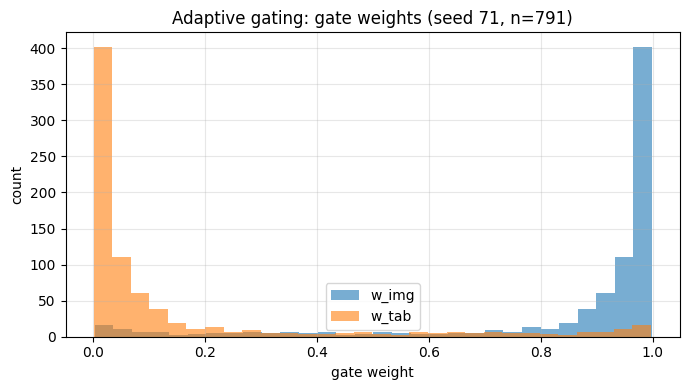

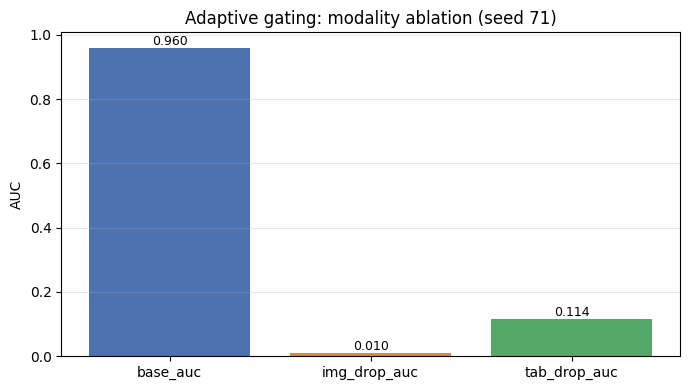

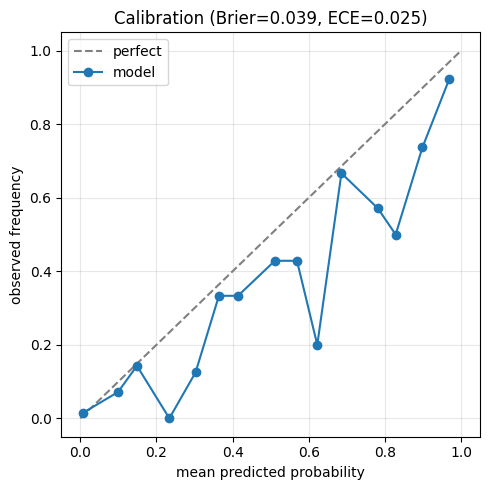

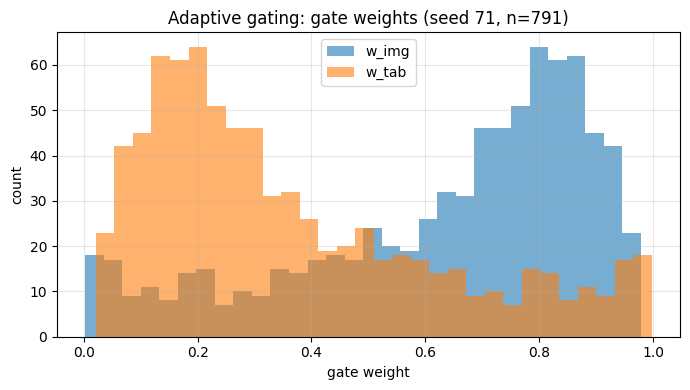

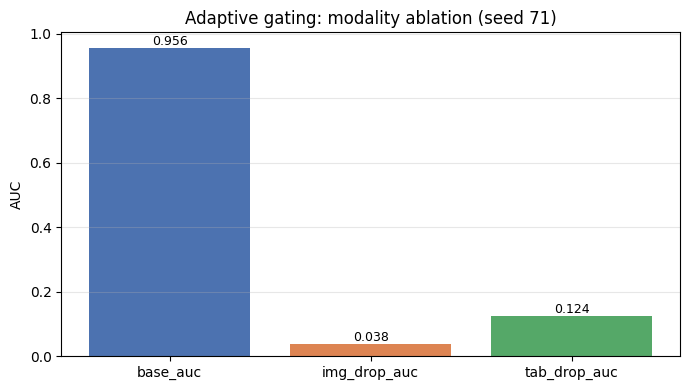

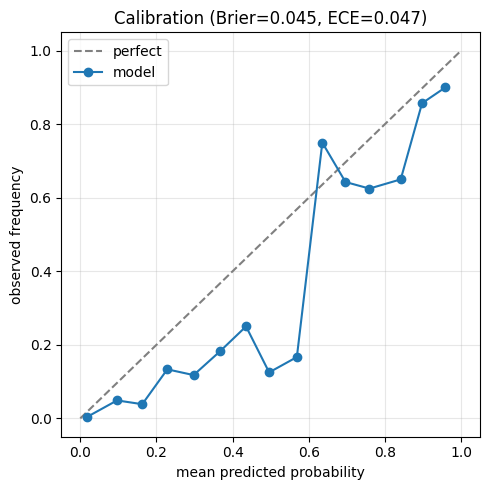

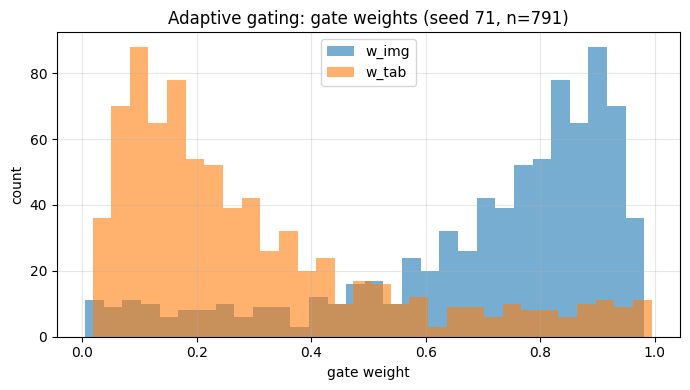

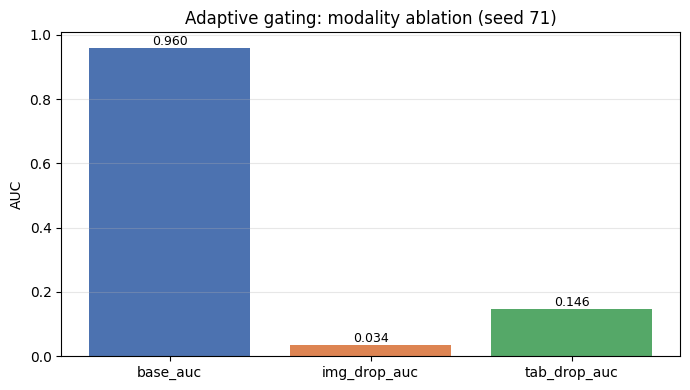

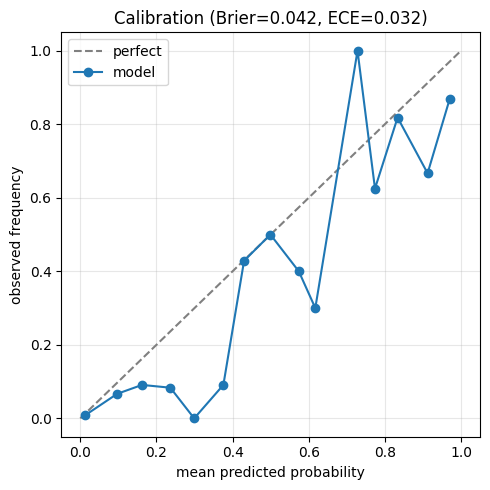

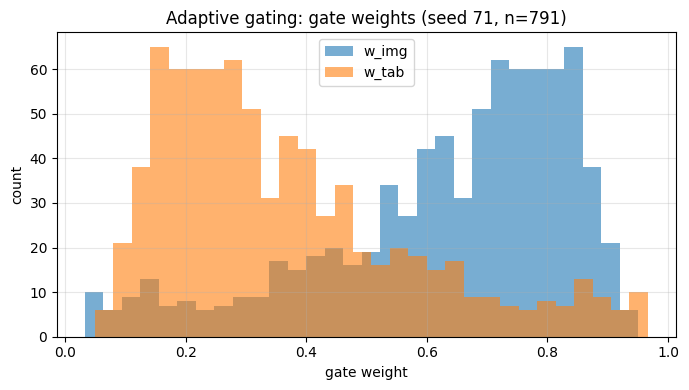

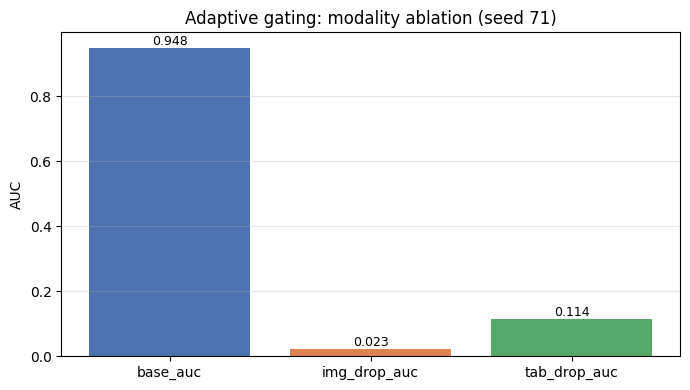

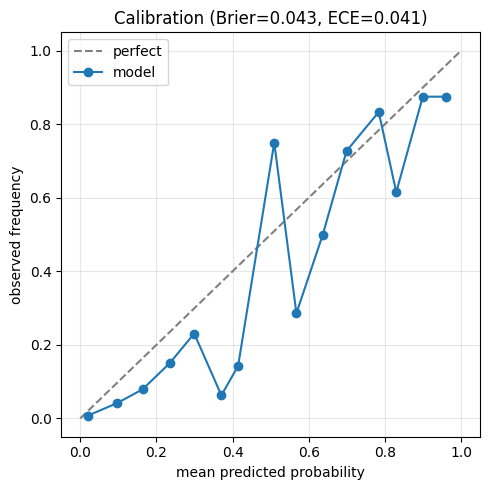

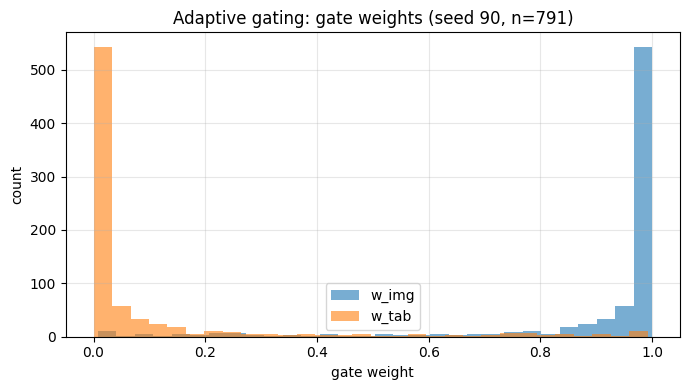

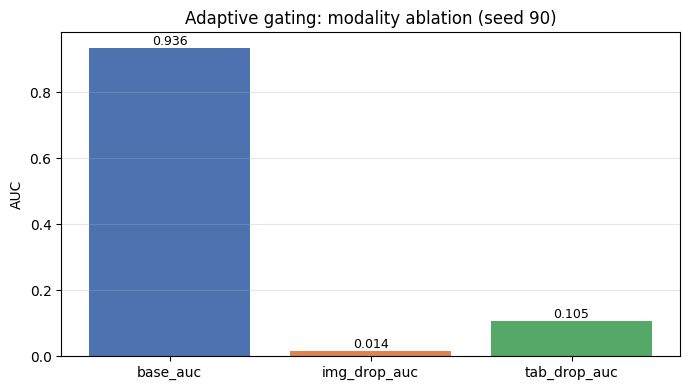

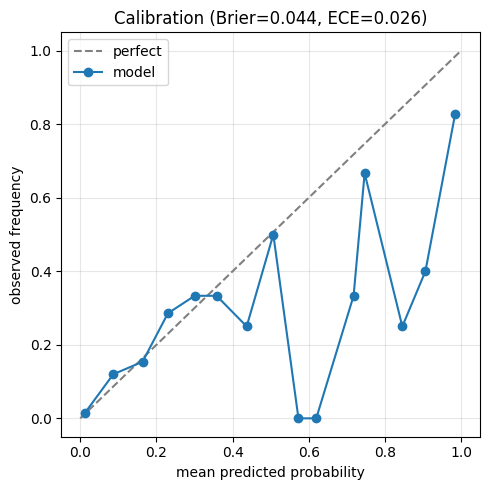

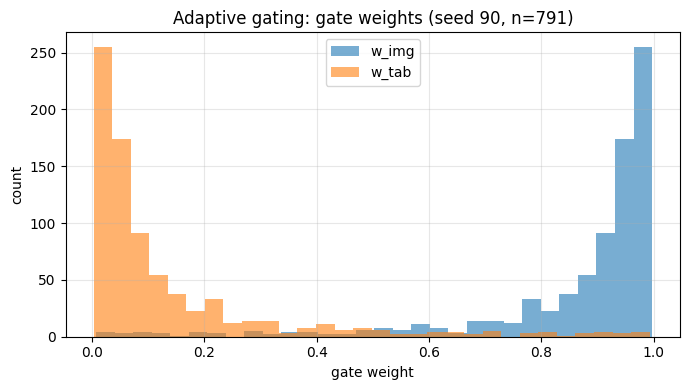

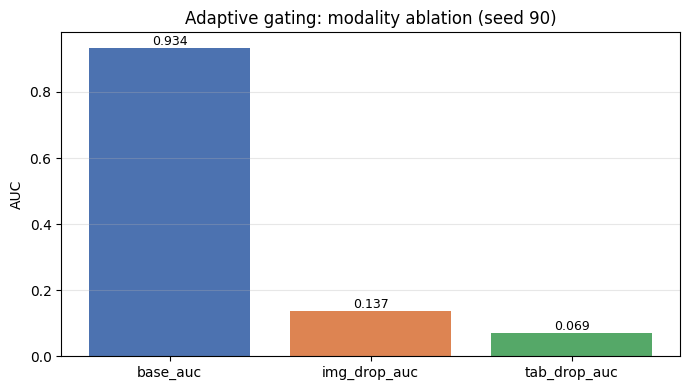

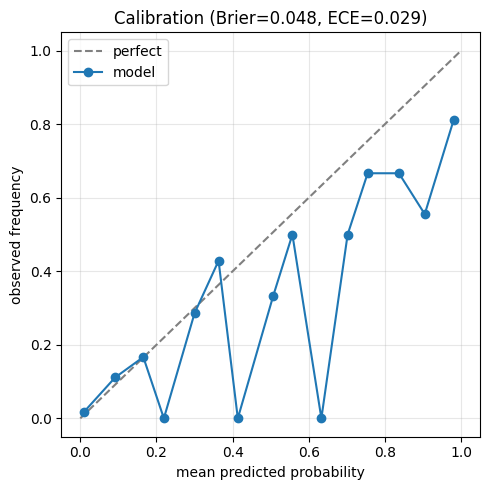

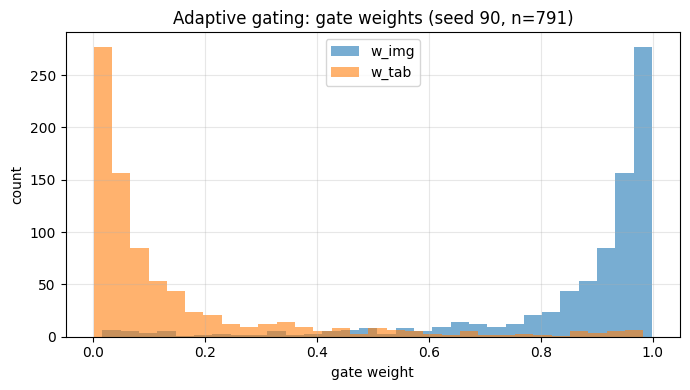

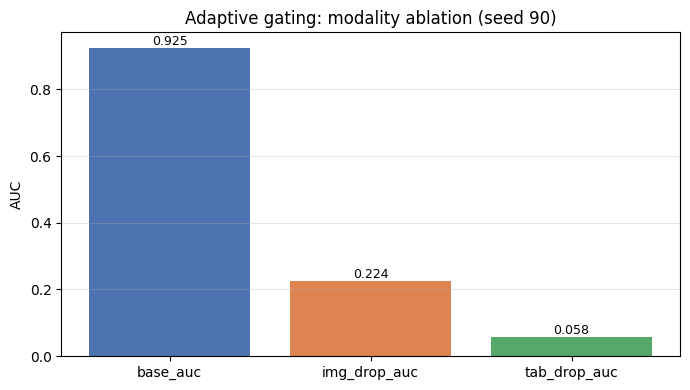

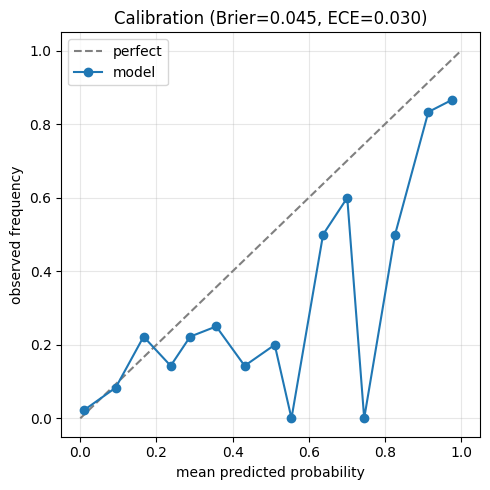

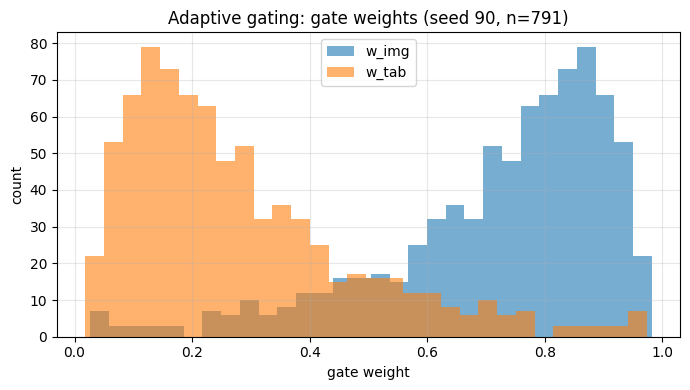

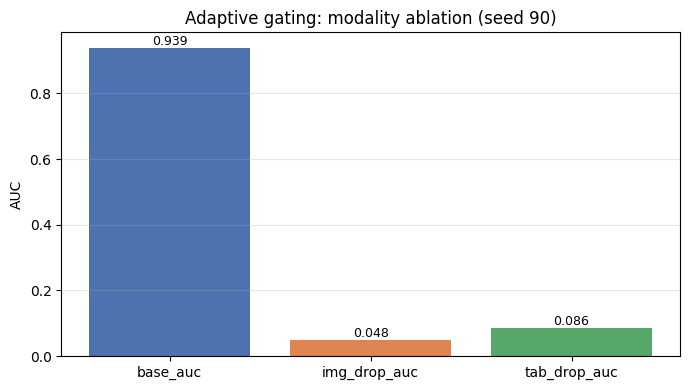

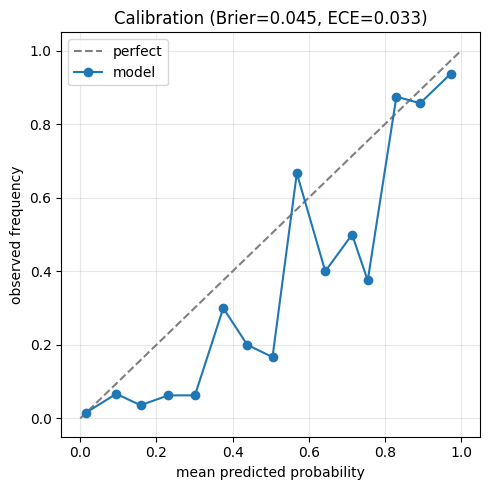

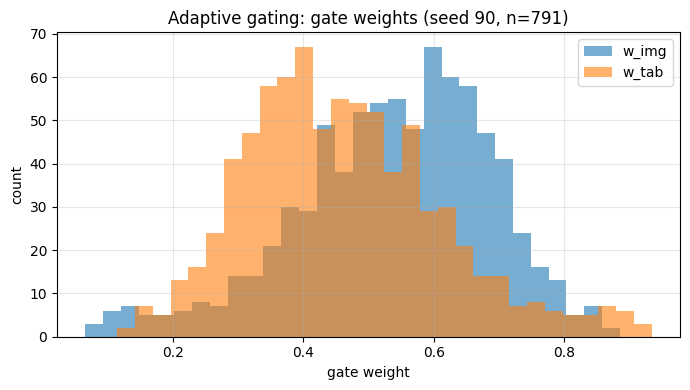

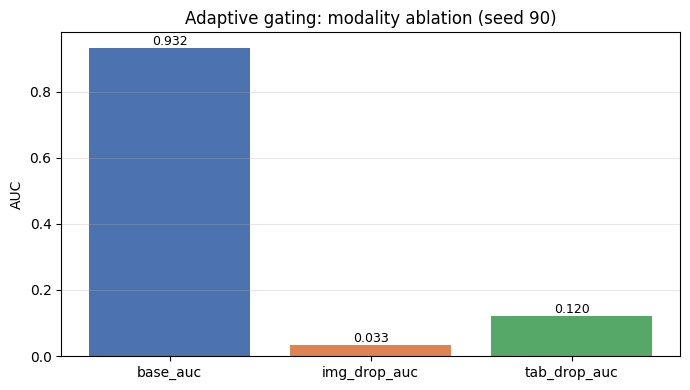

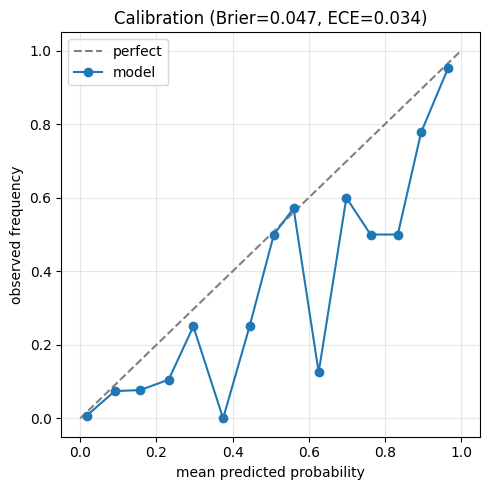

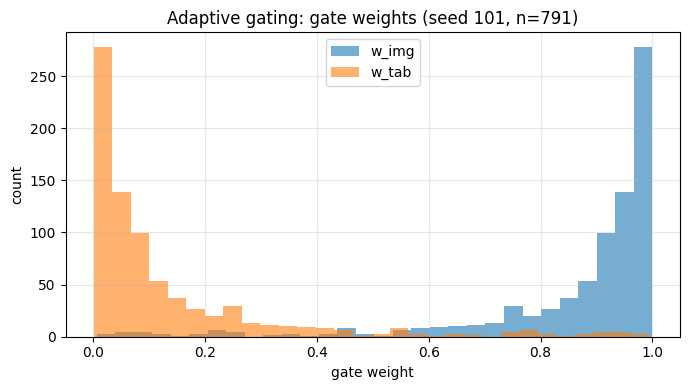

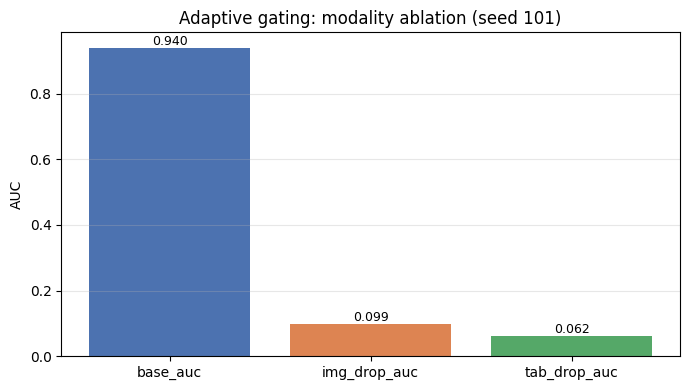

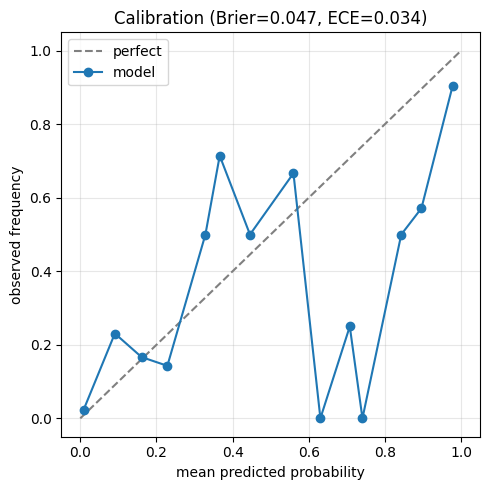

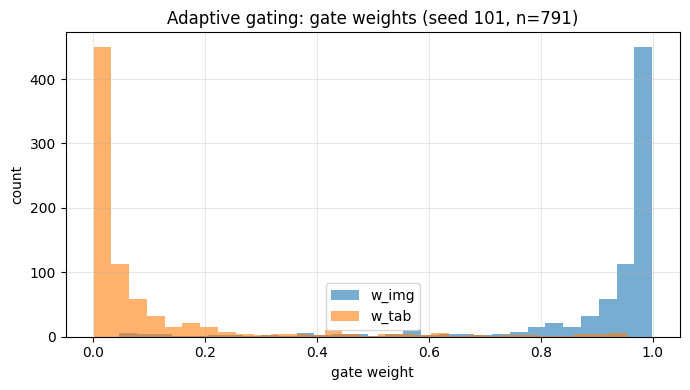

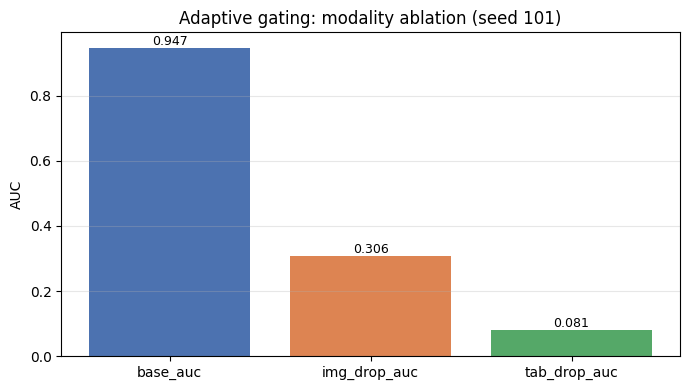

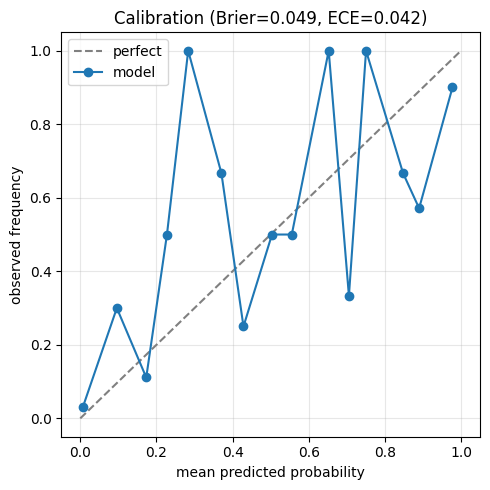

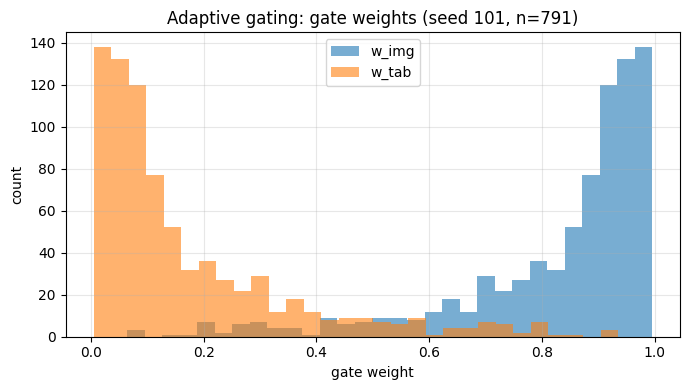

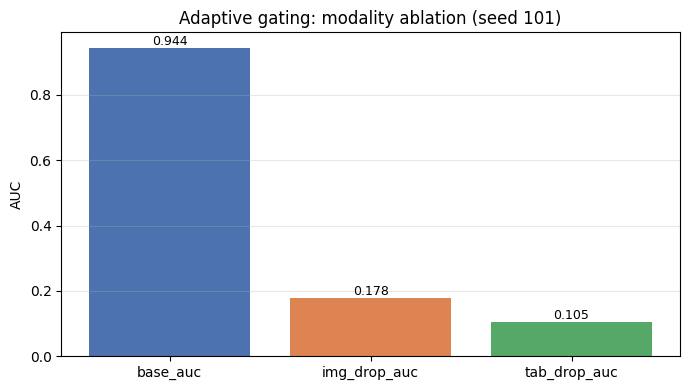

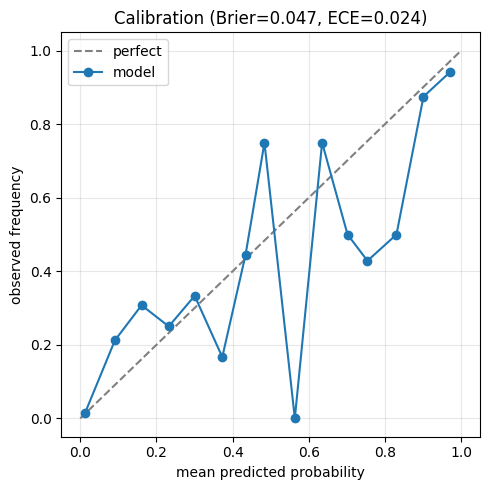

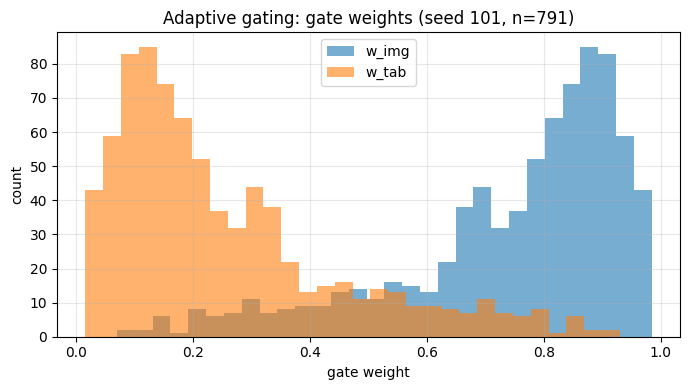

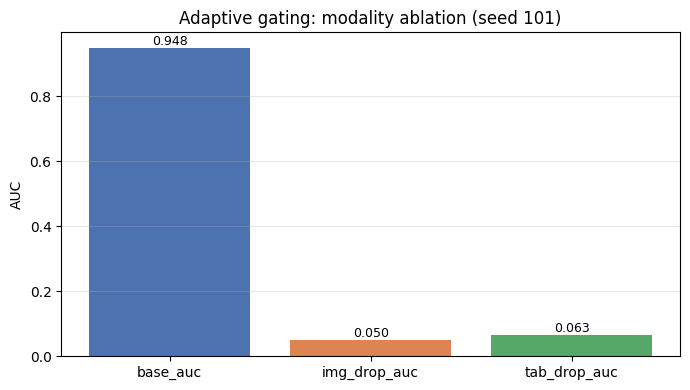

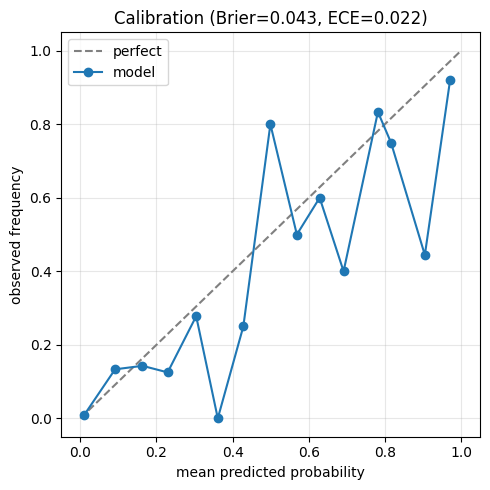

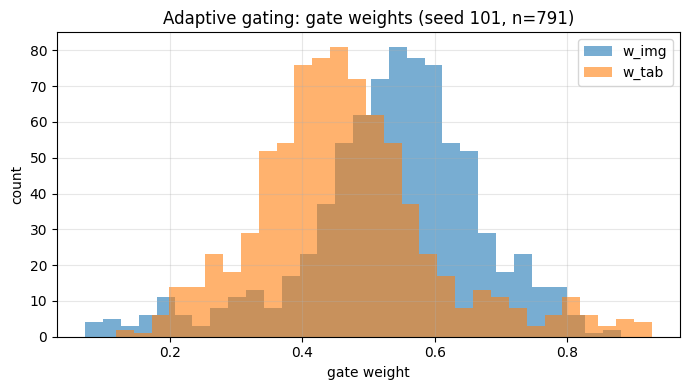

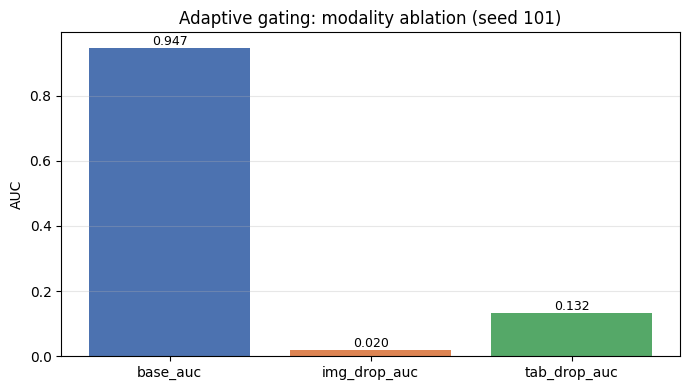

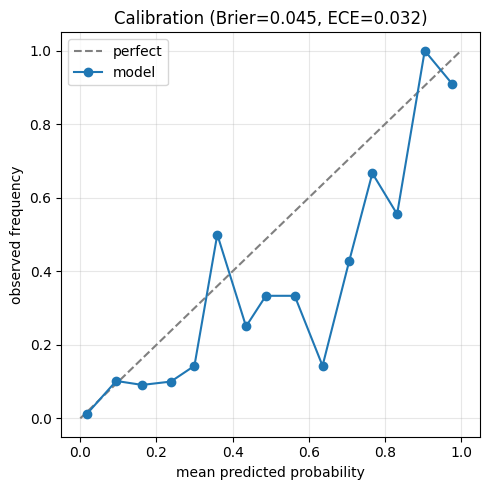

,run_id,setting_tag,seed,entropy_weight,run_dir,base_auc,img_drop_auc,tab_drop_auc,brier,ece,n,gate_weight_mean_img,gate_weight_mean_tab,gate_weight_std_img,gate_entropy_mean,gate_entropy_std,gate_selective_fraction,spearman_w_img_delta_img,spearman_w_tab_delta_tab
0,20260812-060120/seed_8__ent0e+00__e20,ent0e+00,8,0.0000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.938260,0.029562,0.113959,0.058721,0.096864,791,0.407428,0.592572,0.233320,0.550720,0.158564,0.111252,0.206679,0.086003
1,20260812-060120/seed_8__base__e20,base,8,0.0001,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.950971,0.036804,0.076709,0.039732,0.037682,791,0.748093,0.251907,0.263054,0.382717,0.192773,0.434893,-0.172042,0.265449
2,20260812-060120/seed_8__ent1e-03__e20,ent1e-03,8,0.0010,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.955964,0.031117,0.073995,0.044211,0.034269,791,0.820011,0.179989,0.267453,0.260202,0.197916,0.696587,-0.200169,0.218861
3,20260812-060120/seed_8__ent1e-02__e20,ent1e-02,8,0.0100,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.943055,0.137656,0.164187,0.042376,0.030808,791,0.896473,0.103527,0.199292,0.193738,0.171761,0.821745,-0.486175,0.256211
4,20260812-060120/seed_8__ent1e-01__e20,ent1e-01,8,0.1000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.939578,0.143283,0.077749,0.038242,0.025244,791,0.598178,0.401822,0.172068,0.609207,0.092499,0.020228,-0.268767,0.012446
5,20260812-060120/seed_47__ent0e+00__e20,ent0e+00,47,0.0000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.955320,0.003368,0.223885,0.047195,0.062753,791,0.508619,0.491381,0.189764,0.615037,0.103466,0.036662,0.113855,0.147959
6,20260812-060120/seed_47__base__e20,base,47,0.0001,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.953814,0.000218,0.236130,0.049579,0.069184,791,0.485068,0.514932,0.188501,0.615380,0.107494,0.039191,0.257294,0.107804
7,20260812-060120/seed_47__ent1e-03__e20,ent1e-03,47,0.0010,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.950367,-0.000654,0.233683,0.049800,0.069337,791,0.494865,0.505135,0.186111,0.618001,0.103817,0.032870,0.320613,0.077701
8,20260812-060120/seed_47__ent1e-02__e20,ent1e-02,47,0.0100,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.952863,0.007727,0.192203,0.047577,0.036569,791,0.712715,0.287285,0.234011,0.463719,0.170030,0.228824,-0.162498,0.091191
9,20260812-060120/seed_47__ent1e-01__e20,ent1e-01,47,0.1000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.950386,-0.001337,0.223618,0.047827,0.065200,791,0.514635,0.485365,0.163605,0.636086,0.075333,0.008850,0.174904,0.102042


In [ ]:
# @@GATE_DIAGNOSTICS@@ — gate weights, ablation and calibration per adaptive-gating run (GPU)
import keras
from isic24 import xai_driver as xd, xai_logit as xl

_TRAINED = ["base_auc", "img_drop_auc", "tab_drop_auc", "brier", "ece"]
_NEEDED = {"run_id", "run_dir", "setting_tag", "seed", "entropy_weight", *_TRAINED}
assert _NEEDED <= set(ag_combined.columns), f"Missing gate columns: {_NEEDED - set(ag_combined.columns)}"
assert ag_combined.run_id.is_unique, "Duplicate gate runs"
assert len(ag_combined) == len(TRAINING_SEEDS) * EXPECTED_SETTINGS["adaptive_gating"], (
    "Incomplete adaptive-gating study aggregate; rerun the updated training sweep"
)
assert not ag_combined.duplicated(["setting_tag", "seed"]).any(), "Duplicate setting/seed"
assert ag_combined.groupby("setting_tag").seed.apply(
    lambda values: set(values) == set(TRAINING_SEEDS)
).all(), "Gate seed grid mismatch"
assert set(ag_combined.entropy_weight) == {0.0, 1e-4, 1e-3, 1e-2, 1e-1}, "Gate entropy grid mismatch"

all_diag = []
for _, row in ag_combined.iterrows():
    ag_run_dir = xs.run_dir_abs(row["run_dir"], ART_PATH)
    ag_model, _ = xd.load_run_model(ag_run_dir)
    gate = xl.gate_per_sample(ag_model, validation_ds)

    _auc = keras.metrics.AUC()
    _auc.update_state(gate.target.to_numpy(), gate.prediction.to_numpy())
    _seen = {"base_auc": float(_auc.result().numpy()),
             "brier": float(np.mean((gate.prediction - gate.target) ** 2))}
    _off = {k: (v, float(row[k])) for k, v in _seen.items() if abs(v - float(row[k])) > 5e-3}
    assert not _off, (f"{row['run_id']}: the checkpoint disagrees with what training recorded, "
                      f"{_off} as (post-hoc, training) — same weights on the same frame")

    diag = dict(run_id=row["run_id"], setting_tag=row["setting_tag"], seed=int(row["seed"]),
                entropy_weight=float(row["entropy_weight"]), run_dir=ag_run_dir,
                **{c: float(row[c]) for c in _TRAINED}, **xl.gate_summary(gate))
    os.makedirs(os.path.join(ag_run_dir, "diagnostics"), exist_ok=True)
    with open(os.path.join(ag_run_dir, "diagnostics", "adaptive_gating_diagnostics.json"), "w") as f:
        json.dump(diag, f, indent=2)
    all_diag.append(diag)

    plots_dir = os.path.join(ag_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    plt.figure(figsize=(7, 4))
    plt.hist(gate.w_img, bins=30, alpha=0.6, label="w_img")
    plt.hist(gate.w_tab, bins=30, alpha=0.6, label="w_tab")
    plt.xlabel("gate weight"); plt.ylabel("count")
    plt.title(f"Adaptive gating: gate weights (seed {int(row['seed'])}, n={diag['n']})")
    plt.legend(); plt.grid(alpha=0.3)
    _finalize_plot(plots_dir, "gate_weight_distribution.png")

    plt.figure(figsize=(7, 4))
    _bars = ["base_auc", "img_drop_auc", "tab_drop_auc"]
    _vals = [diag[c] for c in _bars]
    plt.bar(_bars, _vals, color=["#4c72b0", "#dd8452", "#55a868"])
    for j, v in enumerate(_vals):
        plt.text(j, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    plt.ylabel("AUC"); plt.grid(alpha=0.3, axis="y")
    plt.title(f"Adaptive gating: modality ablation (seed {int(row['seed'])})")
    _finalize_plot(plots_dir, "modality_ablation_auc_drop.png")

    _edges = np.linspace(0.0, 1.0, 16)
    _conf, _obs = [], []
    for _lo, _hi in zip(_edges[:-1], _edges[1:]):
        _m = (gate.prediction >= _lo) & ((gate.prediction <= _hi) if _hi >= 1.0
                                         else (gate.prediction < _hi))
        if _m.any():
            _conf.append(float(gate.prediction[_m].mean()))
            _obs.append(float(gate.target[_m].mean()))
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
    plt.plot(_conf, _obs, marker="o", label="model")
    plt.xlabel("mean predicted probability"); plt.ylabel("observed frequency")
    plt.title(f"Calibration (Brier={diag['brier']:.3f}, ECE={diag['ece']:.3f})")
    plt.legend(); plt.grid(alpha=0.3)
    _finalize_plot(plots_dir, "calibration_reliability.png")

    keras.backend.clear_session()
    gc.collect()

ag_diag_df = pd.DataFrame(all_diag)
_diag_csv = os.path.join(ag_study_dir, "adaptive_gating_diagnostics.csv")
xs.stamp_aggregate(_diag_csv, ag_diag_df.run_id)
ag_diag_df.to_csv(_diag_csv, index=False)
display(ag_diag_df)

In [ ]:
# @@CF_GAMMA_SWEEP@@ — complete frozen gamma metrics and plot the saved evaluations
from isic24.fusion_calibration import complete_gamma_calibration

posthoc_agg = complete_gamma_calibration(cf_study_dir, include_attendance=True)
posthoc_all_df = pd.read_csv(os.path.join(cf_study_dir, "controlled_fusion_posthoc_gamma_summary.csv"))
for _, row in cf_combined.iterrows():
    cf_run_dir = xs.run_dir_abs(row["run_dir"], ART_PATH)
    posthoc_df = posthoc_all_df[posthoc_all_df.run_id == row.run_id].sort_values("gamma_tab")
    plots_dir = os.path.join(cf_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    plt.figure(figsize=(7, 4))
    plt.plot(posthoc_df["gamma_tab"], posthoc_df["val_auc"], marker="o")
    plt.axvline(1.0, linestyle="--", linewidth=1)
    plt.xlabel("gamma_tab")
    plt.ylabel("val_auc")
    plt.title(f"Controlled fusion post-hoc: val_auc vs gamma_tab (seed {int(row['seed'])})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, "posthoc_val_auc_vs_gamma_tab.png"), dpi=300)
    plt.close()

    plt.figure(figsize=(7, 4))
    plt.scatter(posthoc_df["gamma_img"], posthoc_df["gamma_tab"], c=posthoc_df["val_auc"])
    for _, r in posthoc_df.iterrows():
        plt.text(r["gamma_img"], r["gamma_tab"], f"{r['val_auc']:.3f}", fontsize=8)
    plt.xlabel("gamma_img")
    plt.ylabel("gamma_tab")
    plt.title(f"Controlled fusion post-hoc sweep (seed {int(row['seed'])})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, "posthoc_gamma_sweep_scatter.png"), dpi=300)
    plt.close()

display(posthoc_agg)


,delta,gamma_img,gamma_tab,mean,std,count,brier_mean,brier_std,ece_mean,ece_std,img_drop_auc_mean,img_drop_auc_std,tab_drop_auc_mean,tab_drop_auc_std,modality_balance_mean,modality_balance_std
0,-0.500,1.500,0.500,0.900480,0.013426,6,0.054620,0.004217,0.045280,0.006687,0.263046,0.107813,0.047026,0.017439,0.174653,0.108097
1,-0.375,1.375,0.625,0.917821,0.007841,6,0.052420,0.003816,0.044262,0.004497,0.180678,0.069648,0.057617,0.014153,0.263389,0.114821
2,-0.250,1.250,0.750,0.927767,0.008386,6,0.050018,0.003431,0.039708,0.003907,0.112210,0.025945,0.060803,0.012502,0.357087,0.093709
3,-0.125,1.125,0.875,0.938376,0.007573,6,0.047360,0.003110,0.033485,0.006003,0.096825,0.019754,0.067702,0.015366,0.412381,0.083730
4,0.000,1.000,1.000,0.944343,0.006366,6,0.044632,0.003049,0.028137,0.004948,0.074026,0.017662,0.071955,0.012974,0.495991,0.060649
5,0.125,0.875,1.125,0.945030,0.005507,6,0.042388,0.003245,0.024681,0.004611,0.072193,0.015728,0.071353,0.010477,0.499286,0.030565
6,0.250,0.750,1.250,0.944330,0.005188,6,0.041230,0.003394,0.020782,0.005952,0.069297,0.014722,0.070615,0.009598,0.507290,0.032268
7,0.375,0.625,1.375,0.942197,0.004664,6,0.041733,0.003315,0.026259,0.007802,0.066376,0.015078,0.069231,0.009042,0.513818,0.033328
8,0.500,0.500,1.500,0.937068,0.004685,6,0.044674,0.003151,0.036854,0.010001,0.062047,0.013843,0.063381,0.007807,0.508846,0.037949


## Analysis — reads the artifacts above, loads no checkpoint

`faithfulness_gain = deletion_auc(explanation) − deletion_auc(random)`, over `tabular` (SHAP or
the aligned ranking), `image` (Grad-CAM) and `joint`. Every cell below reads what the block
above wrote, none of them loads a model, and the order among them is free.

In [ ]:
# @@STRATA_SECTION@@ 1/3 — build the full faithfulness table from the saved curves
from isic24 import xai_faithfulness as xf

FAITH_STRATA_SIGNED = True    # include the signed variants

_files = xf.discover_curve_files(ART_PATH, include_signed=FAITH_STRATA_SIGNED)
print("[curve] coverage by source:")
display(_files.groupby("source").agg(run=("run_id", "nunique"), file=("npz_path", "size")))

# Guard: the mean of the per-sample gains must reproduce the aggregate saved in the JSONs.
_probs = xf.verify_reintegration(_files[_files.source == "canonical"].npz_path.iloc[0])
print("[guard] verify_reintegration:", "OK (<1e-9)" if not _probs else f"** FAILED ** {_probs}")

strata = xf.stratified_table(ART_PATH, files=_files, q_maxes=tuple(Q_MAX_REPORT), verbose=False)
pooled = xf.pool_by_family(strata)

_p1 = os.path.join(RUNS_PATH, "_faithfulness", "faithfulness_strata.csv")
_p2 = os.path.join(RUNS_PATH, "_faithfulness", "faithfulness_strata_pooled.csv")
xs.stamp_aggregate(_p1, strata.run_id, q_maxes=list(Q_MAX_REPORT), signed=FAITH_STRATA_SIGNED)
strata.to_csv(_p1, index=False)
pooled.to_csv(_p2, index=False)
print(f"\n[wrote] {_p1}   ({len(strata)} rows: one per run x source x cell)")
print(f"[wrote] {_p2}   ({len(pooled)} rows, pooled by family)")
print("\nBoth are derived: this cell regenerates them at any time, they are not canonical.")

[curve] coverage by source:


,run,file
source,,
aligned_signed,156,624
canonical,156,156
gradient,156,156


[guard] verify_reintegration: OK (<1e-9)
  [ablations] faithfulness strata: 6480 unimodal endpoint runs excluded from the aggregate

[wrote] /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/runs/_faithfulness/faithfulness_strata.csv   (84240 rows: one per run x source x cell)
[wrote] /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/runs/_faithfulness/faithfulness_strata_pooled.csv   (3240 rows, pooled by family)

Both are derived: this cell regenerates them at any time, they are not canonical.


In [ ]:
# @@STRATA_SECTION@@ 2/3 — summary table: one row per family, every attributor side by side
# Deletion, stratum "all", column gain_norm (per unit of budget); positive = faithful.
_h = pooled[(pooled.stratum == "all") & (pooled.direction == "del")].copy()
_h["attributor"] = np.where(
    _h.source == "canonical", "perm:" + _h.method,
    np.where(_h.source == "gradient", "SHAPgrad:" + _h.method, "signed:" + _h["mode"]))

_piv = _h.pivot_table(index="impl_name", columns=["attributor", "q_max"], values="gain_norm")
print("gain_norm — deletion, all samples (positive = faithful)")
display(_piv.round(3))

# How many runs sit behind each number.
print("\nruns per cell (n_runs):")
display(_h.pivot_table(index="impl_name", columns="attributor", values="n_runs", aggfunc="max"))

print("attributors: perm:* = logit-aligned Permutation on the named branch | "
      "SHAPgrad:* = SHAP GradientExplainer on the named branch | "
      "signed:* = the Permutation again, evidence for/against. The two rankings are read "
      "side by side and never averaged together.")

gain_norm — deletion, all samples (positive = faithful)


attributor          SHAPgrad:joint        SHAPgrad:tabular        perm:image  \
q_max                          0.2    0.6              0.2    0.6        0.2   
impl_name                                                                      
adaptive_gating              0.855  1.071            0.489  0.522      0.288   
controlled_fusion            0.859  1.048            0.296  0.338      0.600   
fixed_scaling                0.809  0.909            0.181  0.243      0.651   
learnable_scaling            0.767  0.867            0.180  0.239      0.618   
loss_regularization          0.800  0.923            0.219  0.296      0.593   
vanilla                      0.778  0.868            0.230  0.309      0.569   

attributor                 perm:joint        perm:tabular        signed:abs  \
q_max                  0.6        0.2    0.6          0.2    0.6        0.2   
impl_name                                                                     
adaptive_gating      0.358      1.246  1.369        0.827  0.805      0.827   
controlled_fusion    0.695      1.139  1.261        0.533  0.545      0.533   
fixed_scaling        0.669      0.960  1.053        0.289  0.356      0.289   
learnable_scaling    0.640      0.922  1.012        0.288  0.353      0.288   
loss_regularization  0.615      0.976  1.101        0.359  0.447      0.359   
vanilla              0.565      0.948  1.046        0.364  0.458      0.364   

attributor                 signed:negev        signed:posev         \
q_max                  0.6          0.2    0.6          0.2    0.6   
impl_name                                                            
adaptive_gating      0.805        1.666  2.832        1.525  1.726   
controlled_fusion    0.545        1.708  2.774        2.000  2.928   
fixed_scaling        0.356        0.956  1.523        1.031  1.443   
learnable_scaling    0.353        0.941  1.502        1.016  1.425   
loss_regularization  0.447        1.206  1.919        1.359  1.940   
vanilla              0.458        1.166  1.861        1.312  1.880   

attributor          signed:target         
q_max                         0.2    0.6  
impl_name                                 
adaptive_gating             1.896  2.475  
controlled_fusion           2.033  3.010  
fixed_scaling               1.094  1.577  
learnable_scaling           1.078  1.556  
loss_regularization         1.401  2.047  
vanilla                     1.351  1.981


runs per cell (n_runs):


attributor,SHAPgrad:joint,SHAPgrad:tabular,perm:image,perm:joint,perm:tabular,signed:abs,signed:negev,signed:posev,signed:target
impl_name,,,,,,,,,
adaptive_gating,30,30,30,30,30,30,30,30,30
controlled_fusion,6,6,6,6,6,6,6,6,6
fixed_scaling,42,42,42,42,42,42,42,42,42
learnable_scaling,30,30,30,30,30,30,30,30,30
loss_regularization,30,30,30,30,30,30,30,30,30
vanilla,6,6,6,6,6,6,6,6,6


attributors: perm:* = logit-aligned Permutation on the named branch | SHAPgrad:* = SHAP GradientExplainer on the named branch | signed:* = the Permutation again, evidence for/against. The two rankings are read side by side and never averaged together.


In [ ]:
# @@STRATA_SECTION@@ 3/3 — strata: by class, and by confidence x correctness
# Shown at the low cutoff, the clean regime; at full budget the metric is OOD-dominated.
STRATA_SHOW = ["all", "class_pos", "class_neg",
               "sure_correct", "sure_wrong", "unsure_correct", "unsure_wrong"]
_QLOW = min(Q_MAX_REPORT)

_s = pooled[(pooled.direction == "del") & (pooled.q_max == _QLOW)
            & (pooled.stratum.isin(STRATA_SHOW))]

for _src, _mode, _meth, _title in [
        ("canonical", "abs", "tabular", "aligned Permutation — tabular"),
        ("gradient", "abs", "tabular", "SHAP GradientExplainer — tabular"),
        ("canonical", "abs", "joint", "aligned Permutation — joint"),
        ("gradient", "abs", "joint", "SHAP GradientExplainer — joint"),
        ("aligned_signed", "target", "tabular", "signed Permutation — true class (`target`)")]:
    _t = _s[(_s.source == _src) & (_s["mode"] == _mode) & (_s.method == _meth)]
    if not len(_t):
        print(f"\n[{_title}] no rows — source not on disk.")
        continue
    print(f"\n{_title}   (deletion, q<={_QLOW}, gain_norm)")
    display(_t.pivot_table(index="impl_name", columns="stratum", values="gain_norm")
              .reindex(columns=[c for c in STRATA_SHOW if c in set(_t.stratum)]).round(3))

print("\nEmpty cells are withheld on purpose below MIN_CELL_N; column `n` in `strata` "
      "gives the real sample count.")


aligned Permutation — tabular   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.827,1.598,0.055,0.537,0.137,1.272,0.767
controlled_fusion,0.533,1.033,0.033,0.227,-0.329,0.862,0.902
fixed_scaling,0.289,0.526,0.051,0.133,-0.304,0.455,0.506
learnable_scaling,0.288,0.530,0.046,0.131,-0.215,0.456,0.489
loss_regularization,0.359,0.629,0.089,0.187,-0.387,0.549,0.601
vanilla,0.364,0.631,0.097,0.209,NaN,0.546,0.594



SHAP GradientExplainer — tabular   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.489,1.240,-0.263,0.295,-0.408,0.912,0.188
controlled_fusion,0.296,0.750,-0.158,0.037,-0.715,0.645,0.555
fixed_scaling,0.181,0.379,-0.016,0.070,-0.477,0.334,0.319
learnable_scaling,0.180,0.387,-0.027,0.068,-0.387,0.334,0.301
loss_regularization,0.219,0.457,-0.019,0.088,-0.664,0.407,0.378
vanilla,0.230,0.470,-0.010,0.110,NaN,0.416,0.358



aligned Permutation — joint   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,1.246,2.211,0.280,0.848,0.513,1.842,1.166
controlled_fusion,1.139,2.015,0.262,0.564,0.055,1.951,1.459
fixed_scaling,0.960,1.758,0.162,0.487,-0.130,1.666,1.115
learnable_scaling,0.922,1.708,0.135,0.443,-0.010,1.668,0.993
loss_regularization,0.976,1.750,0.202,0.533,-0.167,1.653,1.111
vanilla,0.948,1.719,0.176,0.531,NaN,1.581,1.057



SHAP GradientExplainer — joint   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.855,1.786,-0.075,0.541,-0.054,1.442,0.539
controlled_fusion,0.859,1.674,0.043,0.337,-0.463,1.686,1.079
fixed_scaling,0.809,1.532,0.085,0.396,-0.434,1.485,0.889
learnable_scaling,0.767,1.484,0.049,0.360,-0.311,1.456,0.780
loss_regularization,0.800,1.503,0.097,0.407,-0.658,1.469,0.872
vanilla,0.778,1.475,0.081,0.411,NaN,1.406,0.796



signed Permutation — true class (`target`)   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,1.896,2.401,1.392,1.771,0.770,2.272,1.526
controlled_fusion,2.033,2.527,1.538,1.737,1.911,2.292,2.350
fixed_scaling,1.094,1.301,0.887,0.998,0.761,1.183,1.247
learnable_scaling,1.078,1.283,0.873,0.981,0.752,1.175,1.220
loss_regularization,1.401,1.683,1.119,1.249,1.112,1.538,1.606
vanilla,1.351,1.621,1.080,1.228,NaN,1.446,1.565



Empty cells are withheld on purpose below MIN_CELL_N; column `n` in `strata` gives the real sample count.



canonical ranking — tabular
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


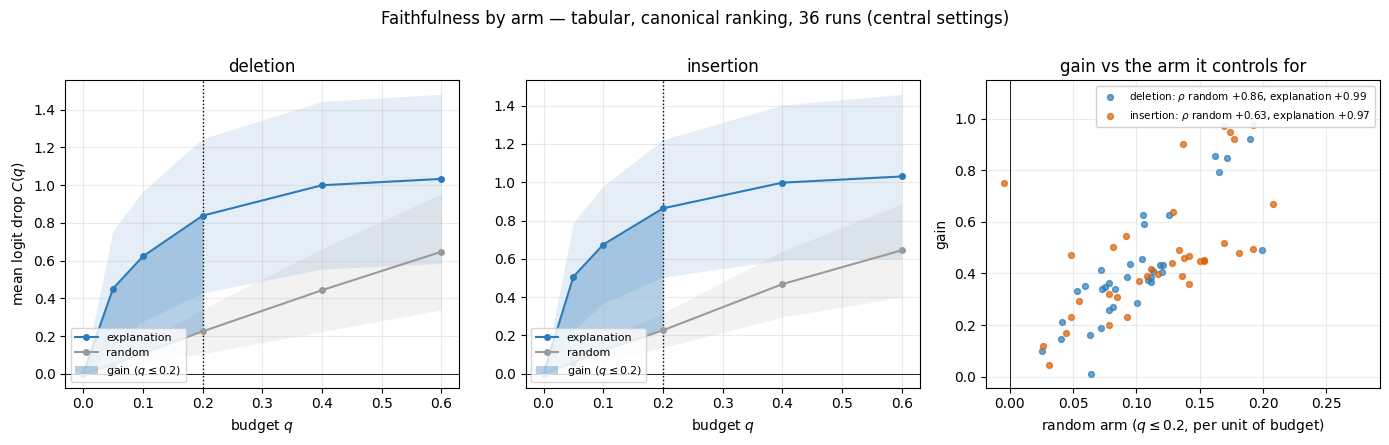

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,1.011,0.195,0.816,0.854,0.114,0.740
controlled_fusion,0.654,0.121,0.533,0.687,0.099,0.588
fixed_scaling,0.399,0.082,0.317,0.493,0.120,0.372
learnable_scaling,0.348,0.069,0.279,0.428,0.103,0.325
loss_regularization,0.468,0.094,0.373,0.564,0.133,0.431
vanilla,0.455,0.091,0.364,0.548,0.130,0.418



canonical ranking — image
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


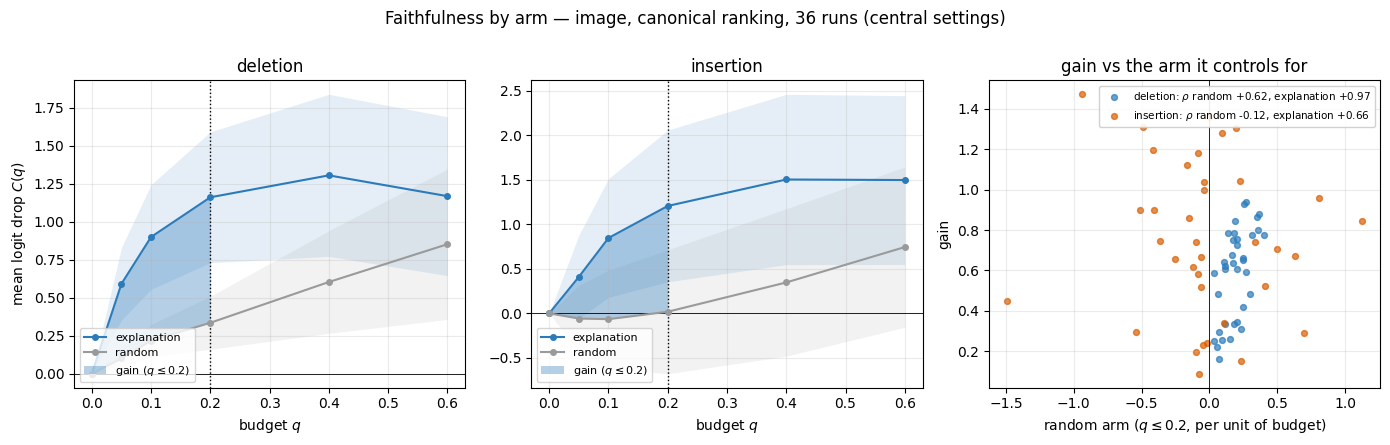

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.373,0.072,0.301,0.601,0.185,0.416
controlled_fusion,0.713,0.113,0.600,0.878,0.155,0.724
fixed_scaling,1.018,0.251,0.766,0.762,-0.252,1.014
learnable_scaling,0.927,0.263,0.665,0.844,-0.063,0.907
loss_regularization,0.841,0.235,0.606,0.722,-0.077,0.799
vanilla,0.780,0.211,0.569,0.522,-0.156,0.678



canonical ranking — joint
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


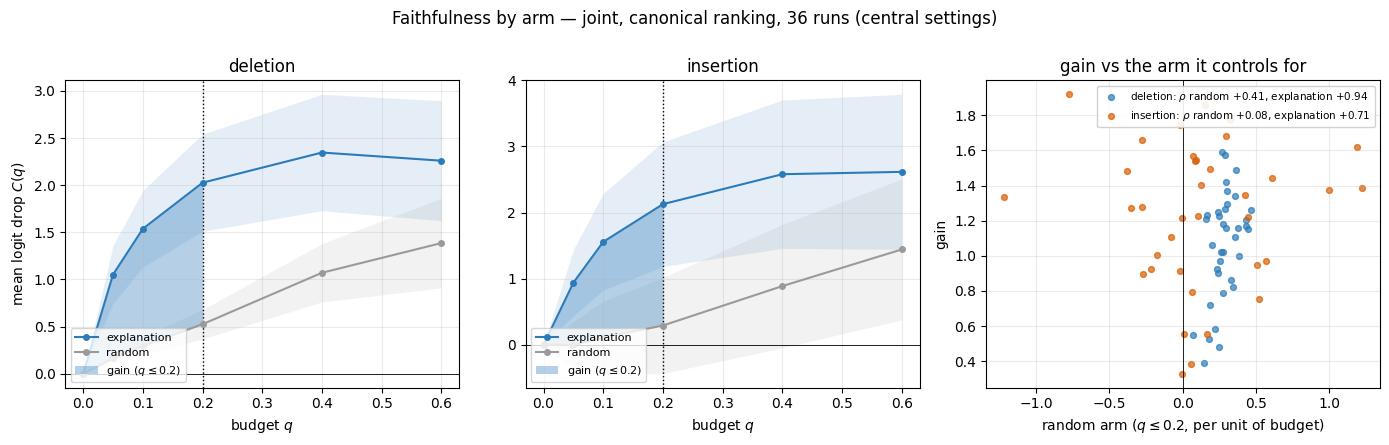

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,1.475,0.251,1.224,1.658,0.366,1.293
controlled_fusion,1.368,0.229,1.139,1.565,0.269,1.296
fixed_scaling,1.417,0.320,1.097,1.255,-0.103,1.357
learnable_scaling,1.275,0.317,0.959,1.273,0.070,1.203
loss_regularization,1.309,0.294,1.015,1.286,0.088,1.198
vanilla,1.235,0.287,0.948,1.070,0.000,1.070



gradient ranking — tabular
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


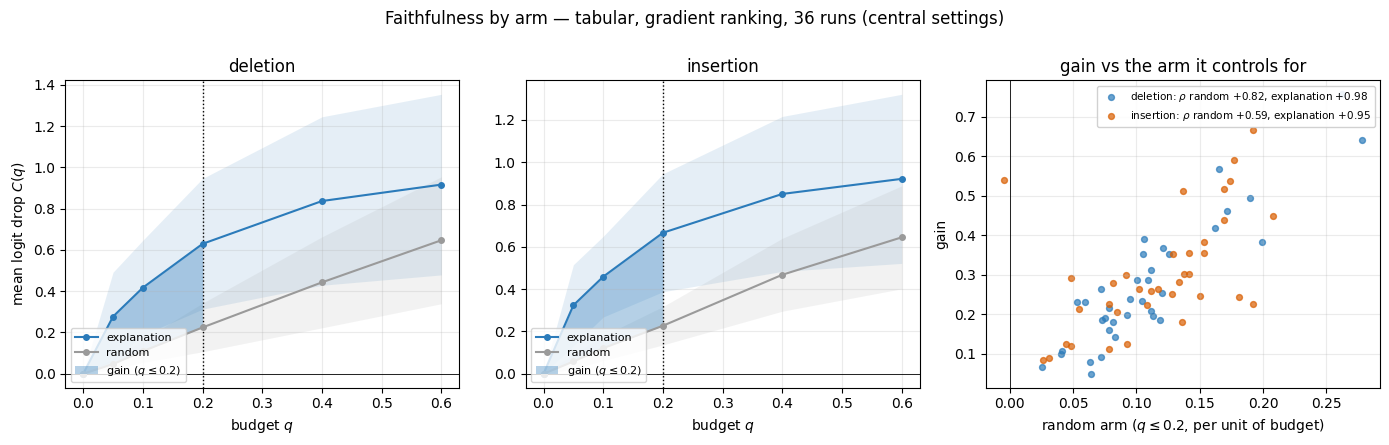

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.715,0.195,0.520,0.588,0.114,0.474
controlled_fusion,0.417,0.121,0.296,0.440,0.099,0.340
fixed_scaling,0.284,0.082,0.202,0.369,0.120,0.249
learnable_scaling,0.236,0.069,0.166,0.307,0.103,0.204
loss_regularization,0.326,0.094,0.232,0.411,0.133,0.278
vanilla,0.321,0.091,0.230,0.403,0.130,0.273



gradient ranking — joint
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


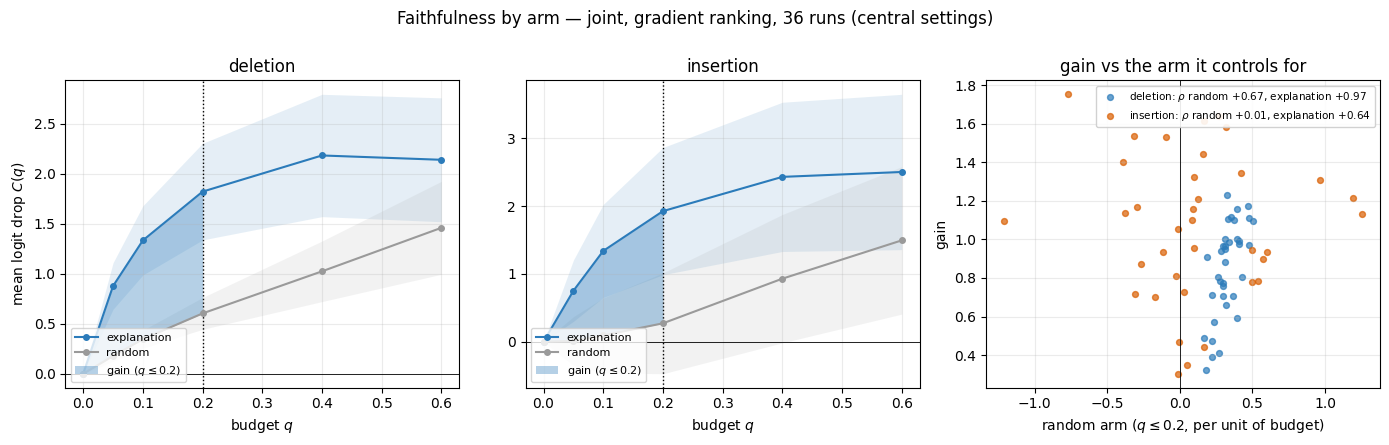

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,1.184,0.301,0.883,1.370,0.374,0.996
controlled_fusion,1.130,0.272,0.859,1.318,0.268,1.050
fixed_scaling,1.302,0.368,0.934,1.131,-0.119,1.250
learnable_scaling,1.163,0.343,0.820,1.151,0.057,1.094
loss_regularization,1.167,0.343,0.824,1.133,0.074,1.059
vanilla,1.100,0.322,0.778,0.925,-0.023,0.948


In [ ]:
# @@REPORT_FIGURES@@ — the arm figures, the ones a table cannot carry (CPU, no checkpoint)
# Self-contained: paths and central settings come from the modules, so a fresh kernel is enough.
from isic24 import xai_faithfulness as xf, xai_figures as xfig

_ARM_COLS = ["del_exp", "del_rand", "del_gain", "ins_exp", "ins_rand", "ins_gain"]
for _src, _meths in xf.DEFAULT_METHODS.items():
    if _src == "aligned_signed":       # a sign convention, not a second attributor
        continue
    for _meth in _meths:
        print(f"\n{_src} ranking — {_meth}")
        display(xfig.arms(source=_src, method=_meth)
                .groupby("impl_name")[_ARM_COLS].mean().round(3))

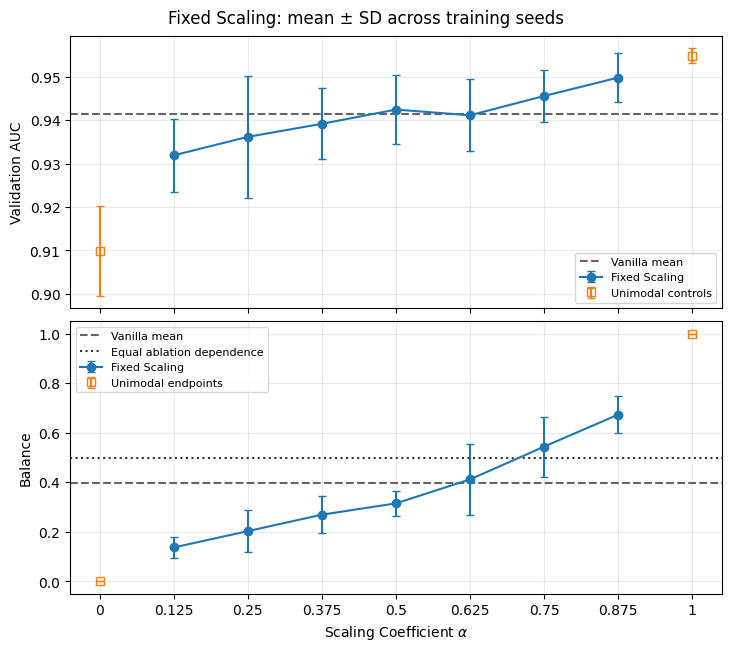

Saved: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/figures/report/fig_fixed_scaling_auc_balance.png


: 

In [ ]:
# @@ATTENDANCE_FIGURE@@ — Plot validation AUC and ablation balance with separate unimodal controls.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

_attendance_rows = pd.read_csv(Path(SUMMARIES_PATH) / "master_results_rows.csv")
_attendance_metrics = ["best_val_auc", "modality_balance"]
_attendance_fixed = _attendance_rows.loc[_attendance_rows.impl_name == "fixed_scaling"]
assert not _attendance_fixed.duplicated(["alpha", "seed"]).any(), "Duplicate fixed-scaling seed/alpha rows"
_attendance_summary = _attendance_fixed.groupby("alpha")[_attendance_metrics].agg(["mean", "std"])
_attendance_bimodal = _attendance_summary.loc[
    (_attendance_summary.index > 0) & (_attendance_summary.index < 1)
]
_attendance_controls = _attendance_summary.loc[[0.0, 1.0]]
_attendance_vanilla = _attendance_rows.loc[
    _attendance_rows.impl_name == "vanilla", _attendance_metrics
].mean()

_attendance_fig, _attendance_axes = plt.subplots(2, 1, sharex=True, figsize=(7.2, 6.4), layout="constrained")
for _ax, _metric, _ylabel, _control_label in zip(
    _attendance_axes, _attendance_metrics,
    ("Validation AUC", "Balance"),
    ("Unimodal controls", "Unimodal endpoints"),
):
    _ax.errorbar(
        _attendance_bimodal.index, _attendance_bimodal[(_metric, "mean")],
        yerr=_attendance_bimodal[(_metric, "std")], fmt="o-", capsize=3,
        color="C0", label="Fixed Scaling",
    )
    _ax.errorbar(
        _attendance_controls.index, _attendance_controls[(_metric, "mean")],
        yerr=_attendance_controls[(_metric, "std")], fmt="s", capsize=3,
        color="C1", markerfacecolor="none", label=_control_label,
    )
    _ax.axhline(_attendance_vanilla[_metric], color="0.4", linestyle="--", label="Vanilla mean")
    _ax.set_ylabel(_ylabel)
    _ax.grid(alpha=0.25)
_attendance_axes[1].axhline(0.5, color="0.2", linestyle=":", label="Equal ablation dependence")
_attendance_axes[1].set_ylim(-0.05, 1.05)
_attendance_axes[1].set_xticks(_attendance_summary.index, [f"{a:g}" for a in _attendance_summary.index])
_attendance_axes[1].set_xlabel(r"Scaling Coefficient $\alpha$")
_attendance_axes[0].legend(fontsize=8, loc="lower right")
_attendance_axes[1].legend(fontsize=8, loc="upper left")
_attendance_fig.suptitle("Fixed Scaling: mean ± SD across training seeds")
_attendance_output = Path(ART_PATH) / "figures" / "report" / "fig_fixed_scaling_auc_balance.png"
_attendance_output.parent.mkdir(parents=True, exist_ok=True)
_attendance_fig.savefig(_attendance_output, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {_attendance_output}")


In [ ]:
# @@LORE_SECTION@@ — aggregate the per-sample LORE CSVs SUBSET 3/3 wrote (CPU)
from isic24.run_ids import run_id_from_artifact

_lore_files = sorted(glob.glob(os.path.join(RUNS_PATH, "**", "xai", "lore_sa", "epoch*",
                                            "lore_sa_persample_*.csv"), recursive=True))
if not _lore_files:
    print("No `lore_sa` artifact yet: run `SUBSET 3/3`, which writes xai/lore_sa/.")
else:
    print(f"[LORE] {len(_lore_files)} runs from xai/lore_sa/")
    _master = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
    _meta = {str(r.run_id): (r.impl_name, r.setting_tag, int(r.seed)) for _, r in _master.iterrows()}

    _rows, _unmatched = [], []
    for f in _lore_files:
        _rid = run_id_from_artifact(f)
        if _rid not in _meta:
            _unmatched.append(f"{_rid}   ({f})")
            continue
        d = pd.read_csv(f)
        d["run_id"] = _rid
        d["impl_name"], d["setting_tag"], d["seed"] = _meta[_rid]
        d["rng_protocol"] = "seeded-v2" if "rng_seed" in d.columns else "unseeded-v1"
        _rows.append(d)
    if _unmatched:
        raise RuntimeError("LORE artifacts absent from the canonical registry:\n  "
                           + "\n  ".join(_unmatched))

    L = pd.concat(_rows, ignore_index=True)
    L["covered"] = L["neigh_n_classes"] >= 2
    L["rule_len_covered"] = L["rule_len"].where(L["covered"])
    L["fid_cv_bacc_covered"] = L["fid_cv_bacc"].where(L["covered"])
    L["legacy_unseeded"] = L["rng_protocol"] == "unseeded-v1"

    fam = L.groupby(["impl_name", "setting_tag"]).agg(
        n_run=("run_id", "nunique"),
        n_samples=("i", "size"),
        lore_coverage=("covered", "mean"),
        neigh_pos_rate=("neigh_pos_rate", "mean"),
        neigh_unique_frac=("neigh_unique_frac", "mean"),
        rule_len_covered=("rule_len_covered", "mean"),
        fid_cv_bacc_covered=("fid_cv_bacc_covered", "mean"),
    )
    fam["n_covered"] = L.groupby(["impl_name", "setting_tag"])["covered"].sum()
    fam["n_legacy_runs"] = (L[L.legacy_unseeded]
        .groupby(["impl_name", "setting_tag"])["run_id"].nunique()
        .reindex(fam.index, fill_value=0).astype(int))
    print("\nLORE explanation quality by family "
          "(`lore_coverage` = how far the tabular branch drives the decision)")
    _controls = np.array([xs.is_ablation(i, t) for i, t in fam.index])
    display(fam.loc[~_controls].round(3))
    print("Unimodal controls (excluded from inference)")
    display(fam.loc[_controls].round(3))

    cw = (L.groupby(["impl_name", "setting_tag", "true_label"])
            .agg(n=("i", "size"), lore_coverage=("covered", "mean"),
                 neigh_pos_rate=("neigh_pos_rate", "mean"),
                 rule_len_covered=("rule_len_covered", "mean"),
                 fid_cv_bacc_covered=("fid_cv_bacc_covered", "mean"))
            .unstack("true_label"))
    _class_names = ("Benign", "Malignant")
    print(f"\nBy true class: 0 = {_class_names[0]}, 1 = {_class_names[1]}")
    display(cw.loc[fam.index[~_controls]].round(3))
    print("Unimodal controls (excluded from inference)")
    display(cw.loc[fam.index[_controls]].round(3))
    cw.reset_index().to_csv(
        os.path.join(RUNS_PATH, "_faithfulness", "lore_sa_quality_by_family_class.csv"),
        index=False)

    print("\nWithin-setting class contrasts: paired seeds; unadjusted exploratory p-values")
    _run_coverage = (L.groupby(["impl_name", "setting_tag", "seed", "true_label"])
                     ["covered"].mean().unstack("true_label").reindex(columns=[0, 1]))
    _contrasts = []
    for (_impl, _tag), _g in _run_coverage.groupby(level=["impl_name", "setting_tag"]):
        if xs.is_ablation(_impl, _tag):
            continue
        _paired = _g.dropna()
        _res = xs.across_runs(_paired[0], _paired[1], *_class_names)
        _res["n_seeds"] = _res.pop("n_run")
        _contrasts.append(dict(impl_name=_impl, setting_tag=_tag,
                               coverage_negative=_paired[0].mean(),
                               coverage_positive=_paired[1].mean(), **_res))
    _lore_contrasts = pd.DataFrame(_contrasts)
    display(_lore_contrasts.set_index(["impl_name", "setting_tag"])[[
        "n_seeds", "n_informative", "n_ties", "coverage_negative", "coverage_positive",
        "diff_mean", "diff_median", "n_positive", "sign_p", "wilcoxon_p", "p_floor",
    ]].round(4))

    _out = os.path.join(RUNS_PATH, "_faithfulness", "lore_sa_quality_by_family.csv")
    fam.reset_index().to_csv(_out, index=False)
    print("wrote", _out)
    print("`n_legacy_runs` exposes the accepted unseeded-v1 artifacts; all rule and CV "
          "summaries exclude mono-class neighbourhoods.")
    print("Both tables aggregate the run away, so they carry no provenance sidecar: the "
          "stamped version of the same numbers is what `xs.report` writes in @@SUBSET@@ 3/3.")

[LORE] 156 runs from xai/lore_sa/

LORE explanation quality by family (`lore_coverage` = how far the tabular branch drives the decision)


n_run  n_samples  lore_coverage  \
impl_name           setting_tag                                    
adaptive_gating     base             6        288          0.997   
                    ent0e+00         6        288          0.993   
                    ent1e-01         6        288          1.000   
                    ent1e-02         6        288          1.000   
                    ent1e-03         6        288          1.000   
controlled_fusion   base             6        288          0.990   
fixed_scaling       a0p125           6        288          0.149   
                    a0p250           6        288          0.337   
                    a0p375           6        288          0.552   
                    a0p500           6        288          0.819   
                    a0p625           6        288          0.865   
                    a0p750           6        288          0.903   
                    a0p875           6        288          0.924   
learnable_scaling   init_a0p100      6        288          0.146   
                    init_a0p300      6        288          0.368   
                    init_a0p500      6        288          0.681   
                    init_a0p700      6        288          0.878   
                    init_a0p900      6        288          0.962   
loss_regularization lam0e+00         6        288          0.892   
                    lam1e-02         6        288          0.899   
                    lam1e-03         6        288          0.868   
                    lam1e-04         6        288          0.865   
                    lam1e-05         6        288          0.882   
vanilla             baseline         6        288          0.899   

                                 neigh_pos_rate  neigh_unique_frac  \
impl_name           setting_tag                                      
adaptive_gating     base                  0.536              0.730   
                    ent0e+00              0.541              0.730   
                    ent1e-01              0.521              0.730   
                    ent1e-02              0.532              0.731   
                    ent1e-03              0.545              0.730   
controlled_fusion   base                  0.511              0.734   
fixed_scaling       a0p125                0.306              0.719   
                    a0p250                0.348              0.723   
                    a0p375                0.373              0.729   
                    a0p500                0.457              0.734   
                    a0p625                0.507              0.737   
                    a0p750                0.527              0.737   
                    a0p875                0.582              0.732   
learnable_scaling   init_a0p100           0.278              0.719   
                    init_a0p300           0.349              0.725   
                    init_a0p500           0.437              0.733   
                    init_a0p700           0.521              0.738   
                    init_a0p900           0.577              0.730   
loss_regularization lam0e+00              0.516              0.733   
                    lam1e-02              0.519              0.735   
                    lam1e-03              0.500              0.737   
                    lam1e-04              0.480              0.734   
                    lam1e-05              0.503              0.734   
vanilla             baseline              0.509              0.737   

                                 rule_len_covered  fid_cv_bacc_covered  \
impl_name           setting_tag                                          
adaptive_gating     base                    7.784                0.846   
                    ent0e+00                7.650                0.836   
                    ent1e-01                7.726                0.840   
                    ent1e-02                7.965                0.841   

Unimodal controls (excluded from inference)


n_run  n_samples  lore_coverage  neigh_pos_rate  \
impl_name     setting_tag                                                    
fixed_scaling a0p000           6        288            0.0           0.292   
              a1p000           6        288            1.0           0.608   

                           neigh_unique_frac  rule_len_covered  \
impl_name     setting_tag                                        
fixed_scaling a0p000                   0.717               NaN   
              a1p000                   0.721             9.854   

                           fid_cv_bacc_covered  n_covered  n_legacy_runs  
impl_name     setting_tag                                                 
fixed_scaling a0p000                       NaN          0              6  
              a1p000                     0.845        288              6


By true class: 0 = Benign, 1 = Malignant


n      lore_coverage        neigh_pos_rate  \
true_label                         0    1             0      1              0   
impl_name           setting_tag                                                 
adaptive_gating     base         144  144         1.000  0.993          0.464   
                    ent0e+00     144  144         1.000  0.986          0.475   
                    ent1e-01     144  144         1.000  1.000          0.465   
                    ent1e-02     144  144         1.000  1.000          0.472   
                    ent1e-03     144  144         1.000  1.000          0.481   
controlled_fusion   base         144  144         1.000  0.979          0.403   
fixed_scaling       a0p125       144  144         0.042  0.257          0.016   
                    a0p250       144  144         0.194  0.479          0.052   
                    a0p375       144  144         0.514  0.590          0.104   
                    a0p500       144  144         0.924  0.715          0.248   
                    a0p625       144  144         1.000  0.729          0.328   
                    a0p750       144  144         1.000  0.806          0.369   
                    a0p875       144  144         1.000  0.847          0.455   
learnable_scaling   init_a0p100  144  144         0.014  0.278          0.004   
                    init_a0p300  144  144         0.243  0.493          0.064   
                    init_a0p500  144  144         0.750  0.611          0.194   
                    init_a0p700  144  144         0.993  0.764          0.352   
                    init_a0p900  144  144         1.000  0.924          0.471   
loss_regularization lam0e+00     144  144         0.986  0.799          0.349   
                    lam1e-02     144  144         1.000  0.799          0.352   
                    lam1e-03     144  144         0.944  0.792          0.333   
                    lam1e-04     144  144         0.944  0.785          0.302   
                    lam1e-05     144  144         0.965  0.799          0.321   
vanilla             baseline     144  144         0.972  0.826          0.330   

                                       rule_len_covered         \
true_label                           1                0      1   
impl_name           setting_tag                                  
adaptive_gating     base         0.608            7.306  8.266   
                    ent0e+00     0.608            7.083  8.225   
                    ent1e-01     0.576            7.062  8.389   
                    ent1e-02     0.593            7.319  8.611   
                    ent1e-03     0.609            7.465  8.125   
controlled_fusion   base         0.619            6.285  7.121   
fixed_scaling       a0p125       0.597            3.333  7.189   
                    a0p250       0.643            3.679  6.478   
                    a0p375       0.643            3.459  5.659   
                    a0p500       0.666            4.248  5.874   
                    a0p625       0.686            4.681  5.771   
                    a0p750       0.685            5.194  6.276   
                    a0p875       0.710            6.549  7.008   
learnable_scaling   init_a0p100  0.553            3.500  6.300   
                    init_a0p300  0.634            4.057  5.704   
                    init_a0p500  0.680            3.620  5.773   
                    init_a0p700  0.690            5.098  6.127   
                    init_a0p900  0.683            6.701  6.977   
loss_regularization lam0e+00     0.683            4.831  5.678   
                    lam1e-02     0.687            5.035  5.696   
                    lam1e-03     0.667            5.125  6.035   
                    lam1e-04     0.658            4.603  5.920   
                    lam1e-05     0.685            4.799  5.478   
vanilla             baseline     0.689            4.857  5.429   

                                fid_cv_bacc_covered         
tru

Unimodal controls (excluded from inference)


n      lore_coverage      neigh_pos_rate         \
true_label                   0    1             0    1              0      1   
impl_name     setting_tag                                                      
fixed_scaling a0p000       144  144           0.0  0.0          0.014  0.569   
              a1p000       144  144           1.0  1.0          0.600  0.616   

                          rule_len_covered        fid_cv_bacc_covered         
true_label                               0      1                   0      1  
impl_name     setting_tag                                                     
fixed_scaling a0p000                   NaN    NaN                 NaN    NaN  
              a1p000                 9.819  9.889               0.846  0.844


Within-setting class contrasts: paired seeds; unadjusted exploratory p-values


n_seeds  n_informative  n_ties  \
impl_name           setting_tag                                   
adaptive_gating     base               6              1       5   
                    ent0e+00           6              1       5   
                    ent1e-01           6              0       6   
                    ent1e-02           6              0       6   
                    ent1e-03           6              0       6   
controlled_fusion   base               6              3       3   
fixed_scaling       a0p125             6              6       0   
                    a0p250             6              6       0   
                    a0p375             6              6       0   
                    a0p500             6              6       0   
                    a0p625             6              6       0   
                    a0p750             6              6       0   
                    a0p875             6              5       1   
learnable_scaling   init_a0p100        6              6       0   
                    init_a0p300        6              6       0   
                    init_a0p500        6              6       0   
                    init_a0p700        6              6       0   
                    init_a0p900        6              4       2   
loss_regularization lam0e+00           6              6       0   
                    lam1e-02           6              6       0   
                    lam1e-03           6              6       0   
                    lam1e-04           6              6       0   
                    lam1e-05           6              6       0   
vanilla             baseline           6              6       0   

                                 coverage_negative  coverage_positive  \
impl_name           setting_tag                                         
adaptive_gating     base                    1.0000             0.9931   
                    ent0e+00                1.0000             0.9861   
                    ent1e-01                1.0000             1.0000   
                    ent1e-02                1.0000             1.0000   
                    ent1e-03                1.0000             1.0000   
controlled_fusion   base                    1.0000             0.9792   
fixed_scaling       a0p125                  0.0417             0.2569   
                    a0p250                  0.1944             0.4792   
                    a0p375                  0.5139             0.5903   
                    a0p500                  0.9236             0.7153   
                    a0p625                  1.0000             0.7292   
                    a0p750                  1.0000             0.8056   
                    a0p875                  1.0000             0.8472   
learnable_scaling   init_a0p100             0.0139             0.2778   
                    init_a0p300             0.2431             0.4931   
                    init_a0p500             0.7500             0.6111   
                    init_a0p700             0.9931             0.7639   
                    init_a0p900             1.0000             0.9236   
loss_regularization lam0e+00                0.9861             0.7986   
                    lam1e-02                1.0000             0.7986   
                    lam1e-03                0.9444             0.7917   
                    lam1e-04                0.9444             0.7847   
                    lam1e-05                0.9653             0.7986   
vanilla             baseline                0.9722             0.8264   

                                 diff_mean  diff_median  n_positive  sign_p  \
impl_name           setting_tag                                               
adaptive_gating     base           -0.0069       0.0000           0  1.0000   
                    ent0e+00       -0.0139       0.0000           0  1.0000   
                    ent1e-01        0.0000       0.0000           0     NaN

wrote /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/runs/_faithfulness/lore_sa_quality_by_family.csv
`n_legacy_runs` exposes the accepted unseeded-v1 artifacts; all rule and CV summaries exclude mono-class neighbourhoods.
Both tables aggregate the run away, so they carry no provenance sidecar: the stamped version of the same numbers is what `xs.report` writes in @@SUBSET@@ 3/3.


In [ ]:
# @@CAM_OVERLAP@@ — do two families look in the same places more than two seeds do?
import importlib
from isic24 import xai_metrics as xmet

importlib.reload(xmet)

_ov = xmet.cam_overlap_table(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                             ART_PATH, central=xs.CENTRAL_SETTINGS,
                             out_dir=os.path.join(RUNS_PATH, "_faithfulness"), archive_legacy=True)
display(_ov.groupby("pair_kind")[["iou_half", "iou_top"]].agg(["median", "mean", "count"]).round(3))
print("the counts above are PAIRS: this table describes, it does not test")

_contrast = pd.concat([xmet.seed_level_contrast(_ov, c, "cross_family", "seed_null").assign(iou=c)
                       for c in ("iou_half", "iou_top")], ignore_index=True)
print("\nCross-family against the seed null, with the SEED as the unit")
display(_contrast.set_index("iou").round(4))
print(f"{int(_contrast.n_seeds.max())} seeds put the floor at p = {_contrast.p_floor.max():.3f};")
print("positive diff = two FAMILIES overlap more than two seeds of one family do.")

iou_half              iou_top             
               median   mean count  median   mean count
pair_kind                                              
cross_family    0.426  0.442    90   0.556  0.504    90
seed_null       0.429  0.439    90   0.556  0.517    90

the counts above are PAIRS: this table describes, it does not test

Cross-family against the seed null, with the SEED as the unit


,n_seeds,effect_mean,effect_sd,null_mean,null_sd,diff_mean,n_positive,sign_p,wilcoxon_p,p_floor
iou,,,,,,,,,,
iou_half,6,0.4423,0.0222,0.4390,0.0166,0.0033,4,0.6875,0.5625,0.0312
iou_top,6,0.5042,0.0324,0.5167,0.0112,-0.0124,2,0.6875,0.3125,0.0312


6 seeds put the floor at p = 0.031;
positive diff = two FAMILIES overlap more than two seeds of one family do.


In [ ]:
# @@SHAPE@@ — explanation-shape metrics and stability, from the artifacts on disk
import pandas as pd, os
from isic24 import xai_metrics as xmet

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))

_out = xs.report(_m, ART_PATH, kinds=(), central=CENTRAL_SETTINGS,
                 encoded_feature_names=encoded_feature_names)
_shape, _stab, _fam = _out["shape"], _out["stability"], _out["by_family"]
print(f"\n[shape] {len(_shape)} runs | {len(_stab)} pairs | "
      f"{int(_shape.branch_off.sum())} runs with the tabular branch off (metrics = NaN)")

print("\nStability@k by pair kind — the pair is the unit here, and this table describes")
display(_stab.pivot_table(index="impl_name", columns="pair_kind", values="stability_at_k",
                          aggfunc=["mean", "count"]).round(3))

_contrast = xmet.seed_level_contrast(_stab, "stability_at_k", "adjacent_param",
                                     "same_param_seed", by="impl_name")
print("\nThe same contrast with the SEED as the unit — this one tests")
display(_contrast.set_index("impl_name").round(4))
print("positive diff = one step of the knob moves the top-k features LESS than the seed does;")
print("Tests use paired seed differences; zero differences are excluded and p_floor uses the informative count.")
print("Families with a single setting have no adjacent-parameter arm and no contrast.")

print("\nall metrics side by side")
display(_fam.round(3))

[report] 3 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/isic24/enhanced/runs/_faithfulness
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv

[shape] 156 runs | 468 pairs | 6 runs with the tabular branch off (metrics = NaN)

Stability@k by pair kind — the pair is the unit here, and this table describes


mean                          count  \
pair_kind           adjacent_param same_param_seed adjacent_param   
impl_name                                                           
adaptive_gating              0.677           0.398           24.0   
controlled_fusion              NaN           0.410            NaN   
fixed_scaling                0.786           0.549           36.0   
learnable_scaling            0.768           0.550           24.0   
loss_regularization          0.787           0.494           24.0   
vanilla                        NaN           0.489            NaN   

                                     
pair_kind           same_param_seed  
impl_name                            
adaptive_gating                75.0  
controlled_fusion              15.0  
fixed_scaling                 105.0  
learnable_scaling              75.0  
loss_regularization            75.0  
vanilla                        15.0

  [seed unit] no 'adjacent_param' arm, so no contrast: controlled_fusion, vanilla

The same contrast with the SEED as the unit — this one tests


,n_seeds,effect_mean,effect_sd,null_mean,null_sd,diff_mean,n_positive,sign_p,wilcoxon_p,p_floor
impl_name,,,,,,,,,,
adaptive_gating,6,0.6766,0.0711,0.3976,0.0151,0.2790,6,0.0312,0.0312,0.0312
fixed_scaling,6,0.7855,0.0327,0.5489,0.0173,0.2366,6,0.0312,0.0312,0.0312
learnable_scaling,6,0.7676,0.0467,0.5503,0.0168,0.2174,6,0.0312,0.0312,0.0312
loss_regularization,6,0.7870,0.0197,0.4940,0.0187,0.2931,6,0.0312,0.0312,0.0312


positive diff = one step of the knob moves the top-k features LESS than the seed does;
Tests use paired seed differences; zero differences are excluded and p_floor uses the informative count.
Families with a single setting have no adjacent-parameter arm and no contrast.

all metrics side by side


,n_runs,faith_target_q20,faith_posev_q20,lore_coverage,lore_rule_len,shape__shap_compactness,shape__shap_k90_sparsity,shape__shap_mass,shape__lore_rule_compactness,shape__agreement_shap_lore,shape__agreement_n_overlap,shape__lore_n,shape__lore_samples,shape__stability_adjacent,shape__stability_seed_null,shape__stability_effect
impl_name,,,,,,,,,,,,,,,,
adaptive_gating,6,1.773,1.417,0.997,7.779,0.277,0.755,112.579,0.822,0.198,48.0,48,1,0.677,0.398,-0.279
controlled_fusion,6,2.033,2.000,0.990,6.707,0.277,0.761,85.935,0.850,0.176,48.0,48,1,NaN,0.410,NaN
fixed_scaling,6,1.272,1.204,0.819,5.055,0.272,0.749,46.018,0.896,0.106,48.0,48,1,0.786,0.549,-0.237
learnable_scaling,6,1.046,0.991,0.681,4.789,0.271,0.751,44.716,0.903,0.088,48.0,48,1,0.768,0.550,-0.217
loss_regularization,6,1.466,1.423,0.868,5.540,0.273,0.751,63.185,0.881,0.135,48.0,48,1,0.787,0.494,-0.293
vanilla,6,1.351,1.312,0.899,5.135,0.272,0.752,60.816,0.892,0.131,48.0,48,1,NaN,0.489,NaN


In [ ]:
# @@FEATURE_PROVENANCE@@ 1/2 — where the tabular features come from
from isic24.feature_provenance import engineered_provenance, verify_engineered

BUILD_NB = os.path.join(BASE_PATH, "notebooks", "data_preproc", "isic24_create_dataset.ipynb")
BUILD_FUNCS = ("feature_engineering", "clean_df")
SOURCE_META = os.path.join(DATA_DIR, "train-metadata.csv")
CONTEXT_COLS = ["sex", "age_approx", "anatom_site_general", "tbp_lv_location",
                "combined_anatomical_site", "attribution", "tbp_tile_type"]
MODEL_OUTPUT_COLS = ["tbp_lv_nevi_confidence"]
IMAGE_DERIVED_COLS = [c for c in FEAT_COLS if c not in CONTEXT_COLS]
NOT_CANDIDATE_COLS = ["isic_id", "patient_id", "lesion_id", "target", "image_type",
                      "copyright_license", "tbp_lv_dnn_lesion_confidence", "iddx_full",
                      "iddx_1", "iddx_2", "iddx_3", "iddx_4", "iddx_5"]

BUILD_SOURCE, PROVENANCE = engineered_provenance(BUILD_NB, BUILD_FUNCS)
natural_df = pd.read_parquet(TRAIN_META)
built_cols = set(natural_df.columns) - set(pd.read_csv(SOURCE_META, nrows=0).columns)
assert built_cols == set(PROVENANCE), (
    f"the build adds columns the map does not name: {sorted(built_cols - set(PROVENANCE))} | "
    f"named without being added: {sorted(set(PROVENANCE) - built_cols)}")
ENGINEERED_FEAT_COLS = [c for c in FEAT_COLS if c in PROVENANCE]
RELEASE_FEAT_COLS = [c for c in FEAT_COLS if c not in PROVENANCE]
RAW_TBP_COLS = sorted(c for c in natural_df.columns
                      if c.startswith("tbp_lv_") and c not in NOT_CANDIDATE_COLS)

differing = verify_engineered(natural_df, BUILD_SOURCE, PROVENANCE, BUILD_FUNCS)
assert not differing.any(), (
    f"engineered columns that are not what they read: {differing[differing > 0].to_dict()}")
leaked = sorted(set(FEAT_COLS) & set(NOT_CANDIDATE_COLS))
assert not leaked, f"identity or diagnostic columns among the model features: {leaked}"

used_cols = [c for c in natural_df.columns if c in FEAT_COLS]
dropped_cols = [c for c in natural_df.columns
                if c not in FEAT_COLS and c not in NOT_CANDIDATE_COLS]
reached = set().union(*(PROVENANCE[c] for c in ENGINEERED_FEAT_COLS))
reexpressed = [c for c in dropped_cols if c in reached]
absent = [c for c in dropped_cols if c not in reached]

print(f"[provenance] {len(FEAT_COLS)} features = {len(CONTEXT_COLS)} context + "
      f"{len(IMAGE_DERIVED_COLS)} image-derived, of which model output: {MODEL_OUTPUT_COLS}")
print(f"[variant]    {len(RELEASE_FEAT_COLS)} straight from the source metadata + "
      f"{len(ENGINEERED_FEAT_COLS)} engineered, every column the build adds named and "
      f"recomputed from its own sources over {len(natural_df)} rows")
print(f"[census]     {len(natural_df.columns)} metadata columns = {len(NOT_CANDIDATE_COLS)} not "
      f"candidates + {len(used_cols)} used + {len(dropped_cols)} dropped")
print(f"[dropped]    {len(reexpressed)} re-expressed inside an engineered feature, "
      f"{len(absent)} reaching the model in no form: {absent}")

resampled_df = pd.concat([training_df, validation_df])
for col in ("attribution", "tbp_tile_type"):
    for label, frame in (("natural", natural_df), ("resampled", resampled_df)):
        p = frame.groupby(col)["target"].mean()
        print(f"[{col:14s} {label:9s}] {len(p)} levels, prevalence "
              f"{p.min():.4f}..{p.max():.4f}, ratio {p.max() / max(p.min(), 1e-9):.1f}x")

[provenance] 39 features = 7 context + 32 image-derived, of which model output: ['tbp_lv_nevi_confidence']
[variant]    13 straight from the source metadata + 26 engineered, every column the build adds named and recomputed from its own sources over 360950 rows
[census]     80 metadata columns = 13 not candidates + 39 used + 28 dropped
[dropped]    16 re-expressed inside an engineered feature, 12 reaching the model in no form: ['tbp_lv_A', 'tbp_lv_Aext', 'tbp_lv_B', 'tbp_lv_Bext', 'tbp_lv_C', 'tbp_lv_Cext', 'tbp_lv_deltaLB', 'tbp_lv_location_simple', 'tbp_lv_radial_color_std_max', 'tbp_lv_stdLExt', 'tbp_lv_symm_2axis_angle', 'color_uniformity']
[attribution    natural  ] 7 levels, prevalence 0.0002..0.0016, ratio 7.3x
[attribution    resampled] 7 levels, prevalence 0.0703..0.3688, ratio 5.2x
[tbp_tile_type  natural  ] 2 levels, prevalence 0.0007..0.0017, ratio 2.4x
[tbp_tile_type  resampled] 2 levels, prevalence 0.2321..0.4073, ratio 1.8x


In [ ]:
# @@FEATURE_PROVENANCE@@ 2/2 — compare tabular feature subsets with gradient boosting

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

def _split_encoded(cols):
    both = pd.concat([training_df[cols], validation_df[cols]])
    for c in both.columns:
        if not pd.api.types.is_numeric_dtype(both[c]):
            both[c] = both[c].astype("category").cat.codes
    both = both.astype("float32")
    return both.iloc[:len(training_df)], both.iloc[len(training_df):]

SUBSETS = {
    "attribution alone": ["attribution"],
    "context only": CONTEXT_COLS,
    "image-derived only": IMAGE_DERIVED_COLS,
    "all features": FEAT_COLS,
    "all minus attribution/tile": [c for c in FEAT_COLS
                                   if c not in ("attribution", "tbp_tile_type")],
    "release cols, as we use them": RELEASE_FEAT_COLS,
    "release cols, every raw TBP": sorted(set(RELEASE_FEAT_COLS) | set(RAW_TBP_COLS)),
    "engineered cols only": ENGINEERED_FEAT_COLS,
}
y_tr, y_va = training_df["target"].to_numpy(), validation_df["target"].to_numpy()
for name, cols in SUBSETS.items():
    X_tr, X_va = _split_encoded(cols)
    p = HistGradientBoostingClassifier(random_state=0).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
    print(f"[tab-only] {name:28s} n_feat {len(cols):2d}  AUC {roc_auc_score(y_va, p):.4f}")


[tab-only] attribution alone            n_feat  1  AUC 0.6865
[tab-only] context only                 n_feat  7  AUC 0.7113
[tab-only] image-derived only           n_feat 32  AUC 0.9501
[tab-only] all features                 n_feat 39  AUC 0.9548
[tab-only] all minus attribution/tile   n_feat 37  AUC 0.9520
[tab-only] release cols, as we use them n_feat 13  AUC 0.9226
[tab-only] release cols, every raw TBP  n_feat 40  AUC 0.9531
[tab-only] engineered cols only         n_feat 26  AUC 0.9338


: 

In [ ]:
# @@SAMPLE_AUDIT@@ — do the four engines of a run explain the SAME rows? (CPU)
# Nesting is legitimate (LORE explains 48 of the 144); a partial overlap is two samples, one name.
_pop, _pop_ok = xs.sample_audit(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                                ART_PATH)


              runs  n_min  n_max  knows_rows
kind                                        
faithfulness   156    140    140         156
gradcam_img    156    140    140         156
lore_sa        156     48     48         156
shap_tab       156    140    140         156

[SAMPLE AUDIT] every population nested in the sample: PASS


: 